# SDG text classification (HWp): TF-IDF + LR vs. fine-tuned RoBERTa vs. off-the-shelf sdgBERT vs. plain LLMs (+ exploratory web chatbots)

| Setting | Dataset | Task type | Decision rule |
|---|---|---|---|
| **A** | OSDG-CD (1 paragraph = 1 SDG, ~90 words) | **multi-class** | argmax |
| **B** | SDGi Corpus (long documents, ~1,250 words, several SDGs possible) | **multi-label** | threshold tuned on val, top-1 always kept |

**Models**
1. TF-IDF + Logistic Regression (trained on OSDG for A, on SDGi for B)
2. RoBERTa-base fine-tuned by us (3 seeds, mean ± std), on OSDG (A) and on SDGi (B)
3. Off-the-shelf domain-specific model `sadickam/sdgBERT` (inference only; covers all 16 SDGs)
4. Plain open-weight LLMs, zero-/few-shot, served locally and for free by LM Studio (section 7b, on a fixed subsample), plus an exploratory 48-paragraph micro-benchmark of public web chatbots (ChatGPT, Gemini, Grok; Table 1j, filled in by hand)

5. LoRA-fine-tuned LLM classifiers (Qwen3.5-9B and Gemma-4-12B-QAT, trained with Unsloth on Colab, OSDG-train only; their scores are imported from `.npz` files, section 5b)

**Important design choice for SDGi:** SDGi documents are long (median about 1,000 words) while RoBERTa sees at most 512 tokens.
Instead of truncating (which would discard most of the document), every document is split into 150-word chunks (at most 16),
the models score each chunk, and chunk scores are aggregated to the document level (`first` / `max` / `mean`, chosen on the dev set).

**How to run**
Run the notebook top to bottom. Everything expensive is cached in `outputs/preds/`: after a crash, re-run and finished runs are reloaded.
Delete `outputs/preds/` (and `outputs/models/`) to force recomputation, in particular after changing any data or training setting.
For section 7b start the LM Studio server for new LLM runs; with the server off, answers already cached in `outputs/llm/` are still loaded and missing ones are skipped.

## 0. Setup

In [1]:
# Run once (remove the leading '#') and restart the kernel afterwards.
# RTX 50-series / Blackwell GPUs need a PyTorch build for CUDA 12.8 or newer (cu128 / cu130).
# %pip install -U torch torchvision --index-url https://download.pytorch.org/whl/cu128
# %pip install -U transformers datasets scikit-learn scipy pandas numpy matplotlib tqdm accelerate sentencepiece safetensors requests pyarrow

In [2]:
import os, re, gc, sys, json, time, math, random, string, platform, warnings, itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from tqdm.auto import tqdm
from IPython.display import display
from scipy.stats import spearmanr, binomtest

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score, hamming_loss,
                             confusion_matrix, average_precision_score)

from datasets import load_dataset
from transformers import (AutoConfig, AutoTokenizer, AutoModelForSequenceClassification,
                          get_linear_schedule_with_warmup)

warnings.filterwarnings("ignore")

# ------------------------------------------------------------------ CONFIG
SPLIT_SEED = 42               # data splits (never changes between runs)
SEEDS = [42, 43, 44]          # RoBERTa seeds (report mean ± std)
REP_SEED = SEEDS[0]           # representative seed for plots, error analysis and significance tests

# --- OSDG-CD
OSDG_PATH = Path("data/osdg-community-data-v2023-10-01.csv")      # tab-separated
OSDG_URL = "https://zenodo.org/records/8397907/files/osdg-community-data-v2023-10-01.csv?download=1"
OSDG_MIN_AGREEMENT = 0.60     # train/val/test keep paragraphs with agreement >= this (OSDG-CD guideline); the full test set is kept for noise analysis

# --- SDGi
MAIN_LANG = "en"              # train/val/main test language; other languages stay in the test set only for the subgroup analysis
WEIRD_MAX, MIN_CHARS = 0.10, 30          # corrupted-text filter
SDGI_CHUNK_WORDS, SDGI_MAX_CHUNKS = 150, 16
AGGS = ["first", "max", "mean"]          # chunk -> document aggregation candidates (selected on validation set)

# --- Off-the-shelf domain-specific model (inference only): display name -> Hugging Face id
# sadickam/sdgBERT covers all 16 SDGs of the common label space. (jonas/sdg_classifier_osdg covers only SDGs 1-15 and is not used.)
OFFSHELF = {"sdgBERT (off-the-shelf)": "sadickam/sdgBERT"}

# --- RoBERTa fine-tuning (custom PyTorch loop: independent of Trainer API changes between transformers versions)
ROBERTA = "roberta-base"
MAX_LEN = 256                 # tokens per paragraph (OSDG) or per 150-word chunk (SDGi)
LR, EPOCHS, BATCH, WEIGHT_DECAY, WARMUP_RATIO, CLIP, PATIENCE = 2e-5, 4, 16, 0.01, 0.10, 1.0, 2
INFER_BATCH = 64

# --- TF-IDF + LR
TFIDF_KW = dict(ngram_range=(1, 2), min_df=2, sublinear_tf=True, strip_accents="unicode")
C_GRID_A = [1, 3, 10, 30, 100, 300, 1000]
C_GRID_B = [1, 3, 10, 30, 100, 300]
SDGI_TFIDF_MAX_FEATURES = 200_000

# --- Evaluation
BOOT_N = 1000                 # bootstrap resamples
MIN_GROUP = 30                # minimum subgroup size
N_PERTURB = 200               # test paragraphs used in the perturbation experiment


OUT = Path("outputs")
for d in ["tables", "figs", "preds", "models", "llm"]:
    (OUT / d).mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------------ DEVICE
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_BF16 = DEVICE == "cuda" and torch.cuda.is_bf16_supported()
USE_FP16 = DEVICE == "cuda" and not USE_BF16
AMP_DTYPE = torch.bfloat16 if USE_BF16 else torch.float16
AMP_ENABLED = DEVICE == "cuda"
NUM_WORKERS = 0                                    # 0 is the safe choice on Windows
print("Python", sys.version.split()[0], "| torch", torch.__version__, "| CUDA runtime", getattr(torch.version, "cuda", None), "| device", DEVICE)
if DEVICE == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True
    props = torch.cuda.get_device_properties(0)
    print(f"GPU {torch.cuda.get_device_name(0)} | VRAM {props.total_memory / 2**30:.1f} GiB")   # RTX 50-series needs a CUDA >= 12.8 PyTorch build (see install cell)
else:
    print("WARNING: no GPU found, RoBERTa fine-tuning will be extremely slow.")
print("precision:", "bf16" if USE_BF16 else "fp16" if USE_FP16 else "fp32")

SDG_NAMES = {1: "No Poverty", 2: "Zero Hunger", 3: "Good Health and Well-being", 4: "Quality Education",
             5: "Gender Equality", 6: "Clean Water and Sanitation", 7: "Affordable and Clean Energy",
             8: "Decent Work and Economic Growth", 9: "Industry, Innovation and Infrastructure",
             10: "Reduced Inequalities", 11: "Sustainable Cities and Communities",
             12: "Responsible Consumption and Production", 13: "Climate Action", 14: "Life Below Water",
             15: "Life on Land", 16: "Peace, Justice and Strong Institutions", 17: "Partnerships for the Goals"}

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def save_json(obj, path):
    Path(path).write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

def safe(name):
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", str(name))

seed_everything(SPLIT_SEED)

W1025 16:39:31.235000 18864 site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


Python 3.14.7 | torch 2.14.1+cu130 | CUDA runtime 13.0 | device cuda
GPU NVIDIA GeForce RTX 5060 Laptop GPU | VRAM 7.9 GiB
precision: bf16


## 1. Data
### 1.1 OSDG-CD (Setting A, multi-class) & OSDG-CD CLEANING
* Rows with `labels_positive > labels_negative` are the "accepted" paragraphs; identical texts are deduplicated (conflicting duplicates are removed).
* 70/15/15 split **grouped by document (`doi`) and stratified by SDG** (20-fold StratifiedGroupKFold: 3 folds test, 3 dev, 14 train).
* Train/dev/test keep `agreement >= OSDG_MIN_AGREEMENT`; the unfiltered test split is kept as `osdg_test_all` to study label noise.

In [3]:
# 1. DOWNLOAD & LOAD DATASET
def ensure_osdg():
    # Skip download if the dataset CSV file already exists locally
    if OSDG_PATH.exists():
        return
    # Create the parent directory ('data/') if it doesn't exist
    OSDG_PATH.parent.mkdir(parents=True, exist_ok=True)
    import urllib.request
    print("Downloading OSDG-CD from Zenodo ...")
    try:
        # Download the raw dataset directly from Zenodo to OSDG_PATH
        urllib.request.urlretrieve(OSDG_URL, OSDG_PATH)
        print("Download complete.")
    except Exception as e:
        raise FileNotFoundError(f"Automatic download failed ({e}). Download the CSV from https://zenodo.org/records/8397907 and save it as {OSDG_PATH}")

ensure_osdg()

print("Loading OSDG-CD dataset into memory...")
# Read the dataset into a DataFrame (OSDG-CD uses tabs '\t' as separators, not commas)
osdg_raw = pd.read_csv(OSDG_PATH, sep="\t")                 # NOTE: TAB-separated
print(f"-> Loaded raw dataset with {len(osdg_raw):,} rows and {len(osdg_raw.columns)} columns.")

# Verify that all expected columns are present in the loaded CSV
need = {"doi", "text_id", "text", "sdg", "labels_negative", "labels_positive", "agreement"}
assert need.issubset(osdg_raw.columns), f"Unexpected columns: {list(osdg_raw.columns)}"


# 2. BASIC CLEANING & MAJORITY-VOTE FILTERING
x = osdg_raw.copy()
# Extract the integer SDG number (e.g., "SDG_01" or "1" -> 1) and convert to numeric
x["sdg_id"] = pd.to_numeric(x["sdg"].astype(str).str.extract(r"(\d+)")[0], errors="coerce")
# Handle missing texts and strip leading/trailing whitespace
x["text"] = x["text"].fillna("").astype(str).str.strip()
# Ensure agreement scores are numeric, replacing missing/invalid values with 0.0
x["agreement"] = pd.to_numeric(x["agreement"], errors="coerce").fillna(0.0)

osdg_stats = {"raw_rows": len(x)}

# Keep only "accepted" rows where more community volunteers voted 'positive' than 'negative'
n_before_votes = len(x)
x = x[x["labels_positive"] > x["labels_negative"]]
n_after_votes = len(x)
osdg_stats["accepted_rows (positive > negative votes)"] = n_after_votes
print(f"-> Majority-vote filter (positive > negative votes): removed {n_before_votes - n_after_votes:,} rejected paragraphs. Remaining: {n_after_votes:,}")

# Drop any rows with empty text or missing SDG labels, then cast sdg_id to integer
n_before_empty = len(x)
x = x[(x.text.str.len() > 0) & x.sdg_id.notna()].copy()
x["sdg_id"] = x["sdg_id"].astype(int)
print(f"-> Null/Empty check: removed {n_before_empty - len(x):,} rows with missing text or invalid SDG IDs. Remaining: {len(x):,}")


# 3. REMOVE DUPLICATES AND CONFLICTS
# Create a normalized text column (lowercase, single spaces) to catch near-exact duplicates
x["text_norm"] = x.text.str.lower().str.replace(r"\s+", " ", regex=True).str.strip()

# Count how many distinct SDG labels are assigned to each identical normalized paragraph
nun = x.groupby("text_norm")["sdg_id"].nunique()
# Identify conflicting duplicates (the exact same text labeled with >1 different SDGs)
conflicts = set(nun[nun > 1].index)
osdg_stats["conflicting_texts_removed"] = len(conflicts)

# Remove all conflicting duplicate texts completely (since Setting A is strictly single-label)
n_before_conflicts = len(x)
x = x[~x.text_norm.isin(conflicts)]
print(f"-> Label-conflict check: removed {n_before_conflicts - len(x):,} paragraphs because they had conflicting SDG labels across volunteers. Remaining: {len(x):,}")

# For non-conflicting duplicates (same text, same SDG), keep only the row with the highest agreement
n_before_dedup = len(x)
x = x.sort_values(["text_norm", "agreement"], ascending=[True, False]).drop_duplicates("text_norm").reset_index(drop=True)
print(f"-> Deduplication: removed {n_before_dedup - len(x):,} redundant identical paragraphs (kept highest agreement). Clean unique paragraphs: {len(x):,}")


# 4. DOCUMENT-GROUPED, STRATIFIED 70 / 15 / 15 SPLIT
# Build a document group ID using 'doi' so paragraphs from the same source paper stay together.
x["group_id"] = x["doi"].where(x["doi"].notna() & x["doi"].astype(str).str.strip().ne(""), "__NO_DOI__" + x["text_id"].astype(str))
osdg_stats["final_rows"] = len(x)

print(f"\n[Dataset Summary Statistics]")
print(f"   Total valid clean paragraphs ready for partitioning: {len(x):,}")
print(f"   Unique source documents (DOIs / fallback IDs): {x['group_id'].nunique():,}")

# Use 20-fold StratifiedGroupKFold to preserve SDG class balance (stratified by sdg_id)
# while preventing data leakage (grouped by group_id / DOI).
fold = np.full(len(x), -1)
print("Partitioning dataset using 20-fold StratifiedGroupKFold (preventing document leakage)...")
for f, (_, idx) in enumerate(StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SPLIT_SEED).split(np.zeros((len(x), 1)), x["sdg_id"], groups=x["group_id"])):
    fold[idx] = f

# Assign folds: 3 folds (15%) -> test, 3 folds (15%) -> dev, remaining 14 folds (70%) -> train
x["split"] = np.where(np.isin(fold, [0, 1, 2]), "test", np.where(np.isin(fold, [3, 4, 5]), "dev", "train"))
osdg_clean = x

# Sanity check: verify zero document (DOI) overlap between train and test splits
train_groups = set(x[x.split == "train"].group_id)
test_groups = set(x[x.split == "test"].group_id)
assert not (train_groups & test_groups), "document leakage between train and test!"


# 5. AGREEMENT THRESHOLDING & SAVING STATS
def osdg_split(split, min_agreement=OSDG_MIN_AGREEMENT):
    # Filter for the requested split ("train", "dev", or "test") and minimum agreement score
    s = osdg_clean[osdg_clean.split == split]
    return s[s.agreement >= min_agreement].reset_index(drop=True)

# Standard splits keep only high-confidence paragraphs (agreement >= 0.60, per OSDG guidelines)
osdg_train, osdg_dev, osdg_test = osdg_split("train"), osdg_split("dev"), osdg_split("test")
# Also save the unfiltered test split (min_agreement = -1) for the label-noise robustness analysis (Table 1e)
osdg_test_all = osdg_split("test", min_agreement=-1)

print(f"\n[Final Partition Sizes]")
print(f"   * Train      (agreement >= {OSDG_MIN_AGREEMENT}): {len(osdg_train):,}")
print(f"   * Val        (agreement >= {OSDG_MIN_AGREEMENT}): {len(osdg_dev):,}")
print(f"   * Test       (agreement >= {OSDG_MIN_AGREEMENT}): {len(osdg_test):,}")
print(f"   * Test (All) (unfiltered noise set): {len(osdg_test_all):,}")

# Save the cleaning step counts to JSON for easy reference in the report
save_json(osdg_stats, OUT / "tables" / "osdg_cleaning_stats.json")
print(f"-> Cleaning statistics successfully saved to {OUT / 'tables' / 'osdg_cleaning_stats.json'}")

Loading OSDG-CD dataset into memory...
-> Loaded raw dataset with 42,355 rows and 7 columns.
-> Majority-vote filter (positive > negative votes): removed 7,422 rejected paragraphs. Remaining: 34,933
-> Null/Empty check: removed 0 rows with missing text or invalid SDG IDs. Remaining: 34,933
-> Label-conflict check: removed 0 paragraphs because they had conflicting SDG labels across volunteers. Remaining: 34,933
-> Deduplication: removed 0 redundant identical paragraphs (kept highest agreement). Clean unique paragraphs: 34,933

[Dataset Summary Statistics]
   Total valid clean paragraphs ready for partitioning: 34,933
   Unique source documents (DOIs / fallback IDs): 6,994
Partitioning dataset using 20-fold StratifiedGroupKFold (preventing document leakage)...

[Final Partition Sizes]
   * Train      (agreement >= 0.6): 15,984
   * Val        (agreement >= 0.6): 3,465
   * Test       (agreement >= 0.6): 3,566
   * Test (All) (unfiltered noise set): 5,374
-> Cleaning statistics successful

### 1.2 SDGi Corpus (Setting B, multi-label)
* The SDGi corpus consists of long policy and development documents (median length ~1,250 words) with multi-label SDG annotations (Setting B).
* **Note on Labels:** Unlike OSDG-CD, the raw SDGi corpus covers **17 SDGs** (including SDG 17: *Partnerships for the Goals*). During preprocessing, these extra labels are restricted so that evaluation remains aligned to the common 16-class label space (SDGs 1–16).
* Because documents are long, they are split into 150-word chunks (up to 16 chunks per document) for transformer training, and chunk scores are aggregated back to document-level during evaluation.

In [4]:
# 1. LOAD SDGI CORPUS & PARSE METADATA
print("Loading 'UNDP/sdgi-corpus' dataset from Hugging Face Hub...")
sdgi_raw = load_dataset("UNDP/sdgi-corpus")            # train 5,880 / test 1,470 (all languages)[cite: 8]
print(f"-> Successfully loaded dataset splits: {list(sdgi_raw.keys())}")
print(sdgi_raw)

def meta_get(m, key, default=None):
    """Safely extract metadata fields from a JSON string or dictionary."""
    if isinstance(m, str):
        try:
            m = json.loads(m)
        except Exception:
            return default
    if isinstance(m, dict):
        v = m.get(key, default)
        return default if v is None else v
    return default

def sdgi_to_df(split):
    """Convert a raw Hugging Face dataset split into a pandas DataFrame and extract metadata columns."""
    df = sdgi_raw[split].to_pandas()
    if "metadata" not in df.columns:
        df["metadata"] = [{}] * len(df)
    # Extract unique, sorted integer SDG labels for each document
    df["sdgs"] = df["labels"].apply(lambda l: sorted({int(v) for v in l}))
    # Flatten JSON metadata into explicit pandas columns for filtering and analysis
    for col, key in [("lang", "language"), ("doc_type", "type"), ("file_id", "file_id"), ("country", "country"),
                     ("locality", "locality"), ("year", "year")]:
        df[col] = df["metadata"].apply(lambda m, k=key: str(meta_get(m, k, "unknown")))
    return df

print("Parsing train and test splits into pandas DataFrames...")
sdgi_tr_all, sdgi_te_all = sdgi_to_df("train"), sdgi_to_df("test")

# Check label index conventions (0-based vs 1-based)
vals = set(itertools.chain.from_iterable(sdgi_tr_all.sdgs)) | set(itertools.chain.from_iterable(sdgi_te_all.sdgs))
print(f"-> Raw SDGi label values detected across splits: {sorted(vals)}")
if 0 in vals and 17 not in vals:
    print("   [Convention Fix] Labels look 0-based -> shifting all labels by +1 to align with standard SDGs (1-17)")
    for _df in (sdgi_tr_all, sdgi_te_all):
        _df["sdgs"] = _df["sdgs"].apply(lambda l: [v + 1 for v in l])


# 2. PDF EXTRACTION CORRUPTION FILTERING
def weird_ratio(t):
    """Share of characters that are not letters/digits/spaces/punctuation (proxy for corrupted PDF extraction)."""
    if not t:
        return 1.0
    ok = sum(ch.isalnum() or ch.isspace() or ch in string.punctuation or ch in "’‘“”–—•…°%€£" for ch in t)
    return 1 - ok / len(t)

SDGI_FILTER_STATS = {}      # Step-by-step audit counts for the paper

def clean_sdgi(df, name):
    print(f"\n[Running Corruption Filters on SDGi {name} split (Raw size: {len(df):,})]")
    st = {"raw_documents": len(df), "documents_with_sdg17": int(df.sdgs.apply(lambda l: 17 in l).sum())}
    
    toks = df["text"].str.split()
    # Filter 1: Check for high ratio of unprintable/weird characters or extreme short length
    m1 = (df["text"].apply(weird_ratio) > WEIRD_MAX) | (df["text"].str.len() < MIN_CHARS)
    
    # Filter 2: Check for suspicious single-character token flooding (common PDF extraction artifact)
    single = toks.apply(lambda t: sum(len(w) == 1 for w in t) / max(len(t), 1))
    m2 = ~m1 & (toks.str.len() > 20) & (single > 0.30)                 
    
    st["removed_weird_characters_or_too_short"] = int(m1.sum())
    st["removed_suspicious_single_character_pattern"] = int(m2.sum())
    keep = ~(m1 | m2)
    st["after_corruption_filters"] = int(keep.sum())
    SDGI_FILTER_STATS[name] = st
    
    print(f"   * Removed {int(m1.sum()):,} documents due to weird characters or length < {MIN_CHARS} chars")
    print(f"   * Removed {int(m2.sum()):,} documents due to single-character token flooding (>30%)")
    print(f"   -> Clean documents remaining after corruption filters: {int(keep.sum()):,}")
    return df[keep].reset_index(drop=True)

sdgi_tr_all, sdgi_te_all = clean_sdgi(sdgi_tr_all, "train"), clean_sdgi(sdgi_te_all, "test")
print(f"\nLanguage distribution in test set after cleaning: {sdgi_te_all.lang.value_counts().to_dict()}")


# 3. LANGUAGE FILTERING & DOCUMENT-GROUPED VAL SPLIT CARVING
def main_lang_mask(df):
    m = df.lang == MAIN_LANG
    if m.sum() == 0:
        print(f"WARNING: no rows with language == '{MAIN_LANG}' (metadata missing?) -> using all rows as main language")
        return pd.Series(True, index=df.index)
    return m

# Train and Val splits are restricted to the primary language (English, 'en') only.
tr_main = sdgi_tr_all[main_lang_mask(sdgi_tr_all)].reset_index(drop=True)
print(f"\n[Partitioning SDGi Training Data (Main Language: {MAIN_LANG})]")
print(f"   Total English training documents available: {len(tr_main):,}")

# Determine grouping strategy for cross-validation splitting to prevent data leakage between train and val
if tr_main.file_id.nunique() >= 20 and (tr_main.file_id != "unknown").all():
    groups = tr_main.file_id
    print("   Grouping strategy: Using source file IDs (`file_id`)")
else:
    groups = tr_main.country + "|" + tr_main.locality + "|" + tr_main.year + "|" + tr_main.doc_type
    if groups.nunique() < 20:
        print("WARNING: no usable document id -> random val split (possible leakage between train and dev)")
        groups = pd.Series(np.arange(len(tr_main)))
    else:
        print("   Grouping strategy: Using composite metadata signature (country|locality|year|doc_type)")

# Carve out a 15% val set (3 out of 20 folds) grouped by source document and stratified by primary label
fold = np.full(len(tr_main), -1)
for f, (_, idx) in enumerate(StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SPLIT_SEED).split(
        np.zeros((len(tr_main), 1)), tr_main.sdgs.apply(lambda l: l[0] if l else 0), groups=groups)):
    fold[idx] = f

SDGI_FILTER_STATS["train"]["after_language_filter (%s)" % MAIN_LANG] = len(tr_main)      
SDGI_FILTER_STATS["test"]["main_language_documents_in_test (%s)" % MAIN_LANG] = int(main_lang_mask(sdgi_te_all).sum())   # Test retains ALL languages for subgroup evaluation

# Split train/val: Folds 0, 1, 2 form val; remaining folds form train
sdgi_train = tr_main[~np.isin(fold, [0, 1, 2])].reset_index(drop=True)
sdgi_dev = tr_main[np.isin(fold, [0, 1, 2])].reset_index(drop=True)
sdgi_test = sdgi_te_all.copy()          # Keep all languages in test; main evaluation metrics filter for English later

print(f"\n[Final SDGi Partition Sizes]")
print(f"   * Train (en): {len(sdgi_train):,}")
print(f"   * Val   (en): {len(sdgi_dev):,}")
print(f"   * Test  (all languages): {len(sdgi_test):,}")

Loading 'UNDP/sdgi-corpus' dataset from Hugging Face Hub...


-> Successfully loaded dataset splits: ['train', 'test']
DatasetDict({
    train: Dataset({
        features: ['text', 'embedding', 'labels', 'metadata'],
        num_rows: 5880
    })
    test: Dataset({
        features: ['text', 'embedding', 'labels', 'metadata'],
        num_rows: 1470
    })
})
Parsing train and test splits into pandas DataFrames...
-> Raw SDGi label values detected across splits: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]

[Running Corruption Filters on SDGi train split (Raw size: 5,880)]
   * Removed 27 documents due to weird characters or length < 30 chars
   * Removed 4 documents due to single-character token flooding (>30%)
   -> Clean documents remaining after corruption filters: 5,849

[Running Corruption Filters on SDGi test split (Raw size: 1,470)]
   * Removed 27 documents due to weird characters or length < 30 chars
   * Removed 1 documents due to single-character token flooding (>30%)
   -> Clean documents remaining after corruption fi

### 1.3 Common Label Space

* Because OSDG-CD lacks data for SDG 17 (*Partnerships for the Goals*), the evaluation label space is defined by the common intersection across OSDG-CD, SDGi, and the off-the-shelf models, encompassing **SDGs 1 through 16 ($K = 16$)**.
* The domain-specific model `sadickam/sdgBERT` is utilized as the single off-the-shelf baseline because it natively covers all 16 common SDGs.
* Conversely, `jonas/sdg_classifier_osdg` is excluded from the study because it is restricted to predicting only SDGs 1–15 and including it would force an undesirable trade-off, requiring either a reduced 15-class label space for the entire study or a separate, fragmented comparison. 

In [5]:
# 1. PARSE OFF-THE-SHELF MODEL LABEL MAPPINGS
def parse_sdg_map(config):
    """Map model class indices to official SDG numbers (1-16) using id2label config."""
    nums = {int(i): re.findall(r"\d+", str(lab)) for i, lab in config.id2label.items()}
    assert all(nums.values()), "id2label contains no SDG numbers: build the mapping by hand"
    nums = {i: int(v[0]) for i, v in nums.items()}
    return nums if min(nums.values()) >= 1 else {i: n + 1 for i, n in nums.items()}

print("Inspecting and mapping off-the-shelf model labels...")
MODEL_MAPS, MODEL_SDGS = {}, {}
for name, mid in list(OFFSHELF.items()):
    try:
        cfg = AutoConfig.from_pretrained(mid)
        mp = parse_sdg_map(cfg)
        MODEL_MAPS[name], MODEL_SDGS[name] = mp, set(mp.values())
        print(f"   -> Loaded '{mid}': {len(mp)} classes covering SDGs {sorted(mp.values())}")
    except Exception as e:
        print(f"   [Warning] Could not load config for '{mid}': {e} -> Model skipped.")
OFFSHELF = {n: m for n, m in OFFSHELF.items() if n in MODEL_MAPS}


# 2. DEFINE COMMON LABEL SPACE (K = 16, EXCLUDING SDG 17)
# Collect all unique SDGs present across OSDG, SDGi, and off-the-shelf models
osdg_sdgs = set(osdg_train.sdg_id) | set(osdg_dev.sdg_id) | set(osdg_test.sdg_id)
sdgi_sdgs = set(itertools.chain.from_iterable(pd.concat([sdgi_train.sdgs, sdgi_dev.sdgs, sdgi_test.sdgs])))
core_sets = list(MODEL_SDGS.values())

# Find the intersection: common label space (OSDG has no SDG 17, so K = 16)
COMMON = sorted(set.intersection(osdg_sdgs, sdgi_sdgs, *core_sets))
print(f"\n[Label Space Alignment]")
print(f"   * OSDG-CD unique SDGs: {sorted(osdg_sdgs)}")
print(f"   * SDGi Corpus unique SDGs: {sorted(sdgi_sdgs)} (includes SDG 17)")
print(f"   * Common Label Space (K = {len(COMMON)}): {COMMON} (Excludes SDG 17 for uniform alignment)")

assert len(COMMON) >= 10, "Common label space is suspiciously small: check the label mappings above"
K = len(COMMON)
sdg2idx = {s: i for i, s in enumerate(COMMON)}
SDG_LABELS = [f"SDG {s}" for s in COMMON]
SDG_FULL = [f"{s}: {SDG_NAMES[s]}" for s in COMMON]


# 3. FILTER OSDG AND SDGI DATASETS TO COMMON LABEL SPACE
# Restrict OSDG splits to the common label space and map target IDs to 0-based index
for _n in ["osdg_train", "osdg_dev", "osdg_test", "osdg_test_all"]:
    _df = globals()[_n]
    _df = _df[_df.sdg_id.isin(COMMON)].copy()
    _df["y"] = _df.sdg_id.map(sdg2idx)
    globals()[_n] = _df.reset_index(drop=True)

def restrict_sdgi(df, name):
    """Remove documents whose gold labels fall entirely outside the common label space."""
    df = df.copy()
    df["sdgs"] = df.sdgs.apply(lambda l: [s for s in l if s in sdg2idx])
    n0 = len(df)
    df = df[df.sdgs.str.len() > 0].reset_index(drop=True)
    
    st = SDGI_FILTER_STATS.setdefault(name, {})
    st["documents_before_common_label_restriction"] = n0
    st["removed_gold_labels_all_outside_common_SDGs"] = n0 - len(df)
    st["final_documents"] = len(df)
    st["final_multilabel_rate"] = float((df.sdgs.str.len() > 1).mean())
    if name == "test":
        st["final_main_language_documents"] = int((df.lang == MAIN_LANG).sum())
        
    print(f"   * SDGi {name} split: restricted to common SDGs. Dropped {n0 - len(df):,} docs with no labels in common space. Remaining: {len(df):,}")
    return df

print("\n[Restricting SDGi Splits to Common Label Space]")
sdgi_train, sdgi_dev, sdgi_test = restrict_sdgi(sdgi_train, "train"), restrict_sdgi(sdgi_dev, "dev"), restrict_sdgi(sdgi_test, "test")

# Save filtering audit stats
save_json(SDGI_FILTER_STATS, OUT / "tables" / "sdgi_filtering_stats.json")
print("-> SDGi filtering audit statistics successfully saved.")


# 4. MULTI-HOT ENCODING & LANGUAGE MASKS FOR SDGI
def to_multihot(sdg_lists):
    """Convert lists of SDG integers into binary multi-hot indicator arrays of shape (N, K)."""
    Y = np.zeros((len(sdg_lists), K), dtype=np.int64)
    for i, lst in enumerate(sdg_lists):
        for s in lst:
            Y[i, sdg2idx[s]] = 1
    return Y

# Extract target arrays for OSDG (single-class integer labels)
y_tr_A, y_dev_A, y_te_A = osdg_train.y.values, osdg_dev.y.values, osdg_test.y.values
y_te_all_A = osdg_test_all.y.values

# Extract multi-hot target matrices for SDGi
Y_sdgi_tr, Y_sdgi_dev, Y_sdgi_te = to_multihot(sdgi_train.sdgs), to_multihot(sdgi_dev.sdgs), to_multihot(sdgi_test.sdgs)

# Isolate English documents in the SDGi test set for primary metric reporting
EN_MASK = main_lang_mask(sdgi_test).values
Y_te_en = Y_sdgi_te[EN_MASK]
print(f"\n[SDGi Test Evaluation Scope]")
print(f"   * Total SDGi test documents (all languages): {len(sdgi_test):,}")
print(f"   * English test documents used for primary metrics ({MAIN_LANG}): {EN_MASK.sum():,} of {len(sdgi_test):,}")


# 5. DOCUMENT CHUNKING FOR TRANSFORMER INPUTS
def make_chunks(text, words=SDGI_CHUNK_WORDS, max_chunks=SDGI_MAX_CHUNKS):
    """Split long documents into smaller sequential word chunks to fit transformer context lengths."""
    toks = str(text).split()
    out = [" ".join(toks[i:i + words]).strip() for i in range(0, min(len(toks), words * max_chunks), words)]
    return [s for s in out if s] or [str(text)[:500] or "empty"]

def explode_chunks(df):
    """Explode a document-level DataFrame into a chunk-level DataFrame maintaining parent document mapping."""
    rows = [(d, c) for d, t in enumerate(df.text) for c in make_chunks(t)]
    return pd.DataFrame(rows, columns=["doc_idx", "chunk_text"])

print("\n[Processing Document Chunks for Long SDGi Texts]")
ch_train, ch_dev, ch_test = explode_chunks(sdgi_train), explode_chunks(sdgi_dev), explode_chunks(sdgi_test)
Ych_train = Y_sdgi_tr[ch_train.doc_idx.values]
print(f"   * Generated chunks -> Train: {len(ch_train):,} | Dev: {len(ch_dev):,} | Test: {len(ch_test):,}")
print(f"   * Average chunk density: ~{len(ch_train) / len(sdgi_train):.1f} chunks per training document.")
print("   * Note: Chunks inherit parent document labels during training (weak supervision).")


# 6. SUBGROUP METADATA & TABLE 0: DATASET STATISTICS
# Add extra descriptive features to SDGi test set for downstream subgroup analysis
sdgi_test["n_words"] = sdgi_test.text.str.split().str.len()
sdgi_test["n_gold"] = Y_sdgi_te.sum(1)
sdgi_test["n_gold_grp"] = np.where(sdgi_test.n_gold > 1, "multi-label (>=2)", "single-label")

# Construct Table 0 summary DataFrame
stats = pd.DataFrame({
    "SDG": SDG_FULL,
    "OSDG train": np.bincount(y_tr_A, minlength=K), "OSDG dev": np.bincount(y_dev_A, minlength=K), "OSDG test": np.bincount(y_te_A, minlength=K),
    "SDGi train": Y_sdgi_tr.sum(0), "SDGi dev": Y_sdgi_dev.sum(0), f"SDGi test ({MAIN_LANG})": Y_te_en.sum(0)}).set_index("SDG")
stats.loc["TOTAL texts"] = [len(osdg_train), len(osdg_dev), len(osdg_test), len(sdgi_train), len(sdgi_dev), int(EN_MASK.sum())]
print("\n[Table 0: Dataset Distribution Summary]")
print(f"   * Average paragraph/document length: OSDG = {osdg_train.text.str.split().str.len().mean():.0f} words | SDGi = {sdgi_train.text.str.split().str.len().mean():.0f} words]")
print(f"   * SDGi label cardinality (average labels per doc): {Y_sdgi_tr.sum(1).mean():.3f}]")
print(f"   * Proportion of multi-label documents in SDGi train: {(Y_sdgi_tr.sum(1) > 1).mean():.1%}]")

display(stats)
stats.to_csv(OUT / "tables" / "table0_dataset_stats.csv")
print("-> Table 0 statistics saved successfully.")

Inspecting and mapping off-the-shelf model labels...
   -> Loaded 'sadickam/sdgBERT': 16 classes covering SDGs [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]

[Label Space Alignment]
   * OSDG-CD unique SDGs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
   * SDGi Corpus unique SDGs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17] (includes SDG 17)
   * Common Label Space (K = 16): [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16] (Excludes SDG 17 for uniform alignment)

[Restricting SDGi Splits to Common Label Space]
   * SDGi train split: restricted to common SDGs. Dropped 200 docs with no labels in common space. Remaining: 3,387
   * SDGi dev split: restricted to common SDGs. Dropped 33 docs with no labels in common space. Remaining: 600
   * SDGi test split: restricted to common SDGs. Dropped 100 docs with no labels in common space. Remaining: 1,342
-> SDGi filtering audit statistics successfully saved.

[SDGi Test Evaluation Scope]
   * Total S

,OSDG train,OSDG dev,OSDG test,SDGi train,SDGi dev,SDGi test (en)
SDG,,,,,,
1: No Poverty,850,195,197,268,48,89
2: Zero Hunger,553,157,121,250,39,63
3: Good Health and Well-being,1289,275,285,349,60,91
4: Quality Education,1653,343,367,328,54,94
5: Gender Equality,1687,374,370,289,51,46
6: Clean Water and Sanitation,954,199,184,226,43,56
7: Affordable and Clean Energy,1256,280,375,258,45,42
8: Decent Work and Economic Growth,648,125,131,330,62,129
"9: Industry, Innovation and Infrastructure",922,195,223,278,58,108


-> Table 0 statistics saved successfully.


## 2. Utils
Every model produces a **score matrix** `(n, K)`; all are stored in `A_SCORES` / `B_SCORES` as `{model: {seed: {"dev": ..., "test": ...}}}`.
Setting A uses `argmax`. Setting B keeps every SDG with score >= threshold (tuned on val for micro-F1) and **always the top-1**.

In [6]:
def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# ---------------- Setting A (multi-class) ----------------
def metrics_A(y, proba):
    p, labs = proba.argmax(1), list(range(proba.shape[1]))
    return {"accuracy": accuracy_score(y, p),
            "macro_f1": f1_score(y, p, labels=labs, average="macro", zero_division=0),
            "macro_precision": precision_score(y, p, labels=labs, average="macro", zero_division=0),
            "macro_recall": recall_score(y, p, labels=labs, average="macro", zero_division=0),
            "top3_acc": (np.argsort(-proba, axis=1)[:, :3] == y[:, None]).any(1).mean()}

def per_class_f1_A(y, proba):
    return f1_score(y, proba.argmax(1), labels=list(range(K)), average=None, zero_division=0)

def macro_f1_fast(y, p):
    cm = np.bincount(y * K + p, minlength=K * K).reshape(K, K).astype(float)
    tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    den = 2 * tp + fp + fn
    return np.where(den > 0, 2 * tp / np.maximum(den, 1), 0.0).mean()

def acc_fast(y, p):
    return (y == p).mean()

# ---------------- Setting B (multi-label) ----------------
def to_sets(S, thr):
    """Scores -> multi-hot. Keeps every SDG with score >= thr and ALWAYS the top-1 (thr > 1 => top-1 only)."""
    P = (S >= thr).astype(np.int64)
    P[np.arange(len(S)), S.argmax(1)] = 1
    return P

def tune_threshold(Y, S, grid=np.round(np.arange(0.02, 0.99, 0.01), 2)):
    best_t, best_f = 0.5, -1.0
    for t in grid:
        f = f1_score(Y, to_sets(S, t), average="micro", zero_division=0)
        if f > best_f:
            best_t, best_f = float(t), f
    return best_t, best_f

def metrics_B(Y, P, S):
    aps = [average_precision_score(Y[:, k], S[:, k]) for k in range(Y.shape[1]) if Y[:, k].sum() > 0]
    return {"micro_f1": f1_score(Y, P, average="micro", zero_division=0), "macro_f1": f1_score(Y, P, average="macro", zero_division=0),
            "micro_precision": precision_score(Y, P, average="micro", zero_division=0),
            "micro_recall": recall_score(Y, P, average="micro", zero_division=0),
            "hamming_loss": hamming_loss(Y, P), "subset_acc": accuracy_score(Y, P),
            "macro_AP": float(np.mean(aps)), "avg_pred_labels": P.sum(1).mean()}

def ml_f1_fast(Y, P, avg):
    tp = (Y * P).sum(0).astype(float); fp = ((1 - Y) * P).sum(0).astype(float); fn = (Y * (1 - P)).sum(0).astype(float)
    if avg == "micro":
        return 2 * tp.sum() / max(2 * tp.sum() + fp.sum() + fn.sum(), 1)
    den = 2 * tp + fp + fn
    return np.where(den > 0, 2 * tp / np.maximum(den, 1), 0.0).mean()

def aggregate(ch, probs, method):
    """Chunk scores -> document scores (chunks are ordered by document)."""
    g = pd.DataFrame(probs).groupby(ch["doc_idx"].values, sort=True)
    out = g.first() if method == "first" else g.max() if method == "max" else g.mean()
    return out.to_numpy()

def best_aggregation(Y_dev, ch, chunk_probs):
    """Pick the chunk aggregation (and its threshold) with the best val micro-F1."""
    best = None
    for a in AGGS:
        thr, f = tune_threshold(Y_dev, aggregate(ch, chunk_probs, a))
        if best is None or f > best[2]:
            best = (a, thr, f)
    return best

# ---------------- statistics ----------------
def boot_indices(n, B=BOOT_N, seed=0):
    return np.random.default_rng(seed).integers(0, n, (B, n))

def boot_values(fn, y, p, IDX):
    return np.array([fn(y[i], p[i]) for i in IDX])


# ---------------- transformer inference ----------------
@torch.no_grad()
def predict_logits(model, tok, texts, max_len, batch_size=INFER_BATCH):
    """Raw logits (n, n_classes). Texts are sorted by length to minimise padding."""
    model.eval().to(DEVICE)
    texts = list(texts)
    order = np.argsort([len(t) for t in texts])
    out = np.zeros((len(texts), model.config.num_labels), dtype=np.float32)
    for i in range(0, len(texts), batch_size):
        idx = order[i:i + batch_size]
        enc = tok([texts[j] for j in idx], truncation=True, padding=True, max_length=max_len, return_tensors="pt").to(DEVICE)
        with torch.autocast(device_type=DEVICE, dtype=AMP_DTYPE, enabled=AMP_ENABLED):
            logits = model(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"]).logits
        out[idx] = logits.float().cpu().numpy()
    return out

def peak_gpu_gib():
    return torch.cuda.max_memory_allocated() / 2**30 if DEVICE == "cuda" else float("nan")

# ---------------- registries and helpers ----------------
A_SCORES, B_SCORES, EFF_ROWS, OFFSHELF_COLS, MAPPING_CHECKS = {}, {}, [], {}, {}
RB_B_OSDG = {}      # SDGi-trained RoBERTa scored on the OSDG test set (SDGi -> OSDG transfer)

def register(store, name, seed, dev, test):
    store.setdefault(name, {})[seed] = {"dev": dev, "test": test}

def register_B_chunked(name, seed, p_dev_ch, p_test_ch):
    """Register a chunk-level model for Setting B: aggregate chunk scores to documents, keep the dev-selected aggregation."""
    allaggs = {a: (aggregate(ch_dev, p_dev_ch, a), aggregate(ch_test, p_test_ch, a)) for a in AGGS}
    agg, thr, f = best_aggregation(Y_sdgi_dev, ch_dev, p_dev_ch)
    B_SCORES.setdefault(name, {})[seed] = {"dev": allaggs[agg][0], "test": allaggs[agg][1], "agg": agg, "all_aggs": allaggs}

def rep(per_seed):
    return per_seed[REP_SEED] if REP_SEED in per_seed else next(iter(per_seed.values()))

def fmt_ms(vals):
  v = np.asarray(vals, float)
  return f"{v.mean():.4f}"  # Always returns just the mean value, no range

def save_table(df, name, index=True):
    df.to_csv(OUT / "tables" / f"{name}.csv", index=index)
    try:
        df.to_latex(OUT / "tables" / f"{name}.tex", index=index, float_format="%.3f")
    except Exception:
        pass
    display(df)

def plot_heatmap(M, xlabels, ylabels, title, path, fmt="{:.2f}", cmap="viridis", vmin=None, vmax=None,
                 xlab="", ylab="", figsize=None, annotate=True):
    M = np.asarray(M, float)
    fig, ax = plt.subplots(figsize=figsize or (max(6, 0.62 * len(xlabels) + 2.5), max(4.5, 0.5 * len(ylabels) + 1.5)))
    im = ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(xlabels))); ax.set_xticklabels(xlabels, rotation=60, ha="right")
    ax.set_yticks(range(len(ylabels))); ax.set_yticklabels(ylabels)
    ax.set_xlabel(xlab); ax.set_ylabel(ylab); ax.set_title(title)
    if annotate:
        lo, hi = np.nanmin(M), np.nanmax(M)
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                if not np.isnan(M[i, j]):
                    dark = (M[i, j] - lo) / (hi - lo + 1e-9) < 0.5
                    ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center", fontsize=7, color="white" if dark else "black")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    fig.tight_layout(); fig.savefig(path, dpi=200); fig.savefig(str(path).replace(".png", ".pdf")); plt.show()

## 3. Models
### 3.1 Model 1: TF-IDF + Logistic Regression (baseline) Setting A: multi-class on OSDG-CD (also reused for the OSDG → SDGi transfer test)

As a standard baseline, I use a TF-IDF vectorizer combined with a multi-class Logistic Regression classifier. The text paragraphs are converted into features using unigrams and bigrams, with sublinear term frequency scaling and unicode accent stripping applied. We tune the inverse regularization parameter ($C$) exclusively on the val set, using macro-F1 to select the best value. Along with establishing our performance baseline on the OSDG-CD test set, this model is also carried over to Setting B to test cross-corpus transfer from OSDG to SDGi.

In [7]:
# 1. TF-IDF FEATURE EXTRACTION (OSDG-CD DATASET)
print("Extracting TF-IDF n-gram features for OSDG-CD paragraphs...")
t0 = time.time()
vec_A = TfidfVectorizer(**TFIDF_KW)
Xtr_A = vec_A.fit_transform(osdg_train.text)
Xdev_A = vec_A.transform(osdg_dev.text)
t_vec_A = time.time() - t0
print(f"-> Vectorization complete in {t_vec_A:.2f}s. Vocabulary size: {Xtr_A.shape[1]:,} features.")


# 2. HYPERPARAMETER TUNING FOR LOGISTIC REGRESSION (REGULARIZATION C)
print("\nTuning Logistic Regression inverse regularization parameter (C) on Val set...")
best, tune_rows = {"f1": -1}, []
print(f"Feature matrix: {Xtr_A.shape[1]:,} | Train rows: {Xtr_A.shape[0]:,} | Val rows: {Xdev_A.shape[0]:,}")
print("Selection metric: Validation macro-F1\n" + "-" * 75)

for C in C_GRID_A:                                   # C is tuned on the VAL set only
    t0 = time.time()
    clf = LogisticRegression(C=C, max_iter=2000)
    clf.fit(Xtr_A, y_tr_A)
    dt = time.time() - t0
    
    # Evaluate performance on validation set
    p_dev = clf.predict(Xdev_A)
    acc = accuracy_score(y_dev_A, p_dev)
    f = f1_score(y_dev_A, p_dev, average="macro", zero_division=0)
    
    tune_rows.append({
        "C": C, 
        "val_accuracy": acc, 
        "val_macro_f1": f,
        "val_macro_precision": precision_score(y_dev_A, p_dev, average="macro", zero_division=0),
        "val_macro_recall": recall_score(y_dev_A, p_dev, average="macro", zero_division=0), 
        "fit_s": dt
    })
    
    print(f"  * C = {C:<6} | Val Accuracy: {acc:.4f} | Val Macro-F1: {f:.4f} | Fit Time: {dt:.0f}s")
    
    # Track the best performing hyperparameter configuration based on macro-F1
    if f > best["f1"]:
        best = {"f1": f, "C": C, "clf": clf, "fit_time": dt}

lr_A = best["clf"]
tune_A = pd.DataFrame(tune_rows).set_index("C")

print("-" * 75)
print(f"\n[Tuning Result] Best C = {best['C']} (Achieved Val Macro-F1: {best['f1']:.4f})")
if best['C'] == C_GRID_A[-1]:
    print("   [Notice] Best C is the maximum value of the grid. Consider extending C_GRID_A.")

# Display and export tuning performance summary
display(tune_A.round(4))
tune_A.to_csv(OUT / "tables" / "tfidf_A_val_tuning.csv")
assert list(lr_A.classes_) == list(range(K))


# 3. MODEL SCORING & REGISTRATION FOR SETTINGS A & B (TRANSFER)
def tfidf_scores(vec, clf, texts):
    """Helper function to transform raw texts and predict class probability distributions."""
    return clf.predict_proba(vec.transform(list(texts)))

print("\nEvaluating best TF-IDF + LR model on OSDG test and SDGi transfer sets...")
t0 = time.time()
S_osdg_test_A = tfidf_scores(vec_A, lr_A, osdg_test.text)
infer_1k = (time.time() - t0) / len(osdg_test) * 1000

# Register Setting A scores (OSDG multi-class task)
register(A_SCORES, "TF-IDF + LR", 0, tfidf_scores(vec_A, lr_A, osdg_dev.text), S_osdg_test_A)

# Register Setting B transfer scores (OSDG-trained TF-IDF model applied directly to SDGi documents)
register(B_SCORES, "TF-IDF + LR (OSDG-trained)", 0, tfidf_scores(vec_A, lr_A, sdgi_dev.text), tfidf_scores(vec_A, lr_A, sdgi_test.text))
B_SCORES["TF-IDF + LR (OSDG-trained)"][0]["agg"] = "full document"

# Record computational efficiency metrics for reporting
EFF_ROWS.append({
    "model": "TF-IDF + LR", 
    "task": "OSDG (multi-class)", 
    "params": int(lr_A.coef_.size + int(lr_A.intercept_.size)),
    "train_time_s": t_vec_A + best["fit_time"], 
    "infer_s_per_1k": infer_1k, 
    "peak_gpu_gib": float("nan"), 
    "device": "CPU"
})
print("-> Scores registered and computational efficiency metrics logged.")


# 4. MODEL INTERPRETABILITY: EXTRACTING TOP PREDICTIVE N-GRAMS PER SDG
def top_terms(vec, coefs, n=15):
    """Extract top N highest-weighted vocabulary terms for each SDG class from linear coefficients."""
    terms = np.array(vec.get_feature_names_out())
    return pd.DataFrame({
        "SDG": SDG_FULL, 
        "top_terms": [", ".join(terms[np.argsort(-coefs[k])[:n]]) for k in range(K)]
    })

print("\nExtracting top predictive n-grams per SDG from Logistic Regression coefficients...")
tt_A = top_terms(vec_A, lr_A.coef_)
tt_A.to_csv(OUT / "tables" / "tfidf_top_terms_osdg.csv", index=False)

with pd.option_context("display.max_colwidth", 140):
    display(tt_A)
print("-> Top terms extracted, displayed, and saved to CSV.")

Extracting TF-IDF n-gram features for OSDG-CD paragraphs...
-> Vectorization complete in 4.07s. Vocabulary size: 154,636 features.

Tuning Logistic Regression inverse regularization parameter (C) on Val set...
Feature matrix: 154,636 | Train rows: 15,984 | Val rows: 3,465
Selection metric: Validation macro-F1
---------------------------------------------------------------------------
  * C = 1      | Val Accuracy: 0.8522 | Val Macro-F1: 0.8134 | Fit Time: 23s
  * C = 3      | Val Accuracy: 0.8646 | Val Macro-F1: 0.8337 | Fit Time: 26s
  * C = 10     | Val Accuracy: 0.8675 | Val Macro-F1: 0.8375 | Fit Time: 35s
  * C = 30     | Val Accuracy: 0.8687 | Val Macro-F1: 0.8387 | Fit Time: 34s
  * C = 100    | Val Accuracy: 0.8707 | Val Macro-F1: 0.8412 | Fit Time: 33s
  * C = 300    | Val Accuracy: 0.8727 | Val Macro-F1: 0.8426 | Fit Time: 21s
  * C = 1000   | Val Accuracy: 0.8727 | Val Macro-F1: 0.8442 | Fit Time: 21s
--------------------------------------------------------------------------

,val_accuracy,val_macro_f1,val_macro_precision,val_macro_recall,fit_s
C,,,,,
1,0.8522,0.8134,0.8430,0.8012,22.8306
3,0.8646,0.8337,0.8519,0.8243,26.1256
10,0.8675,0.8375,0.8521,0.8298,35.1329
30,0.8687,0.8387,0.8531,0.8313,34.4283
100,0.8707,0.8412,0.8547,0.8341,33.0204
300,0.8727,0.8426,0.8537,0.8369,20.5105
1000,0.8727,0.8442,0.8542,0.8392,20.7621



Evaluating best TF-IDF + LR model on OSDG test and SDGi transfer sets...
-> Scores registered and computational efficiency metrics logged.

Extracting top predictive n-grams per SDG from Logistic Regression coefficients...


,SDG,top_terms
0,1: No Poverty,"poverty, poor, deprivation, income, children, social protection, child, child poverty, of poverty, social, multidimensional, the poor, e..."
1,2: Zero Hunger,"food, agricultural, farmers, agriculture, rice, production, food security, price, farm, food insecurity, nutrition, insecurity, prices, ..."
2,3: Good Health and Well-being,"health, care, drug, patients, health care, mental, hospital, alcohol, mortality, medical, mental health, disease, diseases, primary care..."
3,4: Quality Education,"education, students, school, teachers, schools, learning, teacher, teaching, student, skills, educational, oecd, pisa, of education, per..."
4,5: Gender Equality,"women, gender, equality, girls, of women, female, gender equality, male, men, her, marriage, family, rights, of gender, their"
5,6: Clean Water and Sanitation,"water, groundwater, river, of water, irrigation, basin, the water, management, wastewater, water supply, pollution, water resources, wat..."
6,7: Affordable and Clean Energy,"energy, electricity, renewable, wind, power, electrification, grid, renewable energy, solar, generation, gas, capacity, technologies, co..."
7,8: Decent Work and Economic Growth,"employment, labour, workers, job, tourism, unemployment, work, young, jobs, youth, training, working, employers, entrepreneurship, labou..."
8,"9: Industry, Innovation and Infrastructure","infrastructure, innovation, digital, ict, broadband, internet, technology, sti, mobile, firms, technologies, development, connectivity, ..."
9,10: Reduced Inequalities,"inequality, income, social, distribution, poverty, workers, redistribution, groups, incomes, tax, income inequality, individuals, transf..."


-> Top terms extracted, displayed, and saved to CSV.


### 3.2 Model 1: TF-IDF + Logistic Regression (baseline) Setting B: multi-label on SDGi (one-vs-rest, full documents)

For the multi-label task on the SDGi corpus, we extend the baseline using a One-Vs-Rest (OvR) strategy with Logistic Regression. Because policy documents often relate to multiple SDGs at once, we train independent binary classifiers for each of the 16 common goals. We tune the classification thresholds on the validation set using micro-F1, enabling the model to assign flexible sets of labels to each document.

In [8]:
# 1. TF-IDF FEATURE EXTRACTION FOR SETTING B (SDGI MULTI-LABEL CORPUS)
print("Extracting TF-IDF features for SDGi multi-label documents...")
t0 = time.time()
vec_B = TfidfVectorizer(max_features=SDGI_TFIDF_MAX_FEATURES, dtype=np.float32, **TFIDF_KW)
Xtr_B = vec_B.fit_transform(sdgi_train.text)
Xdev_B = vec_B.transform(sdgi_dev.text)
t_vec_B = time.time() - t0
print(f"-> SDGi vectorization complete in {t_vec_B:.2f}s. Vocabulary size: {Xtr_B.shape[1]:,} features.")


# 2. HYPERPARAMETER TUNING FOR MULTI-LABEL CLASSIFICATION (ONE-VS-REST LOGISTIC REGRESSION)
print("\nTuning inverse regularization parameter (C) and decision thresholds on Val set...")
best, tune_rows = {"f1": -1}, []
print(f"Feature matrix: {Xtr_B.shape[1]:,} | Train rows: {Xtr_B.shape[0]:,} | Val rows: {Xdev_B.shape[0]:,}")
print("Selection metric: Validation micro-F1 (optimal classification threshold tuned per C value)\n" + "-" * 85)

for C in C_GRID_B:
    t0 = time.time()
    # Train independent binary classifiers for each of the K SDGs using One-Vs-Rest
    ovr = OneVsRestClassifier(
        LogisticRegression(C=C, max_iter=1000, solver="liblinear"),
        n_jobs=1
    ).fit(Xtr_B, Y_sdgi_tr)
    dt = time.time() - t0
    
    # Predict probabilities on the validation set and optimize the multi-label decision threshold
    S_dev = ovr.predict_proba(Xdev_B)
    thr, f = tune_threshold(Y_sdgi_dev, S_dev)
    P_dev = to_sets(S_dev, thr)
    
    # Compute evaluation metrics for this configuration
    mf1 = f1_score(Y_sdgi_dev, P_dev, average="macro", zero_division=0)
    sacc = accuracy_score(Y_sdgi_dev, P_dev)
    
    tune_rows.append({
        "C": C, 
        "threshold": thr, 
        "val_micro_f1": f, 
        "val_macro_f1": mf1, 
        "val_subset_acc": sacc, 
        "fit_s": dt
    })
    
    print(f"  * C = {C:<6} | Val Micro-F1: {f:.4f} | Val Macro-F1: {mf1:.4f} | Val Subset-Acc: {sacc:.4f} | Threshold: {thr:.2f} (Fit: {dt:.0f}s)")
    
    # Track the best hyperparameter configuration based on micro-F1
    if f > best["f1"]:
        best = {"f1": f, "C": C, "clf": ovr, "fit_time": dt}

ovr_B = best["clf"]
tune_B = pd.DataFrame(tune_rows).set_index("C")

print("-" * 85)
print(f"\n[Tuning Result] Best C = {best['C']} (Achieved Val Micro-F1: {best['f1']:.4f})")

# Display and export validation tuning results
display(tune_B.round(4))
tune_B.to_csv(OUT / "tables" / "tfidf_B_val_tuning.csv")


# 3. EVALUATION, SCORING REGISTRATION, AND EFFICIENCY LOGGING
print("\nEvaluating SDGi-trained TF-IDF model on test set and logging efficiency...")
t0 = time.time()
S_sdgi_test_B = tfidf_scores(vec_B, ovr_B, sdgi_test.text)
infer_1k = (time.time() - t0) / len(sdgi_test) * 1000

# Register Setting B scores for the SDGi-trained TF-IDF baseline
register(B_SCORES, "TF-IDF + LR (SDGi-trained)", 0, tfidf_scores(vec_B, ovr_B, sdgi_dev.text), S_sdgi_test_B)
B_SCORES["TF-IDF + LR (SDGi-trained)"][0]["agg"] = "full document"

# Log computational resource utilization for reporting
EFF_ROWS.append({
    "model": "TF-IDF + LR", 
    "task": "SDGi (multi-label)", 
    "params": int(sum(e.coef_.size + 1 for e in ovr_B.estimators_)),
    "train_time_s": t_vec_B + best["fit_time"], 
    "infer_s_per_1k": infer_1k, 
    "peak_gpu_gib": float("nan"), 
    "device": "CPU"
})
print("-> Scores registered and computational efficiency metrics logged.")


# 4. MODEL INTERPRETABILITY: EXTRACTING TOP PREDICTIVE N-GRAMS FOR SDGI
print("\nExtracting top predictive n-grams per SDG from SDGi One-Vs-Rest coefficients...")
tt_B = top_terms(vec_B, np.vstack([e.coef_ for e in ovr_B.estimators_]))
tt_B.to_csv(OUT / "tables" / "tfidf_top_terms_sdgi.csv", index=False)

with pd.option_context("display.max_colwidth", 140):
    display(tt_B)
print("-> SDGi top terms extracted, displayed, and saved to CSV.")

Extracting TF-IDF features for SDGi multi-label documents...
-> SDGi vectorization complete in 13.01s. Vocabulary size: 200,000 features.

Tuning inverse regularization parameter (C) and decision thresholds on Val set...
Feature matrix: 200,000 | Train rows: 3,387 | Val rows: 600
Selection metric: Validation micro-F1 (optimal classification threshold tuned per C value)
-------------------------------------------------------------------------------------
  * C = 1      | Val Micro-F1: 0.8383 | Val Macro-F1: 0.8395 | Val Subset-Acc: 0.8450 | Threshold: 0.22 (Fit: 9s)
  * C = 3      | Val Micro-F1: 0.8480 | Val Macro-F1: 0.8505 | Val Subset-Acc: 0.8250 | Threshold: 0.19 (Fit: 10s)
  * C = 10     | Val Micro-F1: 0.8540 | Val Macro-F1: 0.8577 | Val Subset-Acc: 0.8350 | Threshold: 0.18 (Fit: 11s)
  * C = 30     | Val Micro-F1: 0.8594 | Val Macro-F1: 0.8623 | Val Subset-Acc: 0.8450 | Threshold: 0.17 (Fit: 12s)
  * C = 100    | Val Micro-F1: 0.8588 | Val Macro-F1: 0.8614 | Val Subset-Acc: 0.84

,threshold,val_micro_f1,val_macro_f1,val_subset_acc,fit_s
C,,,,,
1,0.22,0.8383,0.8395,0.8450,8.9038
3,0.19,0.8480,0.8505,0.8250,9.9184
10,0.18,0.8540,0.8577,0.8350,10.8753
30,0.17,0.8594,0.8623,0.8450,12.1928
100,0.15,0.8588,0.8614,0.8467,13.1531
300,0.13,0.8590,0.8617,0.8500,14.2604



Evaluating SDGi-trained TF-IDF model on test set and logging efficiency...
-> Scores registered and computational efficiency metrics logged.

Extracting top predictive n-grams per SDG from SDGi One-Vs-Rest coefficients...


,SDG,top_terms
0,1: No Poverty,"poverty, poverty in, of poverty, social, end poverty, all its, poverty line, the poverty, its forms, forms everywhere, no poverty, welfa..."
1,2: Zero Hunger,"food, hunger, agriculture, food security, nutrition, of food, agricultural, sustainable agriculture, malnutrition, farming, food and, nu..."
2,3: Good Health and Well-being,"health, mortality, care, healthy, the health, well being, of health, healthcare, diseases, mental, mental health, health care, public he..."
3,4: Quality Education,"education, learning, school, students, schools, quality education, educational, education and, secondary, teachers, lifelong, the educat..."
4,5: Gender Equality,"gender, gender equality, equality, women, of women, violence, women in, women and, of gender, female, equality and, girls, and girls, ag..."
5,6: Clean Water and Sanitation,"water, sanitation, drinking, drinking water, of water, and sanitation, water and, wastewater, water supply, the water, water resources, ..."
6,7: Affordable and Clean Energy,"energy, renewable, renewable energy, electricity, power, the energy, solar, of energy, of renewable, clean energy, energy consumption, e..."
7,8: Decent Work and Economic Growth,"unemployment, decent work, employment, decent, economic growth, job, jobs, unemployment rate, labour, growth, tourism, kitakyushu, and d..."
8,"9: Industry, Innovation and Infrastructure","innovation, infrastructure, manufacturing, espoo, brisbane, transport, resilient infrastructure, digital, industrialization, technology,..."
9,10: Reduced Inequalities,"inequality, sdg 10, inequalities, reduce inequality, migration, among countries, within and, and among, inequality within, income, 10 re..."


-> SDGi top terms extracted, displayed, and saved to CSV.


### 3.3 Model 2: RoBERTa-base fine-tuned on both datasets (Setting A and Setting B)

To capture contextual semantics beyond shallow n-gram counts, we fine-tune `RoBERTa-base` on both datasets. We implement a PyTorch training loop, including AdamW optimization, a linear learning rate schedule with warm-up and decay, gradient clipping, mixed-precision autocasting, and early stopping on the validation set to keep the best-performing weights in memory.

The training setup adapts directly to each task structure:
* **Setting A (OSDG-CD):** Models are trained on individual paragraphs using multi-class cross-entropy loss, with validation checkpoints selected based on macro-F1.
* **Setting B (SDGi):** Because policy documents exceed standard transformer context limits, models are trained on segmented text chunks using binary cross-entropy (BCE) loss. Each chunk inherits its parent document's multi-label target vector during training, and validation monitoring optimizes document-level micro-F1 through tuned chunk aggregation and decision thresholds.

In addition to native evaluations, we conduct cross-transfer tests: the OSDG-trained RoBERTa model is applied to SDGi chunks, and the SDGi-trained model is applied to OSDG paragraphs (reverse transfer). All output score matrices are cached in `outputs/preds/`, while model weights from the representative seed are saved in `outputs/models/`.

In [9]:
# 1. CUSTOM DATASET 
class IdsDS(Dataset):
    """PyTorch Dataset wrapper for pre-tokenized input ID lists and corresponding target labels."""
    def __init__(self, ids, labels):
        self.ids = ids
        self.labels = labels
        
    def __len__(self):
        return len(self.ids)
        
    def __getitem__(self, i):
        return self.ids[i], self.labels[i]

def make_collate(pad_id, multilabel):
    """Factory function for dynamic batch padding and tensor conversion during data loading."""
    def collate(batch):
        # Determine maximum sequence length within the current mini-batch
        L = max(len(b[0]) for b in batch)
        
        # Initialize padded input tensor and attention mask tensor
        ids = torch.full((len(batch), L), pad_id, dtype=torch.long)
        att = torch.zeros((len(batch), L), dtype=torch.long)
        
        for i, (x, _) in enumerate(batch):
            ids[i, :len(x)] = torch.tensor(x)
            att[i, :len(x)] = 1
            
        # Set tensor type based on task: Float32 for multi-label (Setting B), Long for multi-class (Setting A)
        y = torch.tensor(np.stack([b[1] for b in batch]), dtype=torch.float32 if multilabel else torch.long)
        return ids, att, y
    return collate


# 2. ROBERTA FINE-TUNING PIPELINE (SETTINGS A & B)
def finetune_roberta(task, seed):
    """
    Fine-tunes RoBERTa-base for either Task 'A' (OSDG multi-class) or Task 'B' (SDGi multi-label chunks).
    Handles disk caching, mixed-precision training, early stopping, and prediction saving.
    """
    tag = f"roberta_{task}_seed{seed}"
    cache, model_dir = OUT / "preds" / f"{tag}.npz", OUT / "models" / tag
    
    # Check if pre-computed predictions already exist on disk to avoid redundant training
    if cache.exists():
        print(f"[{tag}] Loaded cached predictions from {cache.name}")
        z = np.load(cache, allow_pickle=True)
        if seed == REP_SEED and not model_dir.exists():
            print(f"   [Warning] Model checkpoint directory '{model_dir}' missing -> delete {cache} to retrain.")
        return {k: z[k] for k in z.files}

    seed_everything(seed)
    multilabel = (task == "B")
    tok = AutoTokenizer.from_pretrained(ROBERTA)
    
    # Select appropriate training texts and targets depending on the task
    if task == "A":
        print(f"\n[Initializing RoBERTa Task A: OSDG Multi-Class (Seed {seed})]")
        tr_texts, tr_y = osdg_train.text.tolist(), y_tr_A
    else:
        print(f"\n[Initializing RoBERTa Task B: SDGi Multi-Label Chunks (Seed {seed})]")
        tr_texts, tr_y = ch_train.chunk_text.tolist(), Ych_train.astype(np.float32)
        
    # Tokenize training inputs with truncation
    print("Tokenizing training corpus...")
    ids = tok(tr_texts, truncation=True, max_length=MAX_LEN)["input_ids"]
    
    # Build DataLoader with reproducible generator
    gen = torch.Generator(); gen.manual_seed(seed)
    dl = DataLoader(
        IdsDS(ids, tr_y), 
        batch_size=BATCH, 
        shuffle=True, 
        generator=gen, 
        num_workers=NUM_WORKERS,
        collate_fn=make_collate(tok.pad_token_id, multilabel)
    )
    
    # Initialize model, optimizer, learning rate scheduler, and mixed-precision scaler
    model = AutoModelForSequenceClassification.from_pretrained(ROBERTA, num_labels=K).to(DEVICE)
    n_params = sum(p.numel() for p in model.parameters())
    opt = AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    steps = len(dl) * EPOCHS
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP_RATIO * steps), steps)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_FP16)

    # Validation metric evaluation helper function
    def val_metric():
        if task == "A":
            P = softmax(predict_logits(model, tok, osdg_dev.text, MAX_LEN))
            return macro_f1_fast(y_dev_A, P.argmax(1))
        P = sigmoid(predict_logits(model, tok, ch_dev.chunk_text, MAX_LEN))
        return best_aggregation(Y_sdgi_dev, ch_dev, P)[2]

    best_score, best_state, best_ep, wait, hist = -1.0, None, 0, 0, []
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
        
    print(f"Starting training loop ({EPOCHS} epochs max, early stopping patience={PATIENCE})...")
    t_train = time.time()
    
    # TRAINING EPOCHS WITH EARLY STOPPING
    for ep in range(1, EPOCHS + 1):
        model.train()
        total, seen, t_ep = 0.0, 0, time.time()
        
        for ids_b, att_b, y_b in tqdm(dl, desc=f"{tag} Epoch {ep}/{EPOCHS}"):
            ids_b, att_b, y_b = ids_b.to(DEVICE), att_b.to(DEVICE), y_b.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            
            # Forward pass with mixed-precision autocast
            with torch.autocast(device_type=DEVICE, dtype=AMP_DTYPE, enabled=AMP_ENABLED):
                logits = model(input_ids=ids_b, attention_mask=att_b).logits
            logits = logits.float()
            
            # Compute loss: Binary Cross-Entropy for multi-label (B), Cross-Entropy for multi-class (A)
            loss = F.binary_cross_entropy_with_logits(logits, y_b) if multilabel else F.cross_entropy(logits, y_b)
            
            # Backward pass and optimization step with gradient scaling and clipping
            if scaler.is_enabled():
                scaler.scale(loss).backward()
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP)
                scaler.step(opt)
                scaler.update()
            else:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP)
                opt.step()
                
            sched.step()
            total += float(loss.detach()) * len(y_b)
            seen += len(y_b)
            
        # Evaluate validation score at the end of the epoch
        score = val_metric()
        epoch_time = time.time() - t_ep
        row = {"epoch": ep, "train_loss": total / max(seen, 1), "val_score": float(score), "epoch_time_s": epoch_time}
        hist.append(row)
        print(f"   -> Epoch {ep} finished | Train Loss: {row['train_loss']:.4f} | Val Score: {score:.4f} | Time: {epoch_time:.1f}s")
        
        # Checkpoint best model based on validation score and manage early stopping patience
        if score > best_score:
            best_score, best_ep, wait = score, ep, 0
            best_state = {k: v.detach().to("cpu", copy=True) for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE:
                print(f"   [Early Stopping] Validation score stopped improving for {PATIENCE} consecutive epochs. Stopping early.")
                break
                
    train_time = time.time() - t_train
    model.load_state_dict(best_state)
    print(f"-> Training complete in {train_time:.1f}s. Best model restored from Epoch {best_ep} (Val Score: {best_score:.4f}).")

    # Save training logs and model checkpoints (for replication seed)
    json.dump(hist, open(OUT / "preds" / f"{tag}_log.json", "w"))
    if seed == REP_SEED:
        model.save_pretrained(model_dir)
        tok.save_pretrained(model_dir)

    # GENERATE AND CACHE PREDICTIONS ACROSS SPLITS
    print("Generating and caching inference predictions...")
    out = {
        "train_time": np.array(train_time), 
        "params": np.array(n_params), 
        "best_epoch": np.array(best_ep),
        "peak_gpu": np.array(peak_gpu_gib())
    }
    
    act = sigmoid if multilabel else softmax
    if task == "A":
        out["osdg_dev"] = act(predict_logits(model, tok, osdg_dev.text, MAX_LEN))
        
    t0 = time.time()
    out["osdg_test"] = act(predict_logits(model, tok, osdg_test.text, MAX_LEN))
    out["infer_s_per_1k"] = np.array((time.time() - t0) / len(osdg_test) * 1000)
    
    out["sdgi_dev_ch"] = act(predict_logits(model, tok, ch_dev.chunk_text, MAX_LEN))
    out["sdgi_test_ch"] = act(predict_logits(model, tok, ch_test.chunk_text, MAX_LEN))
    
    # Save predictions to disk cache
    np.savez(cache, **out)
    print(f"-> Predictions successfully cached to {cache.name}")
    
    # Clean up GPU memory
    del model, opt, best_state
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
        
    return out

In [10]:
# EXECUTE FINE-TUNING AND REGISTRATION ACROSS TASKS AND SEEDS
gpu_name = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU"
print(f"Starting RoBERTa-base fine-tuning pipeline across tasks {['A', 'B']} and seeds {SEEDS}...")
print(f"Active compute device: {gpu_name}\n" + "-" * 80)

for task in ["A", "B"]:
    for seed in SEEDS:
        print(f"\n--- Processing Task {task} | Seed {seed} ---")
        
        # Run fine-tuning (or load cached predictions if available)
        res = finetune_roberta(task, seed)
        
        # Build base dictionary for efficiency and computational tracking
        row = {
            "model": "RoBERTa-base", 
            "params": int(res["params"]), 
            "train_time_s": float(res["train_time"]),
            "infer_s_per_1k": float(res["infer_s_per_1k"]), 
            "peak_gpu_gib": float(res["peak_gpu"]), 
            "device": gpu_name
        }
        
        # Handle Task A (OSDG Multi-Class & Cross-Corpus Transfer)
        if task == "A":
            register(A_SCORES, "RoBERTa-base (fine-tuned)", seed, res["osdg_dev"], res["osdg_test"])
            register_B_chunked("RoBERTa-base (OSDG-trained)", seed, res["sdgi_dev_ch"], res["sdgi_test_ch"])
            EFF_ROWS.append({**row, "task": "OSDG (multi-class)"})
            
            # Compute and log test performance metrics
            m = metrics_A(y_te_A, res["osdg_test"])
            print(f"   [Task A Result] Seed {seed} | Best Epoch: {int(res['best_epoch'])} | "
                  f"Train Time: {float(res['train_time']) / 60:.1f} min | "
                  f"Test Accuracy: {m['accuracy']:.4f} | Test Macro-F1: {m['macro_f1']:.4f}")
                  
        # Handle Task B (SDGi Multi-Label Chunks & Reverse Transfer)
        else:
            register_B_chunked("RoBERTa-base (SDGi-trained)", seed, res["sdgi_dev_ch"], res["sdgi_test_ch"])
            RB_B_OSDG[seed] = res["osdg_test"]
            EFF_ROWS.append({**row, "task": "SDGi (multi-label, chunks)"})
            
            print(f"   [Task B Result] Seed {seed} | Best Epoch: {int(res['best_epoch'])} | "
                  f"Train Time: {float(res['train_time']) / 60:.1f} min")

print("\n" + "=" * 80)
print("-> All RoBERTa-base models successfully fine-grained, evaluated, and registered.")

Starting RoBERTa-base fine-tuning pipeline across tasks ['A', 'B'] and seeds [42, 43, 44]...
Active compute device: NVIDIA GeForce RTX 5060 Laptop GPU
--------------------------------------------------------------------------------

--- Processing Task A | Seed 42 ---
[roberta_A_seed42] Loaded cached predictions from roberta_A_seed42.npz
   [Task A Result] Seed 42 | Best Epoch: 3 | Train Time: 11.7 min | Test Accuracy: 0.8915 | Test Macro-F1: 0.8524

--- Processing Task A | Seed 43 ---
[roberta_A_seed43] Loaded cached predictions from roberta_A_seed43.npz
   [Task A Result] Seed 43 | Best Epoch: 2 | Train Time: 11.1 min | Test Accuracy: 0.8940 | Test Macro-F1: 0.8590

--- Processing Task A | Seed 44 ---
[roberta_A_seed44] Loaded cached predictions from roberta_A_seed44.npz
   [Task A Result] Seed 44 | Best Epoch: 3 | Train Time: 11.1 min | Test Accuracy: 0.8943 | Test Macro-F1: 0.8583

--- Processing Task B | Seed 42 ---
[roberta_B_seed42] Loaded cached predictions from roberta_B_seed4

### 3.4. Model 3: off-the-shelf domain-specific model (no training)
`sadickam/sdgBERT` was trained on OSDG data.  
**Contamination caveat:** its training data may overlap with our OSDG test paragraphs, so its Setting A scores are an upper bound.
The SDGi results (Setting B) are the cleaner, out-of-domain test (SDGi chunks are scored and aggregated like for RoBERTa).



In [11]:
# 1. OFF-THE-SHELF MODEL INFERENCE, MAPPING, AND CACHING FUNCTION
def run_offshelf(name, model_id):
    """
    Evaluates an off-the-shelf pre-trained model (e.g., sdgBERT) across OSDG and SDGi splits.
    Performs label space remapping, validation sanity checks, probability renormalization, and disk caching.
    """
    cache = OUT / "preds" / f"offshelf_{safe(name)}.npz"
    if cache.exists():
        print(f"[{name}] Loaded pre-computed predictions from cache.")
        z = np.load(cache, allow_pickle=True)
        return {k: z[k] for k in z.files}

    print(f"[{name}] Initializing tokenizer and model from '{model_id}'...")
    tok = AutoTokenizer.from_pretrained(model_id)
    model = AutoModelForSequenceClassification.from_pretrained(model_id).to(DEVICE).eval()
    n_params = sum(p.numel() for p in model.parameters())
    
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()

    # Run inference across all evaluation sets
    full = {}
    print(f"[{name}] Running inference across OSDG and SDGi splits...")
    t0 = time.time()
    full["osdg_test"] = softmax(predict_logits(model, tok, osdg_test.text, MAX_LEN))
    infer = (time.time() - t0) / len(osdg_test) * 1000
    
    full["osdg_dev"] = softmax(predict_logits(model, tok, osdg_dev.text, MAX_LEN))
    full["sdgi_dev_ch"] = softmax(predict_logits(model, tok, ch_dev.chunk_text, MAX_LEN))
    full["sdgi_test_ch"] = softmax(predict_logits(model, tok, ch_test.chunk_text, MAX_LEN))

    # Validate and align model output columns to the common 16-class label space
    mp = MODEL_MAPS[name]
    inv = {s: c for c, s in mp.items()}
    assert all(s in inv for s in COMMON), f"{name} does not cover the whole common label space"
    cols = [inv[s] for s in COMMON]  # Model output columns mapped to COMMON order

    # Sanity check: verify configuration label mapping accuracy on the OSDG validation set
    acc_val = float(np.mean(np.array([mp[c] for c in full["osdg_dev"].argmax(1)]) == osdg_dev.sdg_id.values))
    print(f"   [{name}] OSDG validation accuracy with config mapping: {acc_val:.3f}")
    assert acc_val > 0.5, f"[{name}] Class-to-SDG mapping from id2label appears incorrect: inspect cfg.id2label"

    # Restrict output probability tensors to common label space and re-normalize distribution
    out = {}
    for k, v in full.items():
        z = v[:, cols]
        out[k] = z / np.maximum(z.sum(axis=1, keepdims=True), 1e-12)

    out.update(
        cols=np.array(cols), 
        params=np.array(n_params), 
        infer_s_per_1k=np.array(infer), 
        peak_gpu=np.array(peak_gpu_gib()),
        map_acc_default=np.array(acc_val)
    )
    
    # Save predictions to disk cache
    np.savez(cache, **out)
    print(f"   [{name}] Predictions cached successfully.")
    
    del model
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return out


# 2. EXECUTE OFF-THE-SHELF EVALUATION LOOP & LOG METRICS
print(f"Starting evaluation of off-the-shelf models ({list(OFFSHELF.keys())})...\n" + "-" * 80)
for name, mid in OFFSHELF.items():
    print(f"\nProcessing off-the-shelf model: {name} ({mid})")
    res = run_offshelf(name, mid)
    
    OFFSHELF_COLS[name] = [int(c) for c in res["cols"]]
    MAPPING_CHECKS[name] = {
        "val_acc_with_config_mapping": float(res["map_acc_default"]),
        "mapping_used": {int(c): int(s) for c, s in MODEL_MAPS[name].items()}
    }
    
    # Register scores for Setting A and Setting B
    register(A_SCORES, name, 0, res["osdg_dev"], res["osdg_test"])
    register_B_chunked(name, 0, res["sdgi_dev_ch"], res["sdgi_test_ch"])
    
    # NEW: report how many samples the model was evaluated on
    print(f"   * Samples evaluated by {name}:")
    print(f"       - OSDG val : {res['osdg_dev'].shape[0]:,} paragraphs")
    print(f"       - OSDG test: {res['osdg_test'].shape[0]:,} paragraphs")
    print(f"       - SDGi val : {res['sdgi_dev_ch'].shape[0]:,} chunks -> {len(sdgi_dev):,} documents")
    print(f"       - SDGi test: {res['sdgi_test_ch'].shape[0]:,} chunks -> {len(sdgi_test):,} documents")
    print(f"       - Label space: {res['osdg_test'].shape[1]} SDGs (COMMON)")
    
    # Compute and report OSDG test metrics
    m = metrics_A(y_te_A, res["osdg_test"])
    print(f"   * OSDG Test Accuracy: {m['accuracy']:.4f} | Macro-F1: {m['macro_f1']:.4f} (Note: potential pre-training contamination)")
    
    # Log computational efficiency metrics
    EFF_ROWS.append({
        "model": name.split(" (")[0], 
        "task": "inference only", 
        "params": int(res["params"]), 
        "train_time_s": 0.0,
        "infer_s_per_1k": float(res["infer_s_per_1k"]), 
        "peak_gpu_gib": float(res["peak_gpu"]), 
        "device": gpu_name
    })

# Save label mapping audit reports
save_json(MAPPING_CHECKS, OUT / "tables" / "label_mapping_check.json")
print("\n" + "=" * 80)
print("-> Mapping check reports saved successfully.")


# 3. VERIFYING TENSOR SHAPE INVARIANTS ACROSS REGISTERED MODELS
print("\nVerifying tensor shape invariants across registered models...")
for n, ps in A_SCORES.items():
    for s in ps.values():
        assert s["test"].shape == (len(osdg_test), K) and s["dev"].shape == (len(osdg_dev), K), f"Shape mismatch in Setting A for model: {n}"

for n, ps in B_SCORES.items():
    for s in ps.values():
        assert s["test"].shape == (len(sdgi_test), K) and s["dev"].shape == (len(sdgi_dev), K), f"Shape mismatch in Setting B for model: {n}"

print(f"   * Models registered in Setting A [all trained on OSDG]({len(A_SCORES)}): {list(A_SCORES)}")
print(f"   * Models registered in Setting B ({len(B_SCORES)}): {list(B_SCORES)}")


# 4. UNIFIED SCORER FACTORY FOR DOWNSTREAM ANALYSES (PERTURBATIONS & SLICES)
# Scorers convert raw input texts into probability matrices of shape (N, K),
# utilized by subsequent robustness and label-noise slice analyses.
_MODEL_CACHE = {}

def load_hf(path):
    """Cached loader for Hugging Face sequence classification models and tokenizers."""
    if path not in _MODEL_CACHE:
        _MODEL_CACHE[path] = (
            AutoModelForSequenceClassification.from_pretrained(path).to(DEVICE).eval(), 
            AutoTokenizer.from_pretrained(path)
        )
    return _MODEL_CACHE[path]

def get_scorer_A(name):
    """Returns a callable scorer function for a specified model under Setting A."""
    if name == "TF-IDF + LR":
        return lambda texts: tfidf_scores(vec_A, lr_A, texts)
        
    if name.startswith("RoBERTa"):
        m, t = load_hf(str(OUT / "models" / f"roberta_A_seed{REP_SEED}"))
        return lambda texts: softmax(predict_logits(m, t, list(texts), MAX_LEN))
        
    # Off-the-shelf model scorer with column restriction mapping
    m, t = load_hf(OFFSHELF[name])
    cols = OFFSHELF_COLS[name]
    return lambda texts: softmax(predict_logits(m, t, list(texts), MAX_LEN))[:, cols]

Starting evaluation of off-the-shelf models (['sdgBERT (off-the-shelf)'])...
--------------------------------------------------------------------------------

Processing off-the-shelf model: sdgBERT (off-the-shelf) (sadickam/sdgBERT)
[sdgBERT (off-the-shelf)] Loaded pre-computed predictions from cache.
   * Samples evaluated by sdgBERT (off-the-shelf):
       - OSDG val : 3,465 paragraphs
       - OSDG test: 3,566 paragraphs
       - SDGi val : 4,770 chunks -> 600 documents
       - SDGi test: 10,464 chunks -> 1,342 documents
       - Label space: 16 SDGs (COMMON)
   * OSDG Test Accuracy: 0.9504 | Macro-F1: 0.9325 (Note: potential pre-training contamination)

-> Mapping check reports saved successfully.

Verifying tensor shape invariants across registered models...
   * Models registered in Setting A [all trained on OSDG](3): ['TF-IDF + LR', 'RoBERTa-base (fine-tuned)', 'sdgBERT (off-the-shelf)']
   * Models registered in Setting B (5): ['TF-IDF + LR (OSDG-trained)', 'TF-IDF + LR (SDGi

### 3.5 LoRA-Fine-Tuned LLM Classifiers (Qwen 3.5, Gemma 4, Llama 3.1)

Because fine-tuning large language models locally is resource-heavy, we train Qwen 3.5, Gemma 4 and Llama 3.1 externally using Unsloth on Google Colab, exploiting its GPU for efficient LoRA adaptation. Once trained, each model's prediction arrays and metadata are exported as pre-calculated `_extra.npz` files, which are later loaded into our evaluation pipeline.

**Why Llama does not appear in this cell.** Llama was fine-tuned and run entirely on Colab, like the other two LLMs. No training or inference for any LoRA model happens in this notebook, and Llama therefore leaves no trace in the cell below. It enters the pipeline only through its exported predictions, exactly like Qwen and Gemma.

**What this cell does.** It builds, once, the two evaluation sets on which every model (TF-IDF, RoBERTa, sdgBERT, LoRA LLMs and zero-shot LLMs) is benchmarked, so that all of them see identical text inputs:

- **`base`**: the unfiltered OSDG test split, including low-agreement items, with each paragraph assigned to an agreement bin (`<.2` to `>=.8`). It feeds Table 1e.
- **`pert`**: a controlled perturbation set. A sample of test paragraphs is taken in three conditions: the original text, the text with its 3 strongest TF-IDF terms for the gold SDG removed, and the text with 3 random words removed as a control. It feeds Table 1f.

In [12]:
# 1. GENERATE UNIFIED ROBUSTNESS TEST SETS
# These evaluation sets are constructed ONCE so that all models (TF-IDF, RoBERTa, 
# sdgBERT, LoRA LLMs, and zero-shot LLMs) are benchmarked on identical text inputs.
#   (a) `base`: Unfiltered OSDG test split including low-agreement items (-> Table 1e)
#   (b) `pert`: Controlled perturbation dataset (-> Table 1f)

print("Constructing unified benchmark datasets...")

# (a) Base benchmark set: Unfiltered OSDG test split with agreement binning
base = osdg_test_all.copy().reset_index(drop=True)
base["agreement_bin"] = pd.cut(
    base.agreement, 
    [-np.inf, 0.2, 0.4, 0.6, 0.8, 1.0001], 
    labels=["<.2", ".2-.4", ".4-.6", ".6-.8", ">=.8"]
)


# 2. HELPER FUNCTIONS FOR TEXT PERTURBATION
def remove_terms(text, terms, n):
    """Remove up to n target vocabulary terms from text using word boundary matching."""
    s, r = str(text), 0
    for term in sorted(terms, key=len, reverse=True):
        if r >= n:
            break
        s2, k = re.subn(r"\b" + re.escape(term) + r"\b", "", s, count=1, flags=re.I)
        if k:
            s, r = s2, r + 1
    return re.sub(r"\s+", " ", s).strip()

def remove_random_words(text, n, seed):
    """Randomly remove n words from text using a reproducible random seed."""
    w = str(text).split()
    if len(w) <= n:
        return str(text)
    rm = set(random.Random(seed).sample(range(len(w)), n))
    return " ".join(v for i, v in enumerate(w) if i not in rm)


# 3. BUILD PERTURBATION TEST SET (ORIGINAL VS. FEATURE REMOVAL VS. RANDOM NOISE)
# Extract top 30 predictive TF-IDF terms per class to serve as potential removal targets
terms_by_class = {
    k: np.array(vec_A.get_feature_names_out())[np.argsort(-lr_A.coef_[k])[:30]].tolist() 
    for k in range(K)
}

# Sample test paragraphs for perturbation testing
samp = osdg_test.sample(min(N_PERTURB, len(osdg_test)), random_state=SPLIT_SEED).reset_index(drop=True)
rows = []

for i, r in samp.iterrows():
    # Condition 1: Original unaltered text
    rows.append({"id": i, "condition": "original", "text": r.text, "y": int(r.y)})
    
    # Condition 2: Removal of the 3 strongest TF-IDF terms for the gold SDG class
    rows.append({
        "id": i, 
        "condition": "remove 3 top TF-IDF terms", 
        "text": remove_terms(r.text, terms_by_class[int(r.y)], 3), 
        "y": int(r.y)
    })
    
    # Condition 3: Removal of 3 randomly chosen words (control condition)
    rows.append({
        "id": i, 
        "condition": "remove 3 random words", 
        "text": remove_random_words(r.text, 3, SPLIT_SEED + i), 
        "y": int(r.y)
    })

pert = pd.DataFrame(rows)


# 4. COMPUTE INTEGRITY FINGERPRINTS & LOG SUMMARY
# MD5 fingerprints are computed so scoring scripts can verify text alignment 
# and reject mismatched cache files.
import hashlib
ROBUST_MD5 = {
    "all_md5": hashlib.md5("\n".join(base.text.astype(str)).encode()).hexdigest(),
    "pert_md5": hashlib.md5("\n".join(pert.text.astype(str)).encode()).hexdigest()
}

print(f"\n[Robustness Test Sets Ready]")
print(f"   * Base unfiltered OSDG test set: {len(base):,} paragraphs")
print(f"   * Perturbation test set [OSDG]: {len(pert):,} total rows ({len(samp):,} paragraphs × 3 conditions)")
print(f"   * Integrity MD5 fingerprints generated successfully.")

Constructing unified benchmark datasets...

[Robustness Test Sets Ready]
   * Base unfiltered OSDG test set: 5,374 paragraphs
   * Perturbation test set [OSDG]: 600 total rows (200 paragraphs × 3 conditions)
   * Integrity MD5 fingerprints generated successfully.


In [13]:
# EXPORT the exact splits (needed for Colab; the local run reuses the same folder) ---
import json, shutil
EXP = OUT / "qwen_export"; EXP.mkdir(parents=True, exist_ok=True)
for name, df, y in [("train", osdg_train, y_tr_A), ("dev", osdg_dev, y_dev_A), ("test", osdg_test, y_te_A)]:
    pd.DataFrame({"text": df.text.astype(str).values, "y": np.asarray(y, dtype=int)}).to_parquet(EXP / f"osdg_{name}.parquet")
for name, df in [("dev", ch_dev), ("test", ch_test)]:
    pd.DataFrame({"chunk_text": df.chunk_text.astype(str).values}).to_parquet(EXP / f"sdgi_chunks_{name}.parquet")
# the 496-paragraph stratified subsample of the LLM section (same recipe as cell 44; LLM_N_A must match that cell)
_n_a = globals().get("LLM_N_A", 500); _rng = np.random.default_rng(SPLIT_SEED); _per = max(1, _n_a // K)
idx_A_q = np.sort(np.concatenate([_rng.choice(np.where(y_te_A == k)[0], min(_per, int((y_te_A == k).sum())), replace=False) for k in range(K)]))
# robustness sets for the Colab notebooks (the LoRA models must score exactly these texts; see SDG_colab_extra_scoring_qwen_gemma.ipynb)
pd.DataFrame({"text": base.text.astype(str).values}).to_parquet(EXP / "robust_osdg_test_all.parquet")
pd.DataFrame({"text": pert.text.astype(str).values}).to_parquet(EXP / "robust_pert.parquet")
json.dump({"COMMON": [int(s) for s in COMMON], "idx_A": [int(i) for i in idx_A_q], "n_osdg_test_all": int(len(base)), "n_pert": int(len(pert)), **ROBUST_MD5}, open(EXP / "meta.json", "w"))
shutil.make_archive(str(OUT / "qwen_export"), "zip", root_dir=EXP)
print("exported ->", OUT / "qwen_export.zip", "| subsample size", len(idx_A_q))
# (after cell 44 you can add:  assert np.array_equal(idx_A, idx_A_q)  to be sure both subsamples are identical)

exported -> outputs\qwen_export.zip | subsample size 496


This cell loads the predictions exported from Colab and registers the three LoRA models (Qwen3.5-9B, Gemma-4-12B-QAT, Llama-3.1-8B-Instruct) in the same evaluation pipeline as the other models. The `.npz` files are in `outputs/preds/`.

For each model the cell:

- **Registers the scores** in two places: `A_SCORES` as "LoRA (fine-tuned)" for the in-domain OSDG results, and `B_SCORES` as "LoRA (OSDG-trained)" for the transfer to SDGi, with chunk aggregation as for the other transformers.
- **Logs efficiency metadata** (parameters, training time, inference time, GPU) for Table 4, and prints OSDG test accuracy and macro-F1 as a quick sanity check.
- **Loads the optional `_extra.npz` file**, which contains the scores on the robustness sets (unfiltered OSDG test and perturbation set). Its MD5 fingerprints are compared with those computed in the benchmark-construction cell, so a file made for different texts is ignored. Only models with a valid extra file appear in Tables 1e and 1f.

Since all training and inference happened on Colab, this notebook only reads precomputed predictions. Each LoRA model is a single run (registered under `REP_SEED`), so there is no mean ± std for these rows.

In [14]:
# 1. REGISTER LORA-FINE-TUNED LLM CLASSIFIERS FROM EXTERNAL EXPORTS
# Mapping of exported NumPy archive filenames from Google Colab L4 runs to display labels.
LORA_FILES = {
    "qwen_lora_osdg.npz": "Qwen3.5-9B",
    "gemma12b_qat_lora_osdg.npz": "Gemma-4-12B-QAT",
    "llama31_8b_lora_osdg.npz": "Llama-3.1-8B-Instruct",
}

LORA_A, LORA_B = [], []                 # Registered model names for Setting A and Setting B transfer
LORA_IDX_A, LORA_ZERO, LORA_EXTRA = {}, {}, {}

print("Checking and registering exported LoRA model predictions from outputs/preds/...")
print("-" * 80)

for fname, fallback in LORA_FILES.items():
    path = OUT / "preds" / fname
    if not path.exists():
        print(f"   [Notice] '{fname}' not found yet. Skipping this LoRA model; the rest of the notebook runs normally.")
        continue
        
    print(f"\nProcessing LoRA export: {fname}")
    z = np.load(path, allow_pickle=True)
    
    # Ensure the export originates from a full training run, not a quick test run
    assert not (bool(z["quick"]) if "quick" in z.files else False), \
        f"   [Error] {fname} originates from a quick run (quick=False required in Colab; re-run full training)."

    label = str(z["label"]) if "label" in z.files else fallback
    nA, nB = f"{label} LoRA (fine-tuned)", f"{label} LoRA (OSDG-trained)"
    
    # Validate tensor shapes against expected test set dimensions
    assert z["osdg_test"].shape == (len(osdg_test), K), f"{fname}: osdg_test shape mismatch {z['osdg_test'].shape}"
    assert z["sdgi_test_ch"].shape == (len(ch_test), K), f"{fname}: sdgi_test_ch shape mismatch {z['sdgi_test_ch'].shape}"

    # Register scores for Setting A (OSDG multi-class) and Setting B (SDGi transfer chunks)
    register(A_SCORES, nA, REP_SEED, z["osdg_dev"], z["osdg_test"])
    register_B_chunked(nB, REP_SEED, z["sdgi_dev_ch"], z["sdgi_test_ch"])
    LORA_A.append(nA)
    LORA_B.append(nB)

    # Log computational efficiency and hardware utilization metadata
    g = lambda k: float(z[k]) if k in z.files else float("nan")
    EFF_ROWS.append({
        "model": nA, 
        "task": "OSDG (multi-class)", 
        "params": g("params"), 
        "train_time_s": g("train_time"),
        "infer_s_per_1k": g("infer_s_per_1k"), 
        "peak_gpu_gib": g("peak_gpu"), 
        "device": str(z["device"]) if "device" in z.files else "Colab L4 GPU"
    })

    if "idx_A" in z.files:
        LORA_IDX_A[nA] = z["idx_A"]
    if "osdg_test_zero_sub" in z.files and "idx_A" in z.files:
        LORA_ZERO[nA] = (z["idx_A"], z["osdg_test_zero_sub"])

    # 2. VALIDATE AND LOAD ROBUSTNESS EXTRA-SCORING EXPERIMENTS (TABLES 1e/1f)
    ex = OUT / "preds" / (path.stem + "_extra.npz")
    if ex.exists():
        zx = np.load(ex, allow_pickle=True)
        # Verify text integrity using MD5 fingerprints against current benchmark texts
        ok_hash = all(k not in zx.files or str(zx[k]) == ROBUST_MD5[k] for k in ("all_md5", "pert_md5"))
        if not ok_hash:
            print(f"   [Warning] {ex.name} was generated for different robustness text splits -> Ignored (re-export and re-score).")
        elif zx["osdg_test_all"].shape[0] != len(base) or zx["pert"].shape[0] != len(pert):
            print(f"   [Warning] {ex.name} row count mismatch -> Ignored.")
        else:
            LORA_EXTRA[nA] = {"osdg_test_all": zx["osdg_test_all"], "pert": zx["pert"]}
            print(f"   -> Robustness extra-scoring file loaded successfully.")

    # Compute and report test performance summary
    m = metrics_A(y_te_A, z["osdg_test"])
    print(f"   * Model: {nA}")
    print(f"     OSDG Test Accuracy: {m['accuracy']:.4f} | Macro-F1: {m['macro_f1']:.4f}")
    print(f"     Extra Scoring File: {'Available' if nA in LORA_EXTRA else 'Not Found (Tables 1e/1f will skip)'}")

    if "trainable_params" in z.files:
        print(f"     Trainable Params: {int(z['trainable_params']):,} | Trained on: {int(z['n_train']):,} examples ({int(z['epochs'])} epochs)")

print("\n" + "=" * 80)
print(f"-> Successfully registered LoRA models ({len(LORA_A)}): {LORA_A}")

Checking and registering exported LoRA model predictions from outputs/preds/...
--------------------------------------------------------------------------------

Processing LoRA export: qwen_lora_osdg.npz
   -> Robustness extra-scoring file loaded successfully.
   * Model: Qwen3.5-9B LoRA (fine-tuned)
     OSDG Test Accuracy: 0.8968 | Macro-F1: 0.8604
     Extra Scoring File: Available
     Trainable Params: 29,097,984 | Trained on: 6,000 examples (1 epochs)

Processing LoRA export: gemma12b_qat_lora_osdg.npz
   -> Robustness extra-scoring file loaded successfully.
   * Model: Gemma-4-12B-QAT LoRA (fine-tuned)
     OSDG Test Accuracy: 0.8864 | Macro-F1: 0.8469
     Extra Scoring File: Available
     Trainable Params: 65,568,768 | Trained on: 6,000 examples (1 epochs)

Processing LoRA export: llama31_8b_lora_osdg.npz
   -> Robustness extra-scoring file loaded successfully.
   * Model: Llama-3.1-8B-Instruct LoRA (fine-tuned)
     OSDG Test Accuracy: 0.8990 | Macro-F1: 0.8662
     Extra S

## 4. Evaluation 

### 4.1 Setting A (OSDG-CD test, multi-class) 

#### 4.1.1 Table 1 — headline metrics

Table 1 is the main result of Setting A. Every model registered in `A_SCORES` is scored on the same OSDG-CD test set, taking the most probable SDG as its prediction. The columns are accuracy, macro-F1, macro-precision, macro-recall and top-3 accuracy (the share of paragraphs whose gold SDG is among the model's three highest-scoring classes).

The "Trained on" column says where each model learned from. TF-IDF + LR and RoBERTa-base are trained on the OSDG-CD training split, and the LoRA models are trained on it too, with 4-bit quantisation. The off-the-shelf BERT models were trained externally, on data that may overlap our test set, so their scores are probably optimistic and should not be compared directly with the others.

RoBERTa is reported as mean. The other models are single runs (`#runs` = 1)

In [15]:
TRAINED_ON_A = {"TF-IDF + LR": "OSDG-train", "RoBERTa-base (fine-tuned)": "OSDG-train", **{n: "OSDG-train (LoRA, 4-bit)" for n in LORA_A}}
KEYS_A = ["accuracy", "macro_f1", "macro_precision", "macro_recall", "top3_acc"]
n_test_samples = len(y_te_A)  # Total test evaluation samples for Setting A
rows = []
for name, per_seed in A_SCORES.items():
    ms = [metrics_A(y_te_A, s["test"]) for s in per_seed.values()]
    row = {"Model": name, "Trained on": TRAINED_ON_A.get(name, "OSDG (external; may overlap test!)"), "#runs": len(ms)}
    row.update({k: fmt_ms([m[k] for m in ms]) for k in KEYS_A})
    rows.append(row)
print("Table 1 - Setting A: OSDG-CD test set, multi-class")
print(f"Evaluated uniformly across {n_test_samples:,} test paragraphs.")
save_table(pd.DataFrame(rows).set_index("Model"), "table1_settingA")

Table 1 - Setting A: OSDG-CD test set, multi-class
Evaluated uniformly across 3,566 test paragraphs.


,Trained on,#runs,accuracy,macro_f1,macro_precision,macro_recall,top3_acc
Model,,,,,,,
TF-IDF + LR,OSDG-train,1,0.8615,0.8196,0.8341,0.8113,0.9655
RoBERTa-base (fine-tuned),OSDG-train,3,0.8933,0.8566,0.8639,0.8523,0.9772
sdgBERT (off-the-shelf),OSDG (external; may overlap test!),1,0.9504,0.9325,0.9365,0.9306,0.9905
Qwen3.5-9B LoRA (fine-tuned),"OSDG-train (LoRA, 4-bit)",1,0.8968,0.8604,0.8686,0.8567,0.9854
Gemma-4-12B-QAT LoRA (fine-tuned),"OSDG-train (LoRA, 4-bit)",1,0.8864,0.8469,0.8582,0.8461,0.9792
Llama-3.1-8B-Instruct LoRA (fine-tuned),"OSDG-train (LoRA, 4-bit)",1,0.8990,0.8662,0.8752,0.8626,0.9854


#### 4.1.2 Table 3a — per-SDG F1 (which SDGs are easy / hard?)

Table 3a gives the F1 score of each model on each SDG in the OSDG-CD test set. The `support` column is the number of test paragraphs per goal, since scores on small classes are less stable. The last row is the macro average, where every SDG counts equally. For RoBERTa, scores are averaged over seeds.

We then average each SDG's F1 over all models to list the three hardest and three easiest goals, and show the same numbers as a heatmap to see whether a goal is hard for every model or only some.

Table 3a - per-SDG F1, Setting A (OSDG test)


,support,TF-IDF + LR,RoBERTa-base (fine-tuned),sdgBERT (off-the-shelf),Qwen3.5-9B LoRA (fine-tuned),Gemma-4-12B-QAT LoRA (fine-tuned),Llama-3.1-8B-Instruct LoRA (fine-tuned)
1: No Poverty,197.0,0.8070,0.8383,0.9291,0.8392,0.8313,0.8444
2: Zero Hunger,121.0,0.7672,0.8299,0.9174,0.8655,0.7687,0.8596
3: Good Health and Well-being,285.0,0.9267,0.9483,0.9754,0.9600,0.9653,0.9553
4: Quality Education,367.0,0.9538,0.9570,0.9918,0.9638,0.9578,0.9628
5: Gender Equality,370.0,0.9221,0.9486,0.9748,0.9500,0.9413,0.9465
6: Clean Water and Sanitation,184.0,0.8610,0.9196,0.9438,0.9214,0.9081,0.9256
7: Affordable and Clean Energy,375.0,0.8972,0.9281,0.9618,0.9221,0.9140,0.9258
8: Decent Work and Economic Growth,131.0,0.4858,0.5554,0.7863,0.5725,0.5350,0.6160
"9: Industry, Innovation and Infrastructure",223.0,0.7265,0.8303,0.9301,0.8028,0.8054,0.8065
10: Reduced Inequalities,147.0,0.6371,0.6796,0.8581,0.6446,0.6228,0.6446


Setting A: hardest SDGs (mean F1 over models): 8 (0.59), 10 (0.68), 12 (0.77)
Setting A: easiest SDGs: 16 (0.98), 14 (0.97), 4 (0.96)


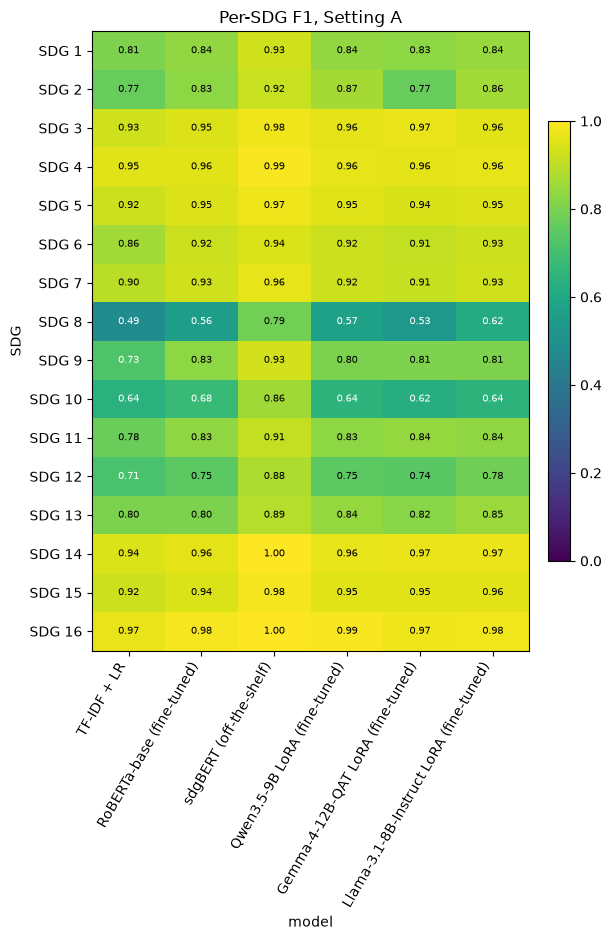

In [16]:
def per_sdg_table(per_model, support, title, fname):
    df = pd.DataFrame(per_model, index=SDG_FULL)
    df.insert(0, "support", support)
    df.loc["MACRO avg"] = [support.sum()] + [df[c].mean() for c in per_model]
    print(title)
    save_table(df.round(4), fname)
    return df

perA = {n: np.mean([per_class_f1_A(y_te_A, s["test"]) for s in ps.values()], axis=0) for n, ps in A_SCORES.items()}
t3A = per_sdg_table(perA, np.bincount(y_te_A, minlength=K), "Table 3a - per-SDG F1, Setting A (OSDG test)", "table3a_per_sdg_A")

def easy_hard(tbl, nm):
    core = tbl.drop(index="MACRO avg").drop(columns="support")
    m = core.mean(1).sort_values()
    print(f"Setting {nm}: hardest SDGs (mean F1 over models):", ", ".join(f"{i.split(':')[0]} ({v:.2f})" for i, v in m.head(3).items()))
    print(f"Setting {nm}: easiest SDGs:", ", ".join(f"{i.split(':')[0]} ({v:.2f})" for i, v in m.tail(3)[::-1].items()))
    plot_heatmap(core.values, list(core.columns), SDG_LABELS, f"Per-SDG F1, Setting {nm}", OUT / "figs" / f"per_sdg_f1_{nm}.png", vmin=0, vmax=1, xlab="model", ylab="SDG")
    return core.mean(1).values

f_mean_A = easy_hard(t3A, "A")


### 4.2 Setting B (SDGi test, multi-label)
* The threshold is tuned on the SDGi **dev** set (micro-F1) for every model; the top-1 SDG is always kept ("top-1 only" = no threshold).
* Chunk-level models aggregate chunk scores with the dev-selected aggregation (`first` / `max` / `mean`).
* **OSDG-trained** rows and off-the-shelf rows are transfer results (threshold calibrated on SDGi-dev). Test metrics use only English documents.

#### 4.2.1 Table 2 and 2b — headline metrics

**Table 2** is the main result of Setting B: every model in `B_SCORES` is scored on the English SDGi test set, one prediction per document. It covers SDGi-trained models (in-domain), OSDG-trained models (transfer) and the off-the-shelf BERT models, as shown in the "Trained on" column.

SDGi documents are often longer than the 256-512 tokens the transformers can read, so they are split into chunks and each chunk is scored separately. The **aggregation** column says how the chunk scores are combined into one score per document (for example first, mean or max over chunks, chosen on the val set). TF-IDF reads the whole text at once, so its aggregation is "full document".

Each model is evaluated under two decision rules: **tuned**, where an SDG is predicted if its score exceeds a threshold chosen on the val set (always keeping at least the top-1), and **top-1 only**, which shows what a model loses when it can output just one goal.

Columns are micro-F1, macro-F1, micro-precision, micro-recall, Hamming loss (lower is better), subset accuracy and macro-AP, which is threshold-free. RoBERTa is mean over seeds, the other models are single runs.

**Table 2b** repeats the evaluation on the subset of test documents with exactly one gold SDG (about 89% of the test set). Models trained on OSDG-CD learned to output a single goal, so in Table 2 they are partly penalised by documents with several gold goals. Restricting to single-label documents removes this handicap and separates it from the effect of domain shift.

Here only the top-1 prediction is used. With one prediction and one gold label, micro-precision, micro-recall, micro-F1 and subset accuracy are all equal to accuracy, so we report accuracy, macro-F1 and macro-AP. Scores on this subset are higher than in Table 2 for every model, so models should be compared with each other within Table 2b, not against Table 2.

In [17]:
TRAINED_ON_B = {"TF-IDF + LR (SDGi-trained)": "SDGi-train", "RoBERTa-base (SDGi-trained)": "SDGi-train",
                "TF-IDF + LR (OSDG-trained)": "OSDG-train (transfer)", "RoBERTa-base (OSDG-trained)": "OSDG-train (transfer)",
                **{n: "OSDG-train (transfer)" for n in LORA_B}}
KEYS_B = ["micro_f1", "macro_f1", "micro_precision", "micro_recall", "hamming_loss", "subset_acc", "macro_AP"]
B_EVAL = {}
for name, per_seed in B_SCORES.items():
    B_EVAL[name] = {}
    for seed, s in per_seed.items():
        thr, dev_f1 = tune_threshold(Y_sdgi_dev, s["dev"])
        s["thr"] = thr
        s["P_tuned"] = to_sets(s["test"], thr)          # predictions for ALL test rows (used later for subgroups)
        s["P_top1"] = to_sets(s["test"], 2.0)
        S_en = s["test"][EN_MASK]
        B_EVAL[name][seed] = {"tuned": metrics_B(Y_te_en, s["P_tuned"][EN_MASK], S_en),
                              "top1": metrics_B(Y_te_en, s["P_top1"][EN_MASK], S_en), "thr": thr, "dev_micro_f1": dev_f1}
rows = []
for name, ev in B_EVAL.items():
    agg = rep(B_SCORES[name]).get("agg", "full document")
    for rule in ["tuned", "top1"]:
        ms = [e[rule] for e in ev.values()]
        thr_txt = f"thr={np.mean([e['thr'] for e in ev.values()]):.2f} (dev-tuned)" if rule == "tuned" else "top-1 only"
        row = {"Model": name, "Trained on": TRAINED_ON_B.get(name, "OSDG (external)"), "Aggregation": agg, "Decision rule": thr_txt, "#runs": len(ms)}
        row.update({k: fmt_ms([m[k] for m in ms]) for k in KEYS_B})
        rows.append(row)
print(f"Table 2 - Setting B: SDGi test ({MAIN_LANG}), multi-label. Gold labels per document: {Y_te_en.sum(1).mean():.3f} on average; "
      f"{(Y_te_en.sum(1) > 1).mean():.1%} of documents have more than one SDG")
print("Hamming loss: lower is better. macro_AP is threshold-free (compare models without worrying about thresholds).")
save_table(pd.DataFrame(rows).set_index("Model"), "table2_settingB")


# Table 2b: SDGi test, English, documents with exactly ONE gold SDG, top-1 prediction only
single = (Y_te_en.sum(1) == 1)
Y_sub = Y_te_en[single]
y_sub = Y_sub.argmax(1)                                   # the single gold SDG per document
print(f"Single-label subset: {single.sum():,} of {len(single):,} documents ({single.mean():.1%})")

KEYS_B1 = ["accuracy", "macro_f1", "macro_AP"]
rows = []
for name, per_seed in B_SCORES.items():
    ms = []
    for seed, s in per_seed.items():
        P_sub = s["P_top1"][EN_MASK][single]
        S_sub = s["test"][EN_MASK][single]
        m = metrics_B(Y_sub, P_sub, S_sub)
        m["accuracy"] = float((P_sub.argmax(1) == y_sub).mean())   # = micro-P/R/F1 = subset acc when top-1 vs 1 gold label
        ms.append(m)
    row = {"Model": name, "Trained on": TRAINED_ON_B.get(name, "OSDG (external)"), "#runs": len(ms)}
    row.update({k: fmt_ms([m[k] for m in ms]) for k in KEYS_B1})
    rows.append(row)

print("Table 2b - Setting B restricted to single-label SDGi test documents (top-1 prediction)")
print("Here micro-P, micro-R, micro-F1 and subset accuracy all equal accuracy, so only accuracy is reported.")
save_table(pd.DataFrame(rows).set_index("Model"), "table2b_settingB_single")

Table 2 - Setting B: SDGi test (en), multi-label. Gold labels per document: 1.435 on average; 12.1% of documents have more than one SDG
Hamming loss: lower is better. macro_AP is threshold-free (compare models without worrying about thresholds).


,Trained on,Aggregation,Decision rule,#runs,micro_f1,macro_f1,micro_precision,micro_recall,hamming_loss,subset_acc,macro_AP
Model,,,,,,,,,,,
TF-IDF + LR (OSDG-trained),OSDG-train (transfer),full document,thr=0.14 (dev-tuned),1,0.6069,0.5958,0.6531,0.5668,0.0659,0.5865,0.6770
TF-IDF + LR (OSDG-trained),OSDG-train (transfer),full document,top-1 only,1,0.6034,0.5894,0.7347,0.5119,0.0604,0.6342,0.6770
TF-IDF + LR (SDGi-trained),SDGi-train,full document,thr=0.17 (dev-tuned),1,0.7510,0.7444,0.7701,0.7329,0.0436,0.6870,0.8309
TF-IDF + LR (SDGi-trained),SDGi-train,full document,top-1 only,1,0.7115,0.7046,0.8663,0.6036,0.0439,0.7585,0.8309
RoBERTa-base (OSDG-trained),OSDG-train (transfer),mean,thr=0.22 (dev-tuned),3,0.6052,0.6015,0.6830,0.5434,0.0637,0.5921,0.6238
RoBERTa-base (OSDG-trained),OSDG-train (transfer),mean,top-1 only,3,0.6023,0.5971,0.7333,0.5110,0.0605,0.6401,0.6238
RoBERTa-base (SDGi-trained),SDGi-train,first,thr=0.40 (dev-tuned),3,0.7360,0.7274,0.7345,0.7377,0.0475,0.7157,0.7957
RoBERTa-base (SDGi-trained),SDGi-train,first,top-1 only,3,0.7035,0.7009,0.8566,0.5969,0.0451,0.7513,0.7957
sdgBERT (off-the-shelf),OSDG (external),first,thr=0.14 (dev-tuned),1,0.5992,0.5933,0.6391,0.5639,0.0677,0.5451,0.6488


Single-label subset: 848 of 965 documents (87.9%)
Table 2b - Setting B restricted to single-label SDGi test documents (top-1 prediction)
Here micro-P, micro-R, micro-F1 and subset accuracy all equal accuracy, so only accuracy is reported.


,Trained on,#runs,accuracy,macro_f1,macro_AP
Model,,,,,
TF-IDF + LR (OSDG-trained),OSDG-train (transfer),1,0.7217,0.7139,0.8427
TF-IDF + LR (SDGi-trained),SDGi-train,1,0.8632,0.8669,0.9241
RoBERTa-base (OSDG-trained),OSDG-train (transfer),3,0.7284,0.7357,0.7860
RoBERTa-base (SDGi-trained),SDGi-train,3,0.8550,0.8568,0.8728
sdgBERT (off-the-shelf),OSDG (external),1,0.7064,0.7065,0.7950
Qwen3.5-9B LoRA (OSDG-trained),OSDG-train (transfer),1,0.8267,0.8308,0.9169
Gemma-4-12B-QAT LoRA (OSDG-trained),OSDG-train (transfer),1,0.8196,0.8178,0.9144
Llama-3.1-8B-Instruct LoRA (OSDG-trained),OSDG-train (transfer),1,0.7712,0.7745,0.8364


#### 4.2.2 Per-SDG F1 on SDGI dataset
**Table 3b'** repeats the per-SDG evaluation on the English test documents with exactly one gold SDG, using top-1 predictions. This removes the label-cardinality handicap of the single-label models, as in Table 2b. Some SDGs have very few such documents, so their scores are noisy.

Table 3b - per-SDG F1, Setting B (SDGi test, English documents)


,support,TF-IDF + LR (OSDG-trained),TF-IDF + LR (SDGi-trained),RoBERTa-base (OSDG-trained),RoBERTa-base (SDGi-trained),sdgBERT (off-the-shelf),Qwen3.5-9B LoRA (OSDG-trained),Gemma-4-12B-QAT LoRA (OSDG-trained),Llama-3.1-8B-Instruct LoRA (OSDG-trained)
1: No Poverty,89.0,0.6235,0.7407,0.6356,0.7290,0.6279,0.6623,0.6323,0.6329
2: Zero Hunger,63.0,0.7339,0.7477,0.6308,0.7071,0.6847,0.7429,0.7321,0.5920
3: Good Health and Well-being,91.0,0.5714,0.7273,0.6333,0.7492,0.6331,0.6712,0.6531,0.6522
4: Quality Education,94.0,0.7399,0.7684,0.7305,0.7152,0.6957,0.7436,0.7296,0.7273
5: Gender Equality,46.0,0.5000,0.7317,0.5331,0.6723,0.4561,0.6444,0.6105,0.5957
6: Clean Water and Sanitation,56.0,0.6667,0.7664,0.6724,0.7449,0.6909,0.7222,0.7103,0.7156
7: Affordable and Clean Energy,42.0,0.5714,0.6000,0.6052,0.6882,0.5741,0.6933,0.6842,0.6500
8: Decent Work and Economic Growth,129.0,0.5543,0.7209,0.5664,0.7355,0.5688,0.6321,0.6476,0.6311
"9: Industry, Innovation and Infrastructure",108.0,0.6211,0.7404,0.6008,0.7725,0.6321,0.6480,0.6588,0.5660
10: Reduced Inequalities,122.0,0.2993,0.8122,0.4816,0.7492,0.4954,0.6448,0.5614,0.5269


Setting B: hardest SDGs (mean F1 over models): 10 (0.57), 14 (0.59), 5 (0.59)
Setting B: easiest SDGs: 4 (0.73), 6 (0.71), 11 (0.70)


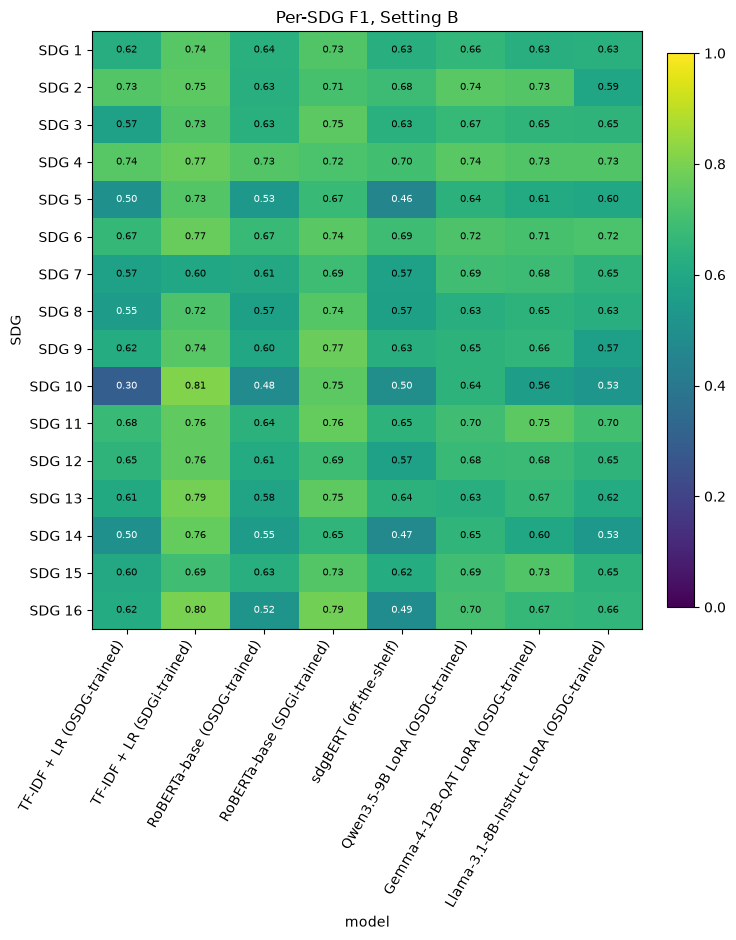

Setting B: Spearman(F1 per SDG, #training documents) = 0.05 (p=0.863)
Table 3b' - per-SDG F1, Setting B (single-label subset: 848 of 965 English SDGi test documents, top-1)


,support,TF-IDF + LR (OSDG-trained),TF-IDF + LR (SDGi-trained),RoBERTa-base (OSDG-trained),RoBERTa-base (SDGi-trained),sdgBERT (off-the-shelf),Qwen3.5-9B LoRA (OSDG-trained),Gemma-4-12B-QAT LoRA (OSDG-trained),Llama-3.1-8B-Instruct LoRA (OSDG-trained)
1: No Poverty,59.0,0.7500,0.8983,0.7880,0.8348,0.7586,0.8276,0.7805,0.7619
2: Zero Hunger,44.0,0.8333,0.8395,0.7465,0.8691,0.7407,0.8916,0.8764,0.6667
3: Good Health and Well-being,51.0,0.7706,0.8462,0.8542,0.8770,0.8387,0.8800,0.8317,0.8842
4: Quality Education,56.0,0.7895,0.8571,0.8310,0.8724,0.8119,0.9245,0.8929,0.8679
5: Gender Equality,28.0,0.6923,0.8966,0.6911,0.8467,0.6849,0.8182,0.7200,0.7123
6: Clean Water and Sanitation,40.0,0.8000,0.8916,0.7928,0.8512,0.8182,0.8222,0.8222,0.8261
7: Affordable and Clean Energy,21.0,0.7241,0.8235,0.7632,0.7862,0.6562,0.8571,0.8400,0.7778
8: Decent Work and Economic Growth,79.0,0.6588,0.8047,0.6827,0.8197,0.6528,0.7724,0.7867,0.7755
"9: Industry, Innovation and Infrastructure",61.0,0.7966,0.8522,0.7661,0.8744,0.7257,0.8293,0.8793,0.7736
10: Reduced Inequalities,82.0,0.2366,0.8784,0.5842,0.8554,0.5694,0.8116,0.7132,0.6825


Setting B-single: hardest SDGs (mean F1 over models): 10 (0.67), 14 (0.71), 8 (0.74)
Setting B-single: easiest SDGs: 4 (0.86), 3 (0.85), 13 (0.84)


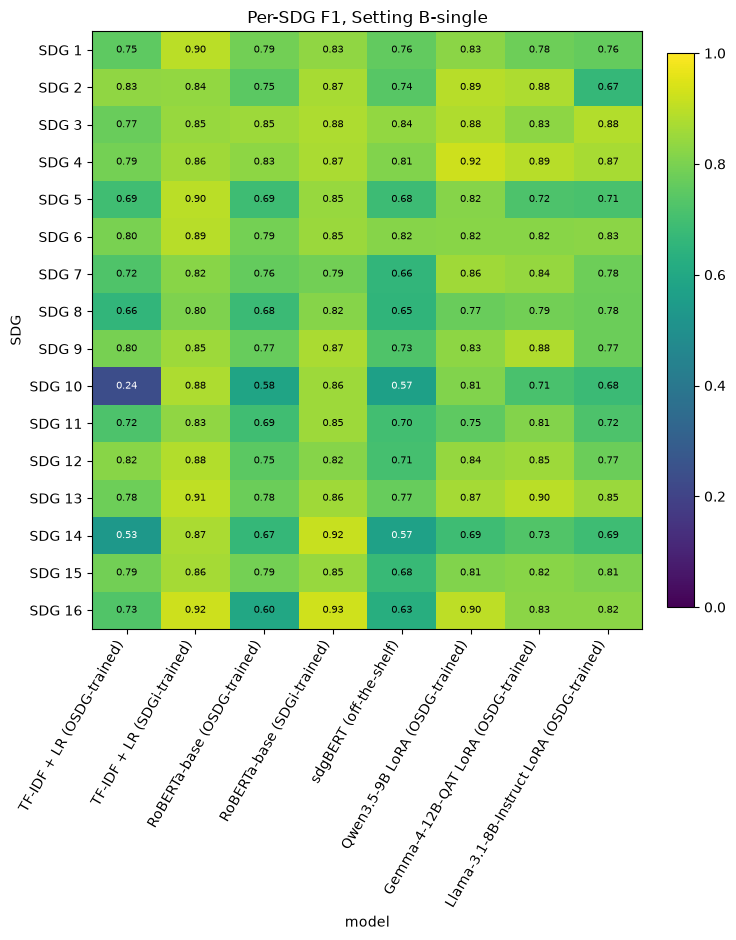

Single-label subset: Spearman(F1 per SDG, #training documents) = 0.12 (p=0.649). SDGs with support 0 get F1 = 0 here, read those rows with care.


In [18]:
# Table 3b - per-SDG F1, Setting B (full English SDGi test, tuned-threshold predictions)
perB = {n: np.mean([f1_score(Y_te_en, s["P_tuned"][EN_MASK], average=None, zero_division=0) for s in ps.values()], axis=0) for n, ps in B_SCORES.items()}
t3B = per_sdg_table(perB, Y_te_en.sum(0), "Table 3b - per-SDG F1, Setting B (SDGi test, English documents)", "table3b_per_sdg_B")
f_mean_B = easy_hard(t3B, "B")
rho, p = spearmanr(f_mean_B, Y_sdgi_tr.sum(0))
print(f"Setting B: Spearman(F1 per SDG, #training documents) = {rho:.2f} (p={p:.3f})")

# Table 3b' - per-SDG F1, Setting B restricted to English test documents with exactly ONE gold SDG (top-1 predictions)
single = (Y_te_en.sum(1) == 1)
Y_sub = Y_te_en[single]
perB_single = {n: np.mean([f1_score(Y_sub, s["P_top1"][EN_MASK][single], average=None, zero_division=0) for s in ps.values()], axis=0)
               for n, ps in B_SCORES.items()}
t3B_single = per_sdg_table(perB_single, Y_sub.sum(0),
                           f"Table 3b' - per-SDG F1, Setting B (single-label subset: {single.sum()} of {len(single)} English SDGi test documents, top-1)",
                           "table3b_per_sdg_B_single")
f_mean_B_single = easy_hard(t3B_single, "B-single")
rho, p = spearmanr(f_mean_B_single, Y_sdgi_tr.sum(0))
print(f"Single-label subset: Spearman(F1 per SDG, #training documents) = {rho:.2f} (p={p:.3f}). "
      f"SDGs with support 0 get F1 = 0 here, read those rows with care.")

## 5. Plain LLMs (zero-/few-shot) served locally by LM Studio

This section tests general-purpose LLMs with no training at all: the model gets the list of the 17 SDGs and a text, and has to answer with the goal(s) it thinks apply. We run them locally with LM Studio, which exposes an OpenAI-compatible server, so no paid API is needed. Three open-weight models in 4-bit (Q4) builds that fit an 8 GB GPU are compared: Llama-3.1-8B-Instruct, Qwen3.5-9B and Gemma-4-12B-QAT. The same three models are the ones fine-tuned with LoRA in section 3.5, so zero-/few-shot and fine-tuned results can be compared directly.

The setup cell defines the configuration shared by all runs:

- **Subsamples.** Local inference is slow, so the LLMs are evaluated on 500 OSDG paragraphs (stratified by SDG) and 600 English SDGi documents, not on the full test sets. For this reason their numbers are not directly comparable with the other models on the full sets.
- **Prompts.** Setting A is run zero-shot and few-shot (2 examples per SDG, each cut to 100 words). Setting B is run zero-shot only. SDGi documents are cut to their first 600 words.
- **Deterministic output.** Temperature is 0 and the answer is constrained to a JSON schema. Thinking mode is switched off for reasoning models.
- **Caching.** Every answer is saved to disk, so a crash or a re-run does not repeat requests. If the server is not reachable, the notebook uses cached answers only.

In [19]:
import hashlib
import requests

# ------------------------------------------------------------------ LLM CONFIG
RUN_LLM = True                                 # True: use the LM Studio server for new runs; False: only read cached answers
LLM_BASE_URL = "http://127.0.0.1:1234/v1"      # LM Studio (127.0.0.1 instead of "localhost" avoids a ~2 s delay per request on Windows). Ollama: http://127.0.0.1:11434/v1
# Substrings of the model ids shown by LM Studio (matched case-insensitively against the server's model list, printed below).
# Suggested for an 8 GB GPU (Q4 builds): Qwen3.5-9B (best all-round at this size), Gemma 4 12B QAT (slower, strong instruction following,
# ~6.6 GB: may spill to RAM), optionally Llama 3.1 8B Instruct as an older reference model. Pick 2-3 and justify the choice in the report.
LLM_MODELS = ["meta-llama-3.1-8b-instruct", "qwen/qwen3.5-9b", "google/gemma-4-12b-qat"]
LLM_N_A, LLM_N_B = 500, 600                   # subsample sizes: OSDG paragraphs (stratified by SDG) / SDGi English documents
LLM_FEWSHOT_PER_SDG = 2                      # few-shot examples per SDG (Setting A)
LLM_FEWSHOT_WORDS = 100                        # each few-shot example is cut to this many words
LLM_DOC_WORDS = 600                            # SDGi documents are cut to their first N words for the LLM
LLM_TEMPERATURE, LLM_MAX_TOKENS, LLM_TIMEOUT = 0.0, 400, 600
LLM_USE_SCHEMA = True                          # JSON-schema constrained output (falls back to plain text + parsing if the server rejects it)
LLM_EXTRA_BODY = {}                            # extra request fields, e.g. {"chat_template_kwargs": {"enable_thinking": False}} (only if your server supports it)
LLM_CHECK_N = 10
LLM_NO_THINK = {"chat_template_kwargs": {"enable_thinking": False}}   # switches off the thinking mode of reasoning models (ignored by others); not in the cache key                               # size of the quick check on DEV data

LLM_DIR = OUT / "llm"; LLM_DIR.mkdir(parents=True, exist_ok=True)
LLM_STATE = {"schema": LLM_USE_SCHEMA, "fallbacks": 0, "trimmed": 0, "rejected": 0}
LLM_RESULTS = {}                               # (model_id, "A-zero" | "A-few" | "B-zero") -> results

def server_models():
    try:
        r = requests.get(LLM_BASE_URL + "/models", timeout=5); r.raise_for_status()
        js = r.json(); items = js.get("data") or js.get("models") or []
        ids = [m.get("id") or m.get("key") or "" for m in items]
        return [m for m in ids if m and "embed" not in m.lower()]
    except Exception as e:
        print(f"LM Studio server not reachable at {LLM_BASE_URL} ({type(e).__name__}). Only answers already cached in {LLM_DIR} will be used.")
        return None

# free the GPU memory held by this notebook (cached HF models of the later analyses are re-loaded lazily if needed)
if "_MODEL_CACHE" in globals():
    _MODEL_CACHE.clear()
gc.collect()
if DEVICE == "cuda":
    torch.cuda.empty_cache()

avail = server_models() if RUN_LLM else None
LLM_LIVE = set()                  # model ids that can be queried now
LLM_IDS = []                      # models used in the tables: live ones + models that only have cached answers
if avail is not None:
    print("models offered by the server:", avail)
for sub in LLM_MODELS:
    hits = [m for m in (avail or []) if sub.lower() in m.lower()]
    if hits:
        LLM_IDS.append(hits[0]); LLM_LIVE.add(hits[0]); print(f"  '{sub}' -> {hits[0]}")
    elif any(LLM_DIR.glob(f"{safe(sub)}__*__*.jsonl")):
        LLM_IDS.append(sub); print(f"  '{sub}': not on the server, using cached answers only")
    else:
        print(f"  '{sub}': no server match and no cache. Download it in LM Studio (Discover tab) or adjust the substring.")
print("LLM models used:", LLM_IDS, "| live:", sorted(LLM_LIVE))


models offered by the server: ['google/gemma-4-12b-qat', 'meta-llama-3.1-8b-instruct', 'qwen/qwen3.5-9b']
  'meta-llama-3.1-8b-instruct' -> meta-llama-3.1-8b-instruct
  'qwen/qwen3.5-9b' -> qwen/qwen3.5-9b
  'google/gemma-4-12b-qat' -> google/gemma-4-12b-qat
LLM models used: ['meta-llama-3.1-8b-instruct', 'qwen/qwen3.5-9b', 'google/gemma-4-12b-qat'] | live: ['google/gemma-4-12b-qat', 'meta-llama-3.1-8b-instruct', 'qwen/qwen3.5-9b']


### 5.1 Subsamples, prompts and server calls

This cell prepares everything the LLM runs need before any request is sent.

**Fixed test subsamples.** Drawn once with a fixed seed, so every model is scored on the same items. Setting A uses about 500 OSDG test paragraphs, stratified so each SDG contributes equally. Setting B uses 600 random English SDGi test documents.

**Prompts.** Each prompt contains the list of SDGs and the text to classify.
- *Setting A* asks for the one goal the paragraph mainly addresses. The few-shot version adds 2 examples per SDG, taken from high-agreement training paragraphs and cut to 100 words.
- *Setting B* asks for 1 to 3 goals, most important first, and only goals the document clearly addresses. Documents are cut to their first 600 words.

Answers must be JSON (`{"sdg": 7}` or `{"sdgs": [7, 13]}`), enforced by a schema that only allows valid SDG numbers. A prompt hash is part of the cache file name, so changing a prompt or setting never reuses old answers.

**Server calls.** `call_llm` sends one request to LM Studio. If the prompt exceeds the context window, the text is shortened and retried. If the server rejects the schema, the call continues without it and the answer is parsed from plain text. A request still rejected after 4 attempts is stored as an empty answer (a parse failure), so one bad document does not stop the run. The parsers extract the SDG number(s) and return `None` if the answer is unusable. Every answer is saved to a `.jsonl` file, so an interrupted run can be resumed.


In [20]:
# ---- fixed subsamples of the TEST sets (the same items are used for every model)
rng_llm = np.random.default_rng(SPLIT_SEED)
per_cls = max(1, LLM_N_A // K)
idx_A = np.sort(np.concatenate([rng_llm.choice(np.where(y_te_A == k)[0], min(per_cls, int((y_te_A == k).sum())), replace=False) for k in range(K)]))
en_idx = np.where(EN_MASK)[0]
idx_B = np.sort(rng_llm.choice(en_idx, min(LLM_N_B, len(en_idx)), replace=False))
print(f"subsample A: {len(idx_A)} OSDG test paragraphs (~{per_cls} per SDG) | subsample B: {len(idx_B)} English SDGi test documents "
      f"({(Y_sdgi_te[idx_B].sum(1) > 1).mean():.1%} multi-label)")

# ---- few-shot examples: one high-agreement training paragraph per SDG (fixed by SPLIT_SEED)
def cut_words(t, n):
    w = str(t).split()
    return " ".join(w[:n]) + (" ..." if len(w) > n else "")

top_train = osdg_train.sort_values("agreement", ascending=False).groupby("y").head(25)
shots_df = pd.concat([top_train[top_train.y == k].sample(min(LLM_FEWSHOT_PER_SDG, int((top_train.y == k).sum())), random_state=SPLIT_SEED) for k in range(K)])
SHOTS = [(cut_words(r.text, LLM_FEWSHOT_WORDS), int(r.sdg_id)) for r in shots_df.sample(frac=1, random_state=SPLIT_SEED).itertuples()]

# ---- prompts and JSON schemas
GOAL_LIST = "\n".join(f"{s} {SDG_NAMES[s]}" for s in COMMON)
SYS = "You are an expert annotator for the United Nations Sustainable Development Goals (SDGs). You answer only with JSON."
SCHEMA_A = {"type": "object", "properties": {"sdg": {"type": "integer", "enum": COMMON}}, "required": ["sdg"], "additionalProperties": False}
SCHEMA_B = {"type": "object", "properties": {"sdgs": {"type": "array", "items": {"type": "integer", "enum": COMMON}, "minItems": 1, "maxItems": 3, "uniqueItems": True}},
            "required": ["sdgs"], "additionalProperties": False}

def user_A(text, shots=None):
    ex = ""
    if shots:
        ex = "Examples:\n" + "\n\n".join('Text: """%s"""\nAnswer: {"sdg": %d}' % (t, s) for t, s in shots) + "\n\n"
    return ("Goals:\n" + GOAL_LIST + "\n\nTask: decide which ONE goal the text below mainly addresses.\n"
            'Return ONLY JSON like {"sdg": 7}.\n\n' + ex + 'Text: """' + str(text) + '"""\nAnswer:')

def user_B(text):
    return ("Goals:\n" + GOAL_LIST + "\n\nTask: decide which goals the document below addresses. List between 1 and 3 goals, the most important first, "
            "and include a goal only if the document clearly addresses it.\n"
            'Return ONLY JSON like {"sdgs": [7, 13]}.\n\nDocument: """' + cut_words(text, LLM_DOC_WORDS) + '"""\nAnswer:')

LLM_PHASH = hashlib.md5(json.dumps([SYS, GOAL_LIST, SHOTS, SCHEMA_A, SCHEMA_B, user_A("T"), user_B("T"), LLM_TEMPERATURE, LLM_MAX_TOKENS,
                                    LLM_DOC_WORDS, LLM_USE_SCHEMA, LLM_EXTRA_BODY], sort_keys=True, default=str).encode()).hexdigest()[:8]
print("prompt hash (cache key):", LLM_PHASH)

# ---- server call and parsing
HTTP = requests.Session()                          # reuse the TCP connection

def shrink_prompt(user, frac=0.6):
    """Cut the LAST text/document of the prompt to `frac` of its words (goal list, instructions and few-shot examples stay intact)."""
    for marker in ('Document: """', 'Text: """'):
        k = user.rfind(marker)
        if k >= 0:
            head, body = user[:k + len(marker)], user[k + len(marker):].rsplit('"""', 1)[0]
            w = body.split()
            return head + " ".join(w[:max(30, int(len(w) * frac))]) + '"""\nAnswer:'
    return user[:int(len(user) * 0.8)]

def call_llm(model_id, user, schema):
    """One chat completion.
    * HTTP 400 because the prompt does not fit the loaded context window -> shorten the document and retry (counted in LLM_STATE['trimmed']);
      the JSON schema stays ON.
    * HTTP 400 that really complains about the schema/response_format -> continue without schema (counted in LLM_STATE['fallbacks']).
    * If a request is still rejected after 4 attempts it is returned as an EMPTY answer (= parse failure, counted in LLM_STATE['rejected']),
      so one pathological document never stops a long run. Transport errors (server down) still raise."""
    cur, last, trimmed = user, None, False
    for attempt in range(4):
        body = {"model": model_id, "messages": [{"role": "system", "content": SYS}, {"role": "user", "content": cur}],
                "temperature": LLM_TEMPERATURE, "max_tokens": LLM_MAX_TOKENS, "stream": False, **LLM_NO_THINK, **LLM_EXTRA_BODY}
        if LLM_STATE["schema"]:
            body["response_format"] = {"type": "json_schema", "json_schema": {"name": "sdg_answer", "strict": True, "schema": schema}}
        try:
            r = HTTP.post(LLM_BASE_URL + "/chat/completions", json=body, timeout=LLM_TIMEOUT)
            if r.status_code == 400:
                msg = r.text.lower()
                print(f"  [HTTP 400, attempt {attempt + 1}] {r.text[:160]}")
                if any(k in msg for k in ("context", "n_ctx", "n_keep", "too long", "token")) and "response_format" not in msg:
                    cur, trimmed = shrink_prompt(cur), True
                    continue
                if LLM_STATE["schema"] and any(k in msg for k in ("response_format", "json_schema", "schema", "grammar")):
                    LLM_STATE["schema"], LLM_STATE["fallbacks"] = False, LLM_STATE["fallbacks"] + 1
                    print("  server rejected the JSON schema -> continuing without it")
                    continue
                cur, trimmed = shrink_prompt(cur), True        # unknown 400: try a shorter prompt
                continue
            r.raise_for_status()
            if trimmed:
                LLM_STATE["trimmed"] += 1
            return r.json()["choices"][0]["message"].get("content") or ""
        except requests.RequestException as e:
            last = e; time.sleep(2 ** attempt)
    if last is None:                                           # only 400s: give up on this item, keep the run going
        LLM_STATE["rejected"] += 1
        return ""
    raise RuntimeError(f"LM Studio request failed after retries: {last}")

def strip_think(t):
    return re.sub(r"<think>.*?</think>", "", t or "", flags=re.S).strip()

def parse_json_obj(t):
    t = strip_think(t)
    cands = [t]
    m = re.search(r"\{.*\}", t, flags=re.S)
    if m:
        cands.append(m.group(0))
    for c in cands:
        try:
            return json.loads(c)
        except Exception:
            pass
    return None

def parse_A(raw):
    """-> SDG number or None."""
    o = parse_json_obj(raw)
    v = o.get("sdg") if isinstance(o, dict) else None
    if v is None:
        m = re.search(r'"?sdg"?\s*[:=]\s*(\d+)', strip_think(raw), re.I)
        v = m.group(1) if m else None
    try:
        v = int(v)
    except (TypeError, ValueError):
        return None
    return v if v in sdg2idx else None

def parse_B(raw):
    """-> list of SDG numbers (1-3) or None."""
    o = parse_json_obj(raw)
    v = o.get("sdgs") if isinstance(o, dict) else None
    if v is None:
        m = re.search(r'"?sdgs"?\s*[:=]\s*\[([^\]]*)\]', strip_think(raw), re.I)
        v = re.findall(r"\d+", m.group(1)) if m else None
    if not isinstance(v, list):
        return None
    out = []
    for x in v:
        try:
            x = int(x)
        except (TypeError, ValueError):
            continue
        if x in sdg2idx and x not in out:
            out.append(x)
    return out[:3] or None

def make_job(task, mode):
    """-> (prompt builder(i), schema, parser) for a task/mode; i indexes the TEST set."""
    if task == "A":
        shots = SHOTS if mode == "few" else None
        return (lambda i: user_A(osdg_test.text.iloc[i], shots)), SCHEMA_A, parse_A
    return (lambda i: user_B(sdgi_test.text.iloc[i])), SCHEMA_B, parse_B

def run_llm(model_id, task, mode, idxs):
    """Cached run over test indices. One JSON line per item; finished items are never recomputed."""
    path = LLM_DIR / f"{safe(model_id)}__{task}-{mode}__{LLM_PHASH}.jsonl"
    done = {}
    if path.exists():
        for line in open(path, encoding="utf-8"):
            r = json.loads(line); done[r["i"]] = r
    build, schema, parser = make_job(task, mode)
    todo = [int(i) for i in idxs if int(i) not in done]
    if todo and model_id in LLM_LIVE:
        LLM_STATE["schema"] = LLM_USE_SCHEMA
        with open(path, "a", encoding="utf-8") as f:
            for i in tqdm(todo, desc=f"{model_id} {task}-{mode}"):
                t0 = time.time()
                raw = call_llm(model_id, build(i), schema)
                pred = parser(raw)
                rec = {"i": i, "raw": raw, "pred": pred, "ok": pred is not None, "lat": time.time() - t0}
                f.write(json.dumps(rec, ensure_ascii=False) + "\n"); f.flush(); done[i] = rec
    return [done[int(i)] for i in idxs if int(i) in done]      # shorter than idxs if some answers are missing and the model cannot be queried


subsample A: 496 OSDG test paragraphs (~31 per SDG) | subsample B: 600 English SDGi test documents (12.8% multi-label)
prompt hash (cache key): b21cdb7a


### 5.2 Full run (resumable: finished items are read from `outputs/llm/`)

For each model we run three configurations: Setting A zero-shot, Setting A few-shot and Setting B zero-shot. Answers come from the cache when available, and from the server otherwise. If a run is incomplete and the model cannot be queried, it is skipped.

In [21]:
for mid in LLM_IDS:
    for task, mode, idxs in [("A", "zero", idx_A), ("A", "few", idx_A), ("B", "zero", idx_B)]:
        recs = run_llm(mid, task, mode, idxs)
        if len(recs) < len(idxs):
            print(f"  [{mid} {task}-{mode}] incomplete ({len(recs)}/{len(idxs)} answers) and the model cannot be queried -> skipped")
            continue
        fail = float(np.mean([not r["ok"] for r in recs])); lat = float(np.mean([r["lat"] for r in recs]))
        if task == "A":
            res = {"pred": np.array([sdg2idx[r["pred"]] if r["ok"] else -1 for r in recs])}
        else:
            P = np.zeros((len(recs), K), dtype=np.int64)
            for j, r in enumerate(recs):
                for s in (r["pred"] or []):
                    P[j, sdg2idx[s]] = 1
            res = {"P": P}
        res.update(fail=fail, lat=lat, n=len(recs))
        LLM_RESULTS[(mid, f"{task}-{mode}")] = res
        print(f"{mid} | {task}-{mode}: n={len(recs)} | parse failures {fail:.1%} | mean latency {lat:.2f}s")
        EFF_ROWS.append({"model": f"{mid} ({task}-{mode})", "task": "plain LLM, no training (LM Studio)", "params": np.nan, "train_time_s": 0.0,
                         "infer_s_per_1k": lat * 1000, "peak_gpu_gib": np.nan, "device": f"{gpu_name} via LM Studio"})
if LLM_STATE["fallbacks"]:
    print("NOTE: the server rejected the JSON schema; answers were parsed from plain text (mention this in the report).")
if not LLM_RESULTS:
    print("No LLM results (server off and nothing cached): the LLM tables below are skipped.")


meta-llama-3.1-8b-instruct | A-zero: n=496 | parse failures 0.0% | mean latency 0.33s
meta-llama-3.1-8b-instruct | A-few: n=496 | parse failures 0.0% | mean latency 0.38s
meta-llama-3.1-8b-instruct | B-zero: n=600 | parse failures 0.0% | mean latency 0.85s
qwen/qwen3.5-9b | A-zero: n=496 | parse failures 0.0% | mean latency 0.54s
qwen/qwen3.5-9b | A-few: n=496 | parse failures 0.0% | mean latency 0.59s
qwen/qwen3.5-9b | B-zero: n=600 | parse failures 0.0% | mean latency 1.07s
google/gemma-4-12b-qat | A-zero: n=496 | parse failures 0.0% | mean latency 2.46s
google/gemma-4-12b-qat | A-few: n=496 | parse failures 0.0% | mean latency 4.59s
google/gemma-4-12b-qat | B-zero: n=600 | parse failures 0.0% | mean latency 3.84s


### 5.3 Tables 1h and 2e: plain LLMs vs. the other models on the common subsamples

The plain LLMs were run only on the fixed subsamples (500 OSDG paragraphs, 600 English SDGi documents), so every other model is re-scored on the same items here.

Both tables report accuracy (in Setting B, exact-match subset accuracy), hit rate (share of items where at least one predicted SDG is in the gold set), macro-F1, macro-precision, macro-recall and the average number of predicted labels. In Setting A the last column is the share of parsable answers, so it drops below 1 when an LLM gives an invalid answer. A "parse failures" column gives the share of unusable LLM answers.

**Table 1h (Setting A).** Supervised models predict the argmax class. LLM parse failures count as errors. The best LLM configuration by macro-F1 is also shown as a row-normalised confusion matrix.

**Table 2e (Setting B).** Supervised models use their dev-tuned threshold, while the LLMs output their own set of 1 to 3 goals, so the decision rules differ between rows.


Table 1h - Setting A on the common stratified subsample of 496 OSDG test paragraphs (LLM invalid answers count as errors)


,Type,n,parse failures,accuracy,hit_rate,macro_f1,macro_precision,macro_recall,avg_pred_labels
Model,,,,,,,,,
TF-IDF + LR,trained / pre-trained,496,-,0.8085,0.8085,0.8024,0.8126,0.8085,1.0000
RoBERTa-base (fine-tuned),trained / pre-trained,496,-,0.8347,0.8347,0.8284,0.8299,0.8347,1.0000
sdgBERT (off-the-shelf),trained / pre-trained,496,-,0.9194,0.9194,0.9167,0.9236,0.9194,1.0000
Qwen3.5-9B LoRA (fine-tuned),trained / pre-trained,496,-,0.8327,0.8327,0.8276,0.8298,0.8327,1.0000
Gemma-4-12B-QAT LoRA (fine-tuned),trained / pre-trained,496,-,0.8407,0.8407,0.8343,0.8413,0.8407,1.0000
Llama-3.1-8B-Instruct LoRA (fine-tuned),trained / pre-trained,496,-,0.8448,0.8448,0.8397,0.8436,0.8448,1.0000
meta-llama-3.1-8b-instruct [zero-shot],plain LLM (LM Studio),496,0.0%,0.4859,0.4859,0.4672,0.6607,0.4859,1.0000
"meta-llama-3.1-8b-instruct [few-shot, 2/SDG]",plain LLM (LM Studio),496,0.0%,0.5645,0.5645,0.5621,0.6796,0.5645,1.0000
qwen/qwen3.5-9b [zero-shot],plain LLM (LM Studio),496,0.0%,0.6935,0.6935,0.6934,0.7379,0.6935,1.0000


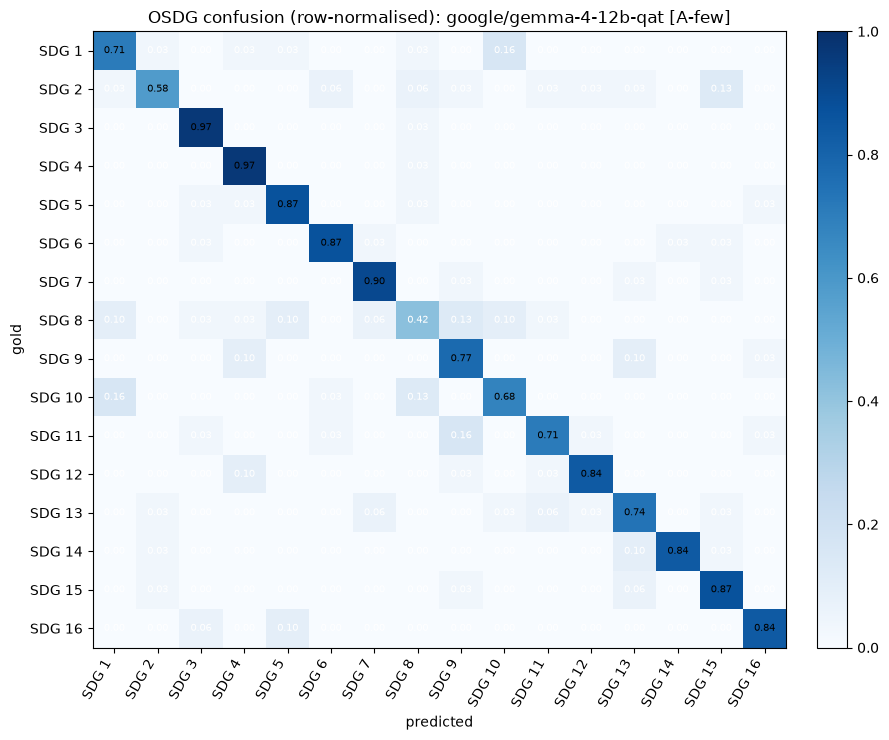

best LLM configuration: ('google/gemma-4-12b-qat', 'A-few') | invalid answers: 0 of 496
Table 2e - Setting B on the common random subsample of 600 English SDGi test documents (supervised models: dev-tuned threshold; LLM: its own label set)


,Type,n,parse failures,accuracy,hit_rate,macro_f1,macro_precision,macro_recall,avg_pred_labels
Model,,,,,,,,,
TF-IDF + LR (OSDG-trained),trained / pre-trained,600,-,0.5817,0.7883,0.5909,0.6898,0.5631,1.2650
TF-IDF + LR (SDGi-trained),trained / pre-trained,600,-,0.6933,0.9000,0.7453,0.8106,0.7020,1.3417
RoBERTa-base (OSDG-trained),trained / pre-trained,600,-,0.5778,0.7706,0.6007,0.7284,0.5368,1.1611
RoBERTa-base (SDGi-trained),trained / pre-trained,600,-,0.7206,0.8928,0.7264,0.7304,0.7265,1.4344
sdgBERT (off-the-shelf),trained / pre-trained,600,-,0.5400,0.7883,0.5915,0.6599,0.5551,1.2800
Qwen3.5-9B LoRA (OSDG-trained),trained / pre-trained,600,-,0.6867,0.8517,0.6791,0.8390,0.5862,1.0850
Gemma-4-12B-QAT LoRA (OSDG-trained),trained / pre-trained,600,-,0.7050,0.8333,0.6694,0.8325,0.5763,1.0317
Llama-3.1-8B-Instruct LoRA (OSDG-trained),trained / pre-trained,600,-,0.6717,0.7850,0.6330,0.8213,0.5404,1.0133
"meta-llama-3.1-8b-instruct [zero-shot, first 600 words]",plain LLM (LM Studio),600,0.0%,0.0500,0.7517,0.5457,0.7296,0.5581,1.9933


In [22]:
def cfg_label(mid, mode):
    kind = {"A-zero": "zero-shot", "A-few": f"few-shot, {LLM_FEWSHOT_PER_SDG}/SDG", "B-zero": f"zero-shot, first {LLM_DOC_WORDS} words"}[mode]
    return f"{mid}  [{kind}]"

# Unified columns for both Table 1h (Setting A) and Table 2e (Setting B)
HK_COMMON = [
    "accuracy",
    "hit_rate",
    "macro_f1",
    "macro_precision",
    "macro_recall",
    "avg_pred_labels",
]
HK_A = HK_COMMON  # Alias so Table 1j (web chatbots) in the next cell also uses the unified columns
labs = list(range(K))

def hard_A(y, p):
    valid = (p >= 0).astype(float)          # LLM parse failures have p = -1 -> 0 predicted labels
    acc = accuracy_score(y, p)
    return {
        "accuracy": acc,
        "hit_rate": acc,                    # in single-label Setting A, hit_rate == accuracy
        "macro_f1": f1_score(y, p, labels=labs, average="macro", zero_division=0),
        "macro_precision": precision_score(y, p, labels=labs, average="macro", zero_division=0),
        "macro_recall": recall_score(y, p, labels=labs, average="macro", zero_division=0),
        "avg_pred_labels": float(valid.mean()),
    }

def hard_B(Y, P):
    return {
        "accuracy": accuracy_score(Y, P),                                           # exact subset accuracy
        "hit_rate": float(((Y * P).sum(1) > 0).mean()),                             # >=1 predicted SDG is in gold set
        "macro_f1": f1_score(Y, P, average="macro", zero_division=0),
        "macro_precision": precision_score(Y, P, average="macro", zero_division=0),
        "macro_recall": recall_score(Y, P, average="macro", zero_division=0),
        "avg_pred_labels": float(P.sum(1).mean()),
    }

yA = y_te_A[idx_A]
if any(k[1].startswith("A-") for k in LLM_RESULTS):
    rows = []
    for n, ps in A_SCORES.items():
        ms = [hard_A(yA, s["test"][idx_A].argmax(1)) for s in ps.values()]
        rows.append({"Model": n, "Type": "trained / pre-trained", "n": len(yA), "parse failures": "-", **{k: fmt_ms([m[k] for m in ms]) for k in HK_COMMON}})
    for (mid, mode), res in LLM_RESULTS.items():
        if mode.startswith("A-"):
            m = hard_A(yA, res["pred"])
            rows.append({"Model": cfg_label(mid, mode), "Type": "plain LLM (LM Studio)", "n": len(yA), "parse failures": f"{res['fail']:.1%}", **{k: fmt_ms([m[k]]) for k in HK_COMMON}})
    print(f"Table 1h - Setting A on the common stratified subsample of {len(yA)} OSDG test paragraphs (LLM invalid answers count as errors)")
    save_table(pd.DataFrame(rows).set_index("Model"), "table1h_settingA_llm_subsample")

    keys = [k for k in LLM_RESULTS if k[1].startswith("A-")]
    best_cfg = max(keys, key=lambda k: f1_score(yA, LLM_RESULTS[k]["pred"], labels=labs, average="macro", zero_division=0))
    cmL = confusion_matrix(yA, LLM_RESULTS[best_cfg]["pred"], labels=labs)
    plot_heatmap(cmL / cmL.sum(1, keepdims=True).clip(min=1), SDG_LABELS, SDG_LABELS, f"OSDG confusion (row-normalised): {best_cfg[0]} [{best_cfg[1]}]",
                 OUT / "figs" / "confusion_best_llm.png", fmt="{:.2f}", cmap="Blues", vmin=0, vmax=1, xlab="predicted", ylab="gold", figsize=(9, 7.5))
    print(f"best LLM configuration: {best_cfg} | invalid answers: {int((LLM_RESULTS[best_cfg]['pred'] < 0).sum())} of {len(yA)}")

if any(k[1].startswith("B-") for k in LLM_RESULTS):
    Yb = Y_sdgi_te[idx_B]
    rows = []
    for n, ps in B_SCORES.items():
        ms = [hard_B(Yb, s["P_tuned"][idx_B]) for s in ps.values()]
        rows.append({"Model": n, "Type": "trained / pre-trained", "n": len(Yb), "parse failures": "-", **{k: fmt_ms([m[k] for m in ms]) for k in HK_COMMON}})
    for (mid, mode), res in LLM_RESULTS.items():
        if mode.startswith("B-"):
            m = hard_B(Yb, res["P"])
            rows.append({"Model": cfg_label(mid, mode), "Type": "plain LLM (LM Studio)", "n": len(Yb), "parse failures": f"{res['fail']:.1%}", **{k: fmt_ms([m[k]]) for k in HK_COMMON}})
    print(f"Table 2e - Setting B on the common random subsample of {len(Yb)} English SDGi test documents (supervised models: dev-tuned threshold; LLM: its own label set)")
    save_table(pd.DataFrame(rows).set_index("Model"), "table2e_settingB_llm_subsample")

### 5.4 Plain LLMs in Setting B: all 1–3 goals vs. top-1 only

The plain LLMs were asked for 1 to 3 goals, most important first. This table compares their full answer with only the first goal, on the common 600-document subsample.

Listing all goals gives a high hit rate (Qwen 0.95, Gemma 0.96) but low exact-match accuracy and precision, because the models add goals that are not in the gold set (Gemma predicts 2.65 labels per document on average). The prompt allows up to 3 goals and gives no examples of how many are typical, so the models tend to use the allowance and add loosely related goals, even though they are told to include only goals the document clearly addresses. Keeping only the first goal sharply raises accuracy (Qwen 0.35 → 0.78, Gemma 0.09 → 0.79) and precision (above 0.90), at the cost of recall. Llama's top-1 accuracy (0.545) is much lower, so its goal ranking is less reliable.

Zero-shot LLMs therefore over-predict when allowed to list several goals, and top-1 suits them better.

In [23]:
Yb = Y_sdgi_te[idx_B]
top1_rows = []
for mid in LLM_IDS:
    if (mid, "B-zero") not in LLM_RESULTS:
        continue
    # 1. Full set of predicted SDGs (1 to 3 labels)
    m_full = hard_B(Yb, LLM_RESULTS[(mid, "B-zero")]["P"])
    top1_rows.append({"Model": cfg_label(mid, "B-zero") + " (all 1–3)", **{k: fmt_ms([m_full[k]]) for k in HK_COMMON}})
    
    # 2. Top-1 only (first SDG in r["pred"], which the prompt asked to rank "most important first")
    recs = run_llm(mid, "B", "zero", idx_B)
    P_top1 = np.zeros((len(recs), K), dtype=np.int64)
    for j, r in enumerate(recs):
        if r["pred"]:
            P_top1[j, sdg2idx[r["pred"][0]]] = 1
    m_top1 = hard_B(Yb, P_top1)
    top1_rows.append({"Model": cfg_label(mid, "B-zero") + " (top-1 only)", **{k: fmt_ms([m_top1[k]]) for k in HK_COMMON}})

display(pd.DataFrame(top1_rows).set_index("Model"))

,accuracy,hit_rate,macro_f1,macro_precision,macro_recall,avg_pred_labels
Model,,,,,,
"meta-llama-3.1-8b-instruct [zero-shot, first 600 words] (all 1–3)",0.0500,0.7517,0.5457,0.7296,0.5581,1.9933
"meta-llama-3.1-8b-instruct [zero-shot, first 600 words] (top-1 only)",0.5450,0.6150,0.5010,0.7805,0.4395,1.0000
"qwen/qwen3.5-9b [zero-shot, first 600 words] (all 1–3)",0.3517,0.9500,0.6280,0.5833,0.7376,1.9917
"qwen/qwen3.5-9b [zero-shot, first 600 words] (top-1 only)",0.7817,0.9017,0.7339,0.9045,0.6250,1.0000
"google/gemma-4-12b-qat [zero-shot, first 600 words] (all 1–3)",0.0850,0.9567,0.5540,0.4613,0.7527,2.6533
"google/gemma-4-12b-qat [zero-shot, first 600 words] (top-1 only)",0.7850,0.9067,0.7367,0.9130,0.6220,1.0000


### 5.5 Web chatbots

As a further reference I also test web chatbots, which can't be queried through a local server. The items are therefore sent by hand, so I use a smaller subsample of 144 paragraphs (9 per SDG), drawn from the 500-paragraph subsample used for the local LLMs so that the same items can be compared across models. The order is shuffled so batches are not sorted by SDG.

The paragraphs are grouped into 18 batches of 8 numbered texts. Each batch becomes one zero-shot prompt with the SDG list, the same task as in Setting A (one goal per text), and a request for a single JSON object mapping item numbers to goals. Each batch is pasted into a fresh chat to avoid carry-over between batches, and all prompts are saved to one text file.

In [24]:
WEB_PER_SDG, WEB_BATCH_SIZE = 9, 8                  # 9 x 16 = 144 items, 18 batches of 8
rng_web = np.random.default_rng(SPLIT_SEED + 100)
web_sub_pos = np.concatenate([rng_web.choice(np.where(y_te_A[idx_A] == k)[0], min(WEB_PER_SDG, int((y_te_A[idx_A] == k).sum())), replace=False) for k in range(K)])
web_sub_pos = rng_web.permutation(web_sub_pos)       # positions inside idx_A, shuffled so batches are not sorted by SDG
idx_A_web = idx_A[web_sub_pos]
yA_web = y_te_A[idx_A_web]

def build_web_batch_prompt(items):
    header = ("You are an expert annotator for the United Nations Sustainable Development Goals (SDGs). You answer only with JSON.\n\n"
              f"Goals:\n{GOAL_LIST}\n\n"
              "Task: For each numbered text below, decide which ONE goal (1..16) the text mainly addresses.\n"
              'Return ONLY a single JSON object mapping each item number to its integer goal, like {"1": 7, "2": 13}, with no explanation.\n\n')
    body = "\n\n".join(f'[{num}] Text: """{str(osdg_test.text.iloc[ti]).replace(chr(10), " ").strip()}"""' for num, ti in items)
    return header + body + "\n\nAnswer:"

n_batches = int(np.ceil(len(idx_A_web) / WEB_BATCH_SIZE))
blocks = []
for b, start in enumerate(range(0, len(idx_A_web), WEB_BATCH_SIZE), 1):
    items = [(start + j + 1, int(idx_A_web[start + j])) for j in range(min(WEB_BATCH_SIZE, len(idx_A_web) - start))]
    blocks.append(f"==================== BATCH {b} / {n_batches} (items {items[0][0]}..{items[-1][0]}; PASTE INTO A FRESH CHAT) ====================\n{build_web_batch_prompt(items)}\n")
prompt_path = LLM_DIR / f"web_prompts_N{len(idx_A_web)}_zero.txt"
prompt_path.write_text("\n".join(blocks), encoding="utf-8")
print(f"Saved {n_batches} batch prompts (N = {len(idx_A_web)}) to {prompt_path}")


Saved 18 batch prompts (N = 144) to outputs\llm\web_prompts_N144_zero.txt


In [45]:
# Paste the JSON answer of each batch (a dict {"1": 7, ...} or the raw reply text) into the lists below, in batch order.
WEB_CHATBOT_RAW = {
    "ChatGPT (web, zero-shot)": [{"1": 4, "2": 1, "3": 9, "4": 5, "5": 11, "6": 10, "7": 6, "8": 3}, {"9": 10, "10": 9, "11": 9, "12": 13, "13": 1, "14": 12, "15": 1, "16": 10}, {"17": 2, "18": 1, "19": 12, "20": 9, "21": 1, "22": 11, "23": 4, "24": 14}, {"25": 12, "26": 13, "27": 3, "28": 11, "29": 5, "30": 15, "31": 8, "32": 10}, {"33": 15, "34": 8, "35": 9, "36": 10, "37": 3, "38": 4, "39": 5, "40": 11}, {"41": 7, "42": 6, "43": 13, "44": 6, "45": 14, "46": 12, "47": 11, "48": 4}, {"49": 16, "50": 4, "51": 3, "52": 11, "53": 5, "54": 6, "55": 7, "56": 3}, {"57": 10, "58": 1, "59": 7, "60": 3, "61": 8, "62": 14, "63": 15, "64": 5}, {"65": 10, "66": 9, "67": 16, "68": 11, "69": 7, "70": 1, "71": 5, "72": 13}, {"73": 16, "74": 2, "75": 12, "76": 11, "77": 4, "78": 6, "79": 8, "80": 5}, {"81": 16, "82": 12, "83": 7, "84": 14, "85": 13, "86": 16, "87": 7, "88": 1}, {"89": 10, "90": 5, "91": 5, "92": 15, "93": 3, "94": 13, "95": 3, "96": 3}, {"97": 10, "98": 2, "99": 7, "100": 4, "101": 3, "102": 4, "103": 10, "104": 2}, {"105": 8, "106": 11, "107": 14, "108": 14, "109": 14, "110": 7, "111": 15, "112": 4}, {"113": 15, "114": 8, "115": 4, "116": 13, "117": 13, "118": 1, "119": 7, "120": 14}, {"121": 10, "122": 6, "123": 2, "124": 12, "125": 10, "126": 15, "127": 15, "128": 2}, {"129": 5, "130": 1, "131": 7, "132": 2, "133": 13, "134": 2, "135": 12, "136": 4}, {"137": 2, "138": 6, "139": 5, "140": 12, "141": 6, "142": 14, "143": 8, "144": 6}],
    "Gemini Argon(web, zero-shot)": [{"1": 4, "2": 1, "3": 9, "4": 5, "5": 11, "6": 10, "7": 6, "8": 3}, {"9": 16, "10": 9, "11": 9, "12": 13, "13": 1, "14": 12, "15": 1, "16": 10}, {"17": 2, "18": 1, "19": 12, "20": 9, "21": 1, "22": 11, "23": 4, "24": 14}, {"25": 12, "26": 13, "27": 3, "28": 11, "29": 5, "30": 15, "31": 8, "32": 10}, {"33": 15, "34": 8, "35": 9, "36": 4, "37": 3, "38": 4, "39": 5, "40": 11}, {"41": 7, "42": 6, "43": 13, "44": 6, "45": 14, "46": 12, "47": 11, "48": 4}, {"49": 16, "50": 4, "51": 3, "52": 11, "53": 5, "54": 6, "55": 7, "56": 3}, {"57": 10, "58": 1, "59": 7, "60": 3, "61": 8, "62": 14, "63": 15, "64": 5}, {"65": 3, "66": 9, "67": 16, "68": 11, "69": 7, "70": 10, "71": 5, "72": 13}, {"73": 16, "74": 2, "75": 12, "76": 11, "77": 5, "78": 6, "79": 10, "80": 5}, {"81": 16, "82": 12, "83": 7, "84": 14, "85": 13, "86": 16, "87": 7, "88": 1},{"89": 10, "90": 5, "91": 5, "92": 15, "93": 3, "94": 12, "95": 3, "96": 3}, {"97": 1, "98": 2, "99": 7, "100": 4, "101": 3, "102": 4, "103": 10, "104": 2}, {"105": 8, "106": 11, "107": 14, "108": 14, "109": 14, "110": 7, "111": 15, "112": 4}, {"113": 15, "114": 8, "115": 4, "116": 13, "117": 13, "118": 2, "119": 7, "120": 14}, {"121": 10, "122": 6, "123": 2, "124": 12, "125": 10, "126": 15, "127": 15, "128": 2}, {"129": 1, "130": 1, "131": 7, "132": 2, "133": 13, "134": 2, "135": 12, "136": 4}, {"137": 2, "138": 6, "139": 5, "140": 12, "141": 6, "142": 14, "143": 2, "144": 6} ],
    "Deepseek (web, zero-shot)": [
    {"1": 4, "2": 1, "3": 9, "4": 5, "5": 11, "6": 10, "7": 6, "8": 3},
    {"9": 16, "10": 9, "11": 9, "12": 13, "13": 1, "14": 12, "15": 1, "16": 10},
    {"17": 2, "18": 1, "19": 12, "20": 9, "21": 1, "22": 11, "23": 4, "24": 14},
    {"25": 12, "26": 13, "27": 3, "28": 11, "29": 5, "30": 16, "31": 8, "32": 10},
    {"33": 15, "34": 8, "35": 9, "36": 4, "37": 3, "38": 4, "39": 5, "40": 11},
    {"41": 7, "42": 6, "43": 13, "44": 6, "45": 14, "46": 12, "47": 11, "48": 4},
    {"49": 16, "50": 4, "51": 3, "52": 11, "53": 5, "54": 6, "55": 7, "56": 3},
    {"57": 10, "58": 1, "59": 7, "60": 3, "61": 8, "62": 14, "63": 15, "64": 5},
    {"65": 10, "66": 9, "67": 16, "68": 11, "69": 7, "70": 1, "71": 5, "72": 13},
    {"73": 16, "74": 2, "75": 12, "76": 11, "77": 5, "78": 6, "79": 10, "80": 5},
    {"81": 16, "82": 12, "83": 7, "84": 14, "85": 13, "86": 16, "87": 7, "88": 1},
    {"89": 10, "90": 5, "91": 5, "92": 6, "93": 3, "94": 13, "95": 3, "96": 3},
    {"97": 1, "98": 2, "99": 7, "100": 4, "101": 3, "102": 4, "103": 10, "104": 2},
    {"105": 8, "106": 11, "107": 14, "108": 14, "109": 14, "110": 7, "111": 15, "112": 4},
    {"113": 15, "114": 8, "115": 4, "116": 13, "117": 13, "118": 2, "119": 7, "120": 15},
    {"121": 10, "122": 6, "123": 2, "124": 12, "125": 10, "126": 15, "127": 15, "128": 2},
    {"129": 1, "130": 1, "131": 7, "132": 2, "133": 13, "134": 8, "135": 12, "136": 4},
    {"137": 2, "138": 6, "139": 5, "140": 12, "141": 6, "142": 14, "143": 2, "144": 6}
],
}
WEB_CHATBOT_INFO = {"ChatGPT (web, zero-shot)": "model name + date: fill in", "Gemini (web, zero-shot)": "model name + date: fill in", "Deepseek (web, zero-shot)": "model name + date: fill in"}

def parse_web_batches(batch_list, n_items):
    """Merge the batch answers into {item number: SDG}; returns (predictions as class indices or -1, number of invalid answers)."""
    merged = {}
    for item in batch_list:
        if isinstance(item, str):
            m_obj = re.search(r"\{.*\}", item, re.S)
            try: item = json.loads(m_obj.group(0)) if m_obj else {}
            except Exception: item = {}
        if isinstance(item, dict):
            for k_str, v in item.items():
                digits = re.findall(r"\d+", str(k_str))
                if digits: merged[int(digits[0])] = v
    preds, fails = [], 0
    for num in range(1, n_items + 1):
        v = merged.get(num)
        if isinstance(v, dict): v = v.get("sdg")
        try: s = int(re.findall(r"\d+", str(v))[0])
        except Exception: s = -1
        if s in sdg2idx: preds.append(sdg2idx[s])
        else: preds.append(-1); fails += 1
    return np.array(preds), fails

if any(WEB_CHATBOT_RAW.values()):
    save_json({"idx_A_web": idx_A_web.tolist(), "gold_sdg": [COMMON[y] for y in yA_web], "raw": WEB_CHATBOT_RAW, "info": WEB_CHATBOT_INFO},
              LLM_DIR / f"web_chatbots_N{len(idx_A_web)}.json")
    rows = []
    for n, ps in A_SCORES.items():
        ms = [hard_A(yA_web, s["test"][idx_A_web].argmax(1)) for s in ps.values()]
        rows.append({"Model": n, "Type": "trained / pre-trained", "n": len(yA_web), "parse failures": "-", **{k: fmt_ms([m[k] for m in ms]) for k in HK_A}})
    for (mid, mode), res in LLM_RESULTS.items():
        if mode.startswith("A-"):
            p_sub = res["pred"][web_sub_pos]
            rows.append({"Model": cfg_label(mid, mode), "Type": "local LLM (LM Studio)", "n": len(yA_web), "parse failures": f"{float(np.mean(p_sub < 0)):.1%}",
                         **{k: fmt_ms([v]) for k, v in hard_A(yA_web, p_sub).items()}})
    for bot, batches in WEB_CHATBOT_RAW.items():
        if not batches: continue
        preds, fails = parse_web_batches(batches, len(yA_web))
        rows.append({"Model": bot, "Type": "web chatbot (manual)", "n": len(yA_web), "parse failures": f"{fails / len(yA_web):.1%}",
                     **{k: fmt_ms([v]) for k, v in hard_A(yA_web, preds).items()}})
    print(f"Table 1j - exploratory comparison on N = {len(yA_web)} OSDG paragraphs (9 per SDG). Chatbot versions: {WEB_CHATBOT_INFO}")
    save_table(pd.DataFrame(rows).set_index("Model"), "table1j_settingA_web_chatbots")
else:
    print("No web-chatbot answers pasted yet: Table 1j is skipped.")


Table 1j - exploratory comparison on N = 144 OSDG paragraphs (9 per SDG). Chatbot versions: {'ChatGPT (web, zero-shot)': 'model name + date: fill in', 'Gemini (web, zero-shot)': 'model name + date: fill in', 'Deepseek (web, zero-shot)': 'model name + date: fill in'}


,Type,n,parse failures,accuracy,hit_rate,macro_f1,macro_precision,macro_recall,avg_pred_labels
Model,,,,,,,,,
TF-IDF + LR,trained / pre-trained,144,-,0.7917,0.7917,0.7812,0.7924,0.7917,1.0000
RoBERTa-base (fine-tuned),trained / pre-trained,144,-,0.8426,0.8426,0.8329,0.8367,0.8426,1.0000
sdgBERT (off-the-shelf),trained / pre-trained,144,-,0.9236,0.9236,0.9198,0.9280,0.9236,1.0000
Qwen3.5-9B LoRA (fine-tuned),trained / pre-trained,144,-,0.8472,0.8472,0.8367,0.8416,0.8472,1.0000
Gemma-4-12B-QAT LoRA (fine-tuned),trained / pre-trained,144,-,0.8542,0.8542,0.8466,0.8579,0.8542,1.0000
Llama-3.1-8B-Instruct LoRA (fine-tuned),trained / pre-trained,144,-,0.8611,0.8611,0.8547,0.8619,0.8611,1.0000
meta-llama-3.1-8b-instruct [zero-shot],local LLM (LM Studio),144,0.0%,0.5000,0.5000,0.4616,0.6258,0.5000,1.0000
"meta-llama-3.1-8b-instruct [few-shot, 2/SDG]",local LLM (LM Studio),144,0.0%,0.5833,0.5833,0.5776,0.7045,0.5833,1.0000
qwen/qwen3.5-9b [zero-shot],local LLM (LM Studio),144,0.0%,0.6875,0.6875,0.6792,0.7411,0.6875,1.0000


## 6. Qualitative Analysis

### 6.1 Robustness to annotation quality: accuracy by agreement

All analyses use the unfiltered OSDG-CD test split (5,374 paragraphs), which includes the low-agreement paragraphs excluded from the main experiments. The plain zero-shot LLMs are too slow for the full set, so they run on a random third of each agreement bin (1,793 paragraphs).

**Agreement slices (Tables 1e, 1e').** Accuracy per agreement bin (`<.2` to `>=.8`): Table 1e for the trained and pre-trained models on the full set, Table 1e' adding the plain LLMs on the subsample. The gap between the highest and lowest bin shows sensitivity to noisy labels.

**Perturbation (Table 1f).** Accuracy on the original text, with the 3 strongest TF-IDF terms of the gold SDG removed, and with 3 random words removed (control), for all models, including the plain LLMs zero-shot and few-shot. The drop from the original shows reliance on a few keywords. Since the removed terms come from the TF-IDF model, compare drops rather than raw accuracies.

**LoRA effect (Table 1i).** Each base LLM before (zero-shot) and after LoRA fine-tuning, on the common 500-paragraph OSDG subsample.

In [50]:
# ------------------------------------------------------------------ 7c.1 collect predictions on the two robustness sets
LLM_N_PER_BIN = 100              # OLD subsample size: keep unchanged, only used to reuse answers already computed on it
LLM_FRAC_PER_BIN = 1/3          # NEW: plain LLMs are run on this fraction of EACH agreement bin (0.5 = half)
LLM_N_PERT = 100                 # plain LLMs: number of perturbation paragraphs (x 3 conditions)
LLM_EXTRA_MODES = ["zero"]       # add "few" to also run the few-shot prompt (about 3x slower)
LLM_RUN_AG = True                # False: skip the long agreement run and only do the perturbation run

y_base, y_pert = base.y.to_numpy(), pert.y.to_numpy()
PRED_AG, PRED_PERT, A_ALL = {}, {}, {}
cov_main = (base.agreement.to_numpy() >= OSDG_MIN_AGREEMENT)       # rows of `base` that are also in the filtered test set `osdg_test` (same order)
assert cov_main.sum() == len(osdg_test) and (base.text.to_numpy()[cov_main] == osdg_test.text.to_numpy()).all(), "osdg_test is not the agreement-filtered part of base"

print("Robustness sets")
print(f"   * Unfiltered OSDG test (`base`): {len(base):,} paragraphs, of which {cov_main.sum():,} with agreement >= {OSDG_MIN_AGREEMENT} (= filtered test set)")
print("   * Paragraphs per agreement bin:", base.agreement_bin.value_counts(sort=False).to_dict())
print(f"   * Perturbation set (`pert`): {len(pert):,} rows\n")

print("Scoring the trained / pre-trained models on the robustness sets...")
for n in A_SCORES:
    if n in LORA_A:
        ex = LORA_EXTRA.get(n)
        if ex is None:
            # no *_extra.npz yet: the paragraphs with agreement >= 0.6 are the filtered test set, whose scores we already have.
            # Lower-agreement bins stay empty (-2 = not scored) and the perturbation set is skipped for this model.
            pa = np.full(len(base), -2); pa[cov_main] = rep(A_SCORES[n])["test"].argmax(1)
            PRED_AG[n] = pa
            print(f"   [{n}] no *_extra.npz yet -> Table 1e only for agreement >= {OSDG_MIN_AGREEMENT} (from the existing scores); not in Table 1f")
            continue
        A_ALL[n], pp = ex["osdg_test_all"], ex["pert"]
    else:
        sc = get_scorer_A(n)
        A_ALL[n], pp = sc(base.text), sc(pert.text)
    assert A_ALL[n].shape == (len(base), K) and pp.shape == (len(pert), K), f"{n}: score shapes do not match the robustness sets"
    PRED_AG[n], PRED_PERT[n] = A_ALL[n].argmax(1), pp.argmax(1)
    print(f"   [{n}] scored on {len(base):,} unfiltered paragraphs and {len(pert):,} perturbation rows")

# ---- plain LLMs (LM Studio): cached runner over arbitrary texts (the cache key contains a hash of the texts)
def run_llm_texts(model_id, mode, texts, tag):
    texts = [str(t) for t in texts]
    key = hashlib.md5("\n".join(texts).encode()).hexdigest()[:8]
    path = LLM_DIR / f"{safe(model_id)}__{tag}-{mode}__{LLM_PHASH}_{key}.jsonl"
    done = {}
    if path.exists():
        for line in open(path, encoding="utf-8"):
            r = json.loads(line); done[r["i"]] = r
    todo = [i for i in range(len(texts)) if i not in done]
    if todo and model_id in LLM_LIVE:
        LLM_STATE["schema"] = LLM_USE_SCHEMA
        shots = SHOTS if mode == "few" else None
        with open(path, "a", encoding="utf-8") as f:
            for i in tqdm(todo, desc=f"{model_id} {tag}-{mode}"):
                t0 = time.time()
                raw = call_llm(model_id, user_A(texts[i], shots), SCHEMA_A)
                pred = parse_A(raw)
                rec = {"i": i, "raw": raw, "pred": pred, "ok": pred is not None, "lat": time.time() - t0}
                f.write(json.dumps(rec, ensure_ascii=False) + "\n"); f.flush(); done[i] = rec
    if len(done) < len(texts):
        return None                                   # server off and answers missing -> model skipped
    return np.array([sdg2idx[done[i]["pred"]] if done[i]["ok"] else -1 for i in range(len(texts))])

def _text_key(texts):
    return hashlib.md5("\n".join(str(t) for t in texts).encode()).hexdigest()[:8]

# OLD subsample (100 per bin), rebuilt only so its cached answers can be reused
rng_x = np.random.default_rng(SPLIT_SEED + 1)
bins_ix = list(base.groupby("agreement_bin", observed=True).indices.values())
old_sub = np.sort(np.concatenate([rng_x.choice(ix, min(LLM_N_PER_BIN, len(ix)), replace=False) for ix in bins_ix]))

# NEW subsample: a fraction of EACH bin, built to include the old picks first (so their answers are reused)
rng_h = np.random.default_rng(SPLIT_SEED + 2)
old_set = set(old_sub.tolist())
parts = []
for ix in bins_ix:
    n_take = int(np.ceil(LLM_FRAC_PER_BIN * len(ix)))
    have = np.array([i for i in ix if i in old_set])
    if len(have) >= n_take:
        pick = rng_h.choice(have, n_take, replace=False)
    else:
        rest = np.array([i for i in ix if i not in old_set])
        pick = np.concatenate([have, rng_h.choice(rest, n_take - len(have), replace=False)])
    parts.append(pick)
ag_sub = np.sort(np.concatenate(parts).astype(int))
pert_sub = np.where(pert.id.to_numpy() < LLM_N_PERT)[0]          # `samp` is already a random sample, so the first N paragraphs are random too

print(f"\nPlain-LLM agreement subsample: {len(ag_sub):,} of {len(base):,} paragraphs ({LLM_FRAC_PER_BIN:.0%} of each bin), per bin:",
      base.agreement_bin.iloc[ag_sub].value_counts(sort=False).to_dict())
print(f"Plain-LLM perturbation subsample: {len(pert_sub)} rows ({LLM_N_PERT} paragraphs x 3 conditions)\n")

def seed_from_old_subsample(mid, mode):
    """Copy answers already obtained on the old 100-per-bin subsample into the new subsample's cache file (no repeated requests)."""
    old_path = LLM_DIR / f"{safe(mid)}__AG-{mode}__{LLM_PHASH}_{_text_key(base.text.to_numpy()[old_sub])}.jsonl"
    new_path = LLM_DIR / f"{safe(mid)}__AG-{mode}__{LLM_PHASH}_{_text_key(base.text.to_numpy()[ag_sub])}.jsonl"
    if not old_path.exists():
        return 0
    pos_new = {int(b): j for j, b in enumerate(ag_sub)}
    done = set()
    if new_path.exists():
        done = {json.loads(l)["i"] for l in open(new_path, encoding="utf-8")}
    n = 0
    with open(new_path, "a", encoding="utf-8") as f:
        for line in open(old_path, encoding="utf-8"):
            r = json.loads(line); b = int(old_sub[r["i"]])
            if b in pos_new and pos_new[b] not in done:
                r["i"] = pos_new[b]
                f.write(json.dumps(r, ensure_ascii=False) + "\n"); n += 1
    return n

LLM_AG, LLM_PERT = {}, {}      # LLM_AG: predictions aligned with ag_sub; LLM_PERT: aligned with pert_sub

# (1) perturbation subsample first (short), so Table 1f is not blocked by the long run below
print("Plain LLMs on the perturbation subsample")
for mid in globals().get("LLM_IDS", []):
    for mode in LLM_EXTRA_MODES:
        col = cfg_label(mid, f"A-{mode}")
        pp = run_llm_texts(mid, mode, pert.text.to_numpy()[pert_sub], "PERT")
        if pp is None:
            print(f"   [{col}] perturbation: incomplete and the model cannot be queried -> skipped")
            continue
        LLM_PERT[col] = pp
        print(f"   [{col}] perturbation: {len(pp)} answers, {(pp < 0).mean():.1%} invalid")

# (2) agreement subsample (resumable: stop and re-run, finished answers are cached)
if LLM_RUN_AG:
    lat_known = [v["lat"] for (m, md), v in LLM_RESULTS.items() if md == "A-zero"]
    n_models = len(globals().get("LLM_IDS", []))
    if lat_known:
        est = len(ag_sub) * float(np.mean(lat_known)) * n_models * len(LLM_EXTRA_MODES) / 3600
        print(f"\nAgreement run: {len(ag_sub):,} paragraphs x {n_models} models x {len(LLM_EXTRA_MODES)} mode(s) -> at least ~{est:.1f} h (lower bound from the earlier latency)")
    for mid in globals().get("LLM_IDS", []):
        for mode in LLM_EXTRA_MODES:
            col = cfg_label(mid, f"A-{mode}")
            print(f"   [{col}] reused {seed_from_old_subsample(mid, mode)} answers from the old 100-per-bin run")
            pa = run_llm_texts(mid, mode, base.text.to_numpy()[ag_sub], "AG")
            if pa is None:
                print(f"   [{col}] agreement: incomplete and the model cannot be queried -> skipped")
                continue
            LLM_AG[col] = pa
            print(f"   [{col}] agreement: {len(pa):,} answers, {(pa < 0).mean():.1%} invalid")
print(f"\nModels in Table 1e (full test): {list(PRED_AG)}\nPlain LLMs in Table 1e' (subsample): {list(LLM_AG)}\n")

def acc_table(groups, y, preds, sort):
    """Accuracy per group. A prediction of -2 means 'not scored' (NaN, ignored); -1 = invalid LLM answer (counts as an error)."""
    d = pd.DataFrame({"g": pd.Series(groups).reset_index(drop=True), "y": np.asarray(y)})
    for n, p in preds.items():
        p = np.asarray(p)
        d[n] = np.where(p == -2, np.nan, (p == np.asarray(y)).astype(float))
    t = d.groupby("g", sort=sort, observed=True).agg(n=("y", "size"), **{n: (n, "mean") for n in preds})
    t.index = t.index.astype(str)
    t.loc["all"] = [len(d)] + [float(d[n].mean()) if d[n].notna().all() else np.nan for n in preds]   # 'all' only if the model scored every row
    t["n"] = t["n"].astype(int)
    return t.round(3)

def print_gap(t):
    """Accuracy difference between the highest- and lowest-agreement bin, per model."""
    if ">=.8" in t.index and "<.2" in t.index:
        gap = (t.loc[">=.8"] - t.loc["<.2"]).drop("n").dropna()
        print("   Accuracy gap (agreement >=.8 minus <.2):", ", ".join(f"{n}: {g:+.3f}" for n, g in gap.items()))

# ---- Table 1e: trained / pre-trained models on the FULL unfiltered test
t1e = acc_table(base.agreement_bin, y_base, PRED_AG, True)
print(f"Table 1e - accuracy by annotator agreement, FULL unfiltered OSDG test ({len(base):,} paragraphs; n = paragraphs per bin)")
save_table(t1e, "table1e_agreement_slices")
print_gap(t1e)

# ---- Table 1e': same slicing on the half-per-bin subsample, which allows adding the plain LLMs
if LLM_AG:
    sub_preds = {**{n: p[ag_sub] for n, p in PRED_AG.items()}, **LLM_AG}
    t1e_sub = acc_table(base.agreement_bin.iloc[ag_sub], y_base[ag_sub], sub_preds, True)
    print(f"\nTable 1e' - accuracy by annotator agreement, SUBSAMPLE with {LLM_FRAC_PER_BIN:.0%} of each bin ({len(ag_sub):,} paragraphs, incl. plain LLMs; "
          f"bins keep their real proportions, so 'all' approximates the full-test value)")
    save_table(t1e_sub, "table1e_agreement_slices_llm_subsample")
    print_gap(t1e_sub)
    

Robustness sets
   * Unfiltered OSDG test (`base`): 5,374 paragraphs, of which 3,566 with agreement >= 0.6 (= filtered test set)
   * Paragraphs per agreement bin: {'<.2': 320, '.2-.4': 737, '.4-.6': 899, '.6-.8': 1065, '>=.8': 2353}
   * Perturbation set (`pert`): 600 rows

Scoring the trained / pre-trained models on the robustness sets...
   [TF-IDF + LR] scored on 5,374 unfiltered paragraphs and 600 perturbation rows
   [RoBERTa-base (fine-tuned)] scored on 5,374 unfiltered paragraphs and 600 perturbation rows
   [sdgBERT (off-the-shelf)] scored on 5,374 unfiltered paragraphs and 600 perturbation rows
   [Qwen3.5-9B LoRA (fine-tuned)] scored on 5,374 unfiltered paragraphs and 600 perturbation rows
   [Gemma-4-12B-QAT LoRA (fine-tuned)] scored on 5,374 unfiltered paragraphs and 600 perturbation rows
   [Llama-3.1-8B-Instruct LoRA (fine-tuned)] scored on 5,374 unfiltered paragraphs and 600 perturbation rows

Plain-LLM agreement subsample: 1,793 of 5,374 paragraphs (33% of each bin), p

,n,TF-IDF + LR,RoBERTa-base (fine-tuned),sdgBERT (off-the-shelf),Qwen3.5-9B LoRA (fine-tuned),Gemma-4-12B-QAT LoRA (fine-tuned),Llama-3.1-8B-Instruct LoRA (fine-tuned)
g,,,,,,,
<.2,320,0.475,0.575,0.625,0.622,0.531,0.603
.2-.4,737,0.607,0.678,0.741,0.687,0.657,0.678
.4-.6,899,0.700,0.750,0.871,0.758,0.741,0.751
.6-.8,1065,0.838,0.872,0.960,0.876,0.863,0.875
>=.8,2353,0.874,0.905,0.950,0.912,0.908,0.914
all,5374,0.777,0.822,0.891,0.831,0.814,0.828


   Accuracy gap (agreement >=.8 minus <.2): TF-IDF + LR: +0.399, RoBERTa-base (fine-tuned): +0.330, sdgBERT (off-the-shelf): +0.325, Qwen3.5-9B LoRA (fine-tuned): +0.290, Gemma-4-12B-QAT LoRA (fine-tuned): +0.377, Llama-3.1-8B-Instruct LoRA (fine-tuned): +0.311

Table 1e' - accuracy by annotator agreement, SUBSAMPLE with 33% of each bin (1,793 paragraphs, incl. plain LLMs; bins keep their real proportions, so 'all' approximates the full-test value)


,n,TF-IDF + LR,RoBERTa-base (fine-tuned),sdgBERT (off-the-shelf),Qwen3.5-9B LoRA (fine-tuned),Gemma-4-12B-QAT LoRA (fine-tuned),Llama-3.1-8B-Instruct LoRA (fine-tuned),meta-llama-3.1-8b-instruct [zero-shot],qwen/qwen3.5-9b [zero-shot],google/gemma-4-12b-qat [zero-shot]
g,,,,,,,,,,
<.2,107,0.495,0.514,0.598,0.561,0.514,0.579,0.187,0.346,0.327
.2-.4,246,0.614,0.703,0.740,0.703,0.646,0.675,0.325,0.484,0.512
.4-.6,300,0.713,0.743,0.853,0.763,0.743,0.743,0.387,0.537,0.630
.6-.8,355,0.837,0.882,0.963,0.879,0.862,0.885,0.448,0.673,0.780
>=.8,785,0.865,0.904,0.948,0.916,0.918,0.921,0.650,0.827,0.873
all,1793,0.777,0.822,0.886,0.833,0.817,0.830,0.494,0.672,0.732


   Accuracy gap (agreement >=.8 minus <.2): TF-IDF + LR: +0.370, RoBERTa-base (fine-tuned): +0.390, sdgBERT (off-the-shelf): +0.350, Qwen3.5-9B LoRA (fine-tuned): +0.355, Gemma-4-12B-QAT LoRA (fine-tuned): +0.404, Llama-3.1-8B-Instruct LoRA (fine-tuned): +0.342, meta-llama-3.1-8b-instruct  [zero-shot]: +0.463, qwen/qwen3.5-9b  [zero-shot]: +0.481, google/gemma-4-12b-qat  [zero-shot]: +0.546


In [51]:
# ------------------------------------------------------------------ 7c.2 Table 1f: perturbation experiment (all models, FULL perturbation set)
LLM_FULL_PERT = True             # False: skip the plain LLMs here (Table 1f then only has the trained / pre-trained models)
PERT_MODES = ["zero", "few"]     # prompts run on the perturbation set (few-shot is about 3x slower per request)
FEW_SUBSAMPLE_FOR = ["gemma"]    # models whose FEW-shot run is limited to the first LLM_N_PERT paragraphs (pert_sub); add "qwen"/"llama" to limit them too

def _pert_path(mid, mode, texts):
    return LLM_DIR / f"{safe(mid)}__PERT-{mode}__{LLM_PHASH}_{_text_key(texts)}.jsonl"

def seed_pert_from_subsample(mid, mode):
    """Copy answers from the old perturbation-subsample run into the full-set cache file (no repeated requests)."""
    old_path = _pert_path(mid, mode, pert.text.to_numpy()[pert_sub])
    new_path = _pert_path(mid, mode, pert.text.to_numpy())
    if not old_path.exists():
        return 0
    done = set()
    if new_path.exists():
        done = {json.loads(l)["i"] for l in open(new_path, encoding="utf-8")}
    n = 0
    with open(new_path, "a", encoding="utf-8") as f:
        for line in open(old_path, encoding="utf-8"):
            r = json.loads(line); r["i"] = int(pert_sub[r["i"]])
            if r["i"] not in done:
                f.write(json.dumps(r, ensure_ascii=False) + "\n"); n += 1
    return n

def seed_sub_from_full(mid, mode):
    """Copy answers already computed in the full-set cache file (rows that belong to pert_sub) into the subsample cache file."""
    full_path = _pert_path(mid, mode, pert.text.to_numpy())
    sub_path = _pert_path(mid, mode, pert.text.to_numpy()[pert_sub])
    if not full_path.exists():
        return 0
    pos = {int(b): j for j, b in enumerate(pert_sub)}
    done = set()
    if sub_path.exists():
        done = {json.loads(l)["i"] for l in open(sub_path, encoding="utf-8")}
    n = 0
    with open(sub_path, "a", encoding="utf-8") as f:
        for line in open(full_path, encoding="utf-8"):
            r = json.loads(line)
            if r["i"] in pos and pos[r["i"]] not in done:
                r["i"] = pos[r["i"]]
                f.write(json.dumps(r, ensure_ascii=False) + "\n"); n += 1
    return n

def few_on_subsample(mid, mode):
    return mode == "few" and any(s.lower() in mid.lower() for s in FEW_SUBSAMPLE_FOR)

LLM_PERT_FULL = {}
if LLM_FULL_PERT:
    n_models = len(globals().get("LLM_IDS", []))
    est = 0.0
    for mode in PERT_MODES:
        lat_m = [v["lat"] for (m, md), v in LLM_RESULTS.items() if md == f"A-{mode}"]
        if lat_m:
            for mid in globals().get("LLM_IDS", []):
                est += (len(pert_sub) if few_on_subsample(mid, mode) else len(pert)) * float(np.mean(lat_m)) / 3600
    print(f"Plain LLMs on the perturbation set: {len(pert):,} rows (few-shot of {FEW_SUBSAMPLE_FOR} only on {len(pert_sub)} rows) "
          f"-> at least ~{est:.1f} h (lower bound from the earlier latencies; resumable, answers are cached)")
    for mid in globals().get("LLM_IDS", []):
        for mode in PERT_MODES:
            col = cfg_label(mid, f"A-{mode}")
            if few_on_subsample(mid, mode):
                print(f"   [{col}] reused {seed_sub_from_full(mid, mode)} answers from the full-set cache (subsample only)")
                pp_sub = run_llm_texts(mid, mode, pert.text.to_numpy()[pert_sub], "PERT")
                if pp_sub is None:
                    print(f"   [{col}] perturbation: incomplete and the model cannot be queried -> skipped")
                    continue
                pp = np.full(len(pert), -2); pp[pert_sub] = pp_sub          # -2 = not scored, ignored by acc_table
                LLM_PERT_FULL[col] = pp
                print(f"   [{col}] perturbation: {len(pp_sub):,} answers (subsample), {(pp_sub < 0).mean():.1%} invalid")
                continue
            print(f"   [{col}] reused {seed_pert_from_subsample(mid, mode)} answers from the old subsample run")
            pp = run_llm_texts(mid, mode, pert.text.to_numpy(), "PERT")
            if pp is None:
                print(f"   [{col}] perturbation: incomplete and the model cannot be queried -> skipped")
                continue
            LLM_PERT_FULL[col] = pp
            print(f"   [{col}] perturbation: {len(pp):,} answers, {(pp < 0).mean():.1%} invalid")

print(f"\nTable 1f - perturbation experiment, accuracy per condition ({len(pert):,} rows = {len(pert) // 3:,} paragraphs x 3 conditions; "
      f"few-shot of {FEW_SUBSAMPLE_FOR}: first {len(pert_sub) // 3} paragraphs only)")
t1f = acc_table(pert.condition, y_pert, {**PRED_PERT, **LLM_PERT_FULL}, False)
save_table(t1f, "table1f_perturbations")

# ------------------------------------------------------------------ 7c.3 Table 1i: what does LoRA fine-tuning add? (same subsample as Table 1h)
rows = []
for n in LORA_A:
    if n not in LORA_ZERO:
        continue
    ia, zs = LORA_ZERO[n]
    if not np.array_equal(ia, idx_A):
        print(f"[{n}] its Colab subsample differs from idx_A (LLM_N_A changed?) -> Table 1i row skipped"); continue
    y = y_te_A[idx_A]; pz = zs.argmax(1); pf = rep(A_SCORES[n])["test"][idx_A].argmax(1)
    rows.append({"Model": n, "n": len(y), "zero-shot acc": round(accuracy_score(y, pz), 4), "zero-shot macro-F1": round(macro_f1_fast(y, pz), 4),
                 "LoRA acc": round(accuracy_score(y, pf), 4), "LoRA macro-F1": round(macro_f1_fast(y, pf), 4)})
if rows:
    print("\nTable 1i - same base LLM before (zero-shot, untrained) and after LoRA fine-tuning on OSDG-train, common OSDG test subsample")
    save_table(pd.DataFrame(rows).set_index("Model"), "table1i_lora_effect")
else:
    print("\nTable 1i skipped: no LoRA export contains zero-shot scores on idx_A (LORA_ZERO is empty).")

Plain LLMs on the perturbation set: 600 rows (few-shot of ['gemma'] only on 300 rows) -> at least ~1.3 h (lower bound from the earlier latencies; resumable, answers are cached)
   [meta-llama-3.1-8b-instruct  [zero-shot]] reused 0 answers from the old subsample run
   [meta-llama-3.1-8b-instruct  [zero-shot]] perturbation: 600 answers, 0.0% invalid
   [meta-llama-3.1-8b-instruct  [few-shot, 2/SDG]] reused 0 answers from the old subsample run
   [meta-llama-3.1-8b-instruct  [few-shot, 2/SDG]] perturbation: 600 answers, 0.0% invalid
   [qwen/qwen3.5-9b  [zero-shot]] reused 0 answers from the old subsample run
   [qwen/qwen3.5-9b  [zero-shot]] perturbation: 600 answers, 0.0% invalid
   [qwen/qwen3.5-9b  [few-shot, 2/SDG]] reused 0 answers from the old subsample run
   [qwen/qwen3.5-9b  [few-shot, 2/SDG]] perturbation: 600 answers, 0.0% invalid
   [google/gemma-4-12b-qat  [zero-shot]] reused 0 answers from the old subsample run
   [google/gemma-4-12b-qat  [zero-shot]] perturbation: 600 ans

,n,TF-IDF + LR,RoBERTa-base (fine-tuned),sdgBERT (off-the-shelf),Qwen3.5-9B LoRA (fine-tuned),Gemma-4-12B-QAT LoRA (fine-tuned),Llama-3.1-8B-Instruct LoRA (fine-tuned),meta-llama-3.1-8b-instruct [zero-shot],"meta-llama-3.1-8b-instruct [few-shot, 2/SDG]",qwen/qwen3.5-9b [zero-shot],"qwen/qwen3.5-9b [few-shot, 2/SDG]",google/gemma-4-12b-qat [zero-shot],"google/gemma-4-12b-qat [few-shot, 2/SDG]"
g,,,,,,,,,,,,,
original,200,0.85,0.865,0.935,0.900,0.880,0.885,0.600,0.620,0.785,0.875,0.870,0.90
remove 3 top TF-IDF terms,200,0.64,0.770,0.840,0.845,0.830,0.825,0.455,0.565,0.675,0.780,0.755,0.83
remove 3 random words,200,0.85,0.870,0.940,0.900,0.880,0.880,0.620,0.610,0.780,0.880,0.870,0.87
all,600,0.78,0.835,0.905,0.882,0.863,0.863,0.558,0.598,0.747,0.845,0.832,NaN



Table 1i - same base LLM before (zero-shot, untrained) and after LoRA fine-tuning on OSDG-train, common OSDG test subsample


,n,zero-shot acc,zero-shot macro-F1,LoRA acc,LoRA macro-F1
Model,,,,,
Qwen3.5-9B LoRA (fine-tuned),496,0.6875,0.6867,0.8327,0.8276
Gemma-4-12B-QAT LoRA (fine-tuned),496,0.7500,0.7470,0.8407,0.8343
Llama-3.1-8B-Instruct LoRA (fine-tuned),496,0.5867,0.6006,0.8448,0.8397


### 6.2 Confusion matrices on OSDG (Setting A)

I compute the confusion matrix of every model on the OSDG-CD test set. The heatmap shows the row-normalised confusion (share of each gold SDG assigned to each predicted SDG) for the best model trained, chosen by macro-F1. The table lists its most frequent confusions, with the count and the share of the gold class.

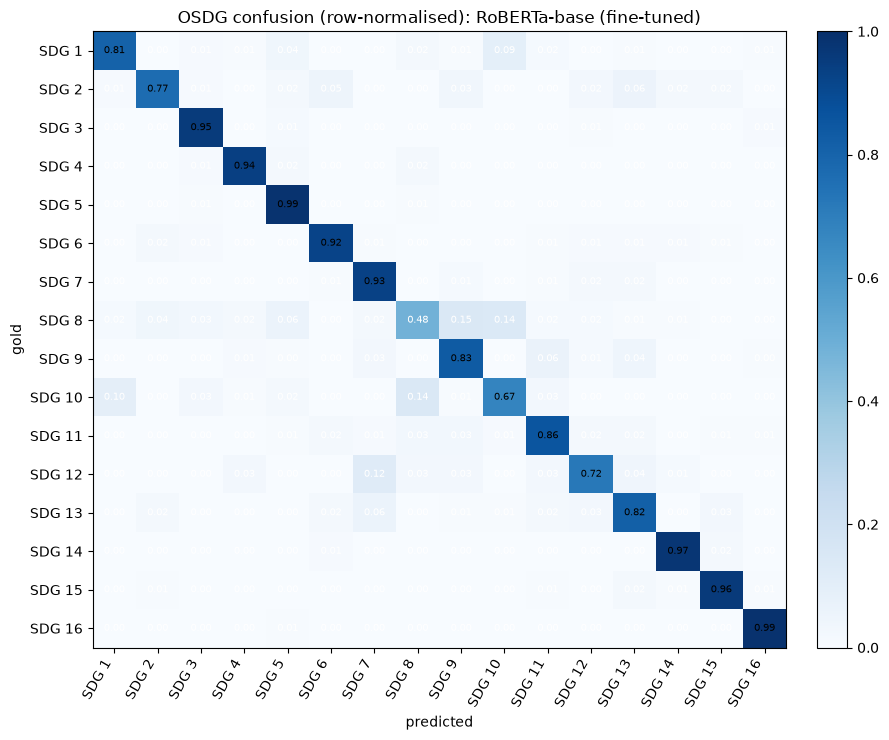

Most frequent confusions, best own-trained model: RoBERTa-base (fine-tuned)


,gold,predicted,count,% of gold class
0,SDG 10,SDG 8,21,14.3%
1,SDG 8,SDG 9,19,14.5%
2,SDG 8,SDG 10,18,13.7%
3,SDG 1,SDG 10,18,9.1%
4,SDG 9,SDG 11,14,6.3%
5,SDG 10,SDG 1,14,9.5%
6,SDG 9,SDG 13,10,4.5%
7,SDG 12,SDG 7,9,12.0%


In [28]:
CONF = {n: confusion_matrix(y_te_A, rep(ps)["test"].argmax(1), labels=list(range(K))) for n, ps in A_SCORES.items()}

def top_pairs(cm, n=8):
    off = cm.copy().astype(float); np.fill_diagonal(off, 0)
    rows = [{"gold": SDG_LABELS[i], "predicted": SDG_LABELS[j], "count": int(off[i, j]), "% of gold class": f"{off[i, j] / cm[i].sum():.1%}"}
            for i, j in zip(*np.unravel_index(np.argsort(-off, axis=None)[:n], off.shape))]
    return pd.DataFrame(rows)

own_A = [n for n in A_SCORES if n not in OFFSHELF and n not in LORA_A]
best_name_A = max(own_A, key=lambda n: np.mean([metrics_A(y_te_A, s["test"])["macro_f1"] for s in A_SCORES[n].values()]))
cm = CONF[best_name_A]                                  # confusion matrices of all models are used in 9.2; only the best own model is plotted
plot_heatmap(cm / cm.sum(1, keepdims=True).clip(min=1), SDG_LABELS, SDG_LABELS, f"OSDG confusion (row-normalised): {best_name_A}",
             OUT / "figs" / f"confusion_{safe(best_name_A)}.png", fmt="{:.2f}", cmap="Blues", vmin=0, vmax=1, xlab="predicted", ylab="gold", figsize=(9, 7.5))
print("Most frequent confusions, best own-trained model:", best_name_A)
save_table(top_pairs(cm), "top_confusions_A", index=False)

### 6.3 SDG co-occurrence in SDGi

Using SDGi train and val, we count how often two SDGs appear in the same document. The heatmap shows P(column SDG | row SDG), and the table lists the most frequent pairs. We compare these pairs by eye with the most confused pairs in Setting A, to see whether the models mix up goals that also tend to occur together.

SDGi train+dev: 3987 documents, 11.5% have more than one SDG, label cardinality 1.353


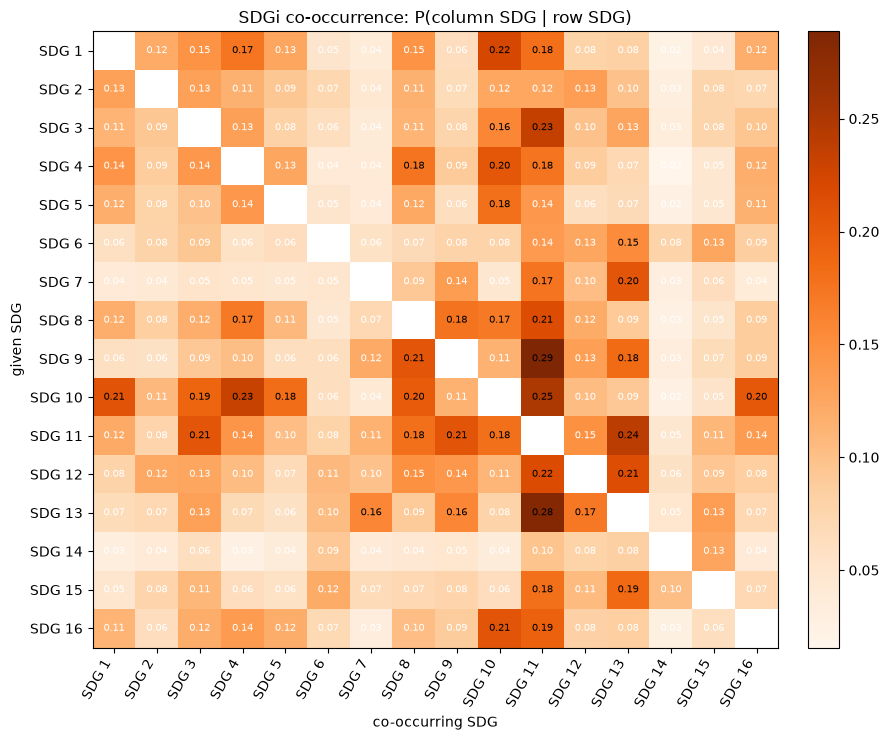

,pair,co-occurrences
0,SDG 11 + SDG 13,112
1,SDG 9 + SDG 11,97
2,SDG 3 + SDG 11,96
3,SDG 8 + SDG 11,84
4,SDG 10 + SDG 11,84
5,SDG 4 + SDG 10,78
6,SDG 1 + SDG 10,70
7,SDG 8 + SDG 9,69


In [44]:
Y_all = np.vstack([Y_sdgi_tr, Y_sdgi_dev])             # exploratory statistics use train + dev only; the test set stays reserved for the final evaluation
cooc = Y_all.T @ Y_all
cond = cooc / np.diag(cooc)[:, None]                                # P(column SDG | row SDG)
print(f"SDGi train+dev: {len(Y_all)} documents, {(Y_all.sum(1) > 1).mean():.1%} have more than one SDG, label cardinality {Y_all.sum(1).mean():.3f}")
cond_plot = cond.copy(); np.fill_diagonal(cond_plot, np.nan)
plot_heatmap(cond_plot, SDG_LABELS, SDG_LABELS, "SDGi co-occurrence: P(column SDG | row SDG)", OUT / "figs" / "sdgi_cooccurrence.png",
             fmt="{:.2f}", cmap="Oranges", xlab="co-occurring SDG", ylab="given SDG", figsize=(9, 7.5))
offc = np.triu(cooc.astype(float) - np.diag(np.diag(cooc)))
save_table(pd.DataFrame([{"pair": f"{SDG_LABELS[i]} + {SDG_LABELS[j]}", "co-occurrences": int(offc[i, j])}
                         for i, j in zip(*np.unravel_index(np.argsort(-offc, axis=None)[:8], offc.shape))]), "top_cooccurrences_sdgi", index=False)

### 6.4 Error analysis

For the best SDGi-trained model, on the English test documents, Table E2 gives an error profile per SDG: true positives, missed (FN) and spurious (FP) labels, precision, recall, F1 and the ratio of predicted to gold labels (over- vs under-prediction). Two further columns show which SDG is predicted instead when a goal is missed, and which gold SDG co-occurs when the model raises a false alarm, to see whether errors come from related goals. Example errors are saved to a CSV for the qualitative discussion.

In [36]:
# ---- Table E2: per-SDG error profile in Setting B
TP = ((Ye == 1) & (Pe == 1)).sum(0); FN = ((Ye == 1) & (Pe == 0)).sum(0); FP = ((Ye == 0) & (Pe == 1)).sum(0)
short = [s.split(":")[0] for s in SDG_LABELS]

def top_partner(mask_docs, other_mat, k):
    """Among the given documents, the SDG j != k most often flagged in other_mat, with its share of those documents."""
    if mask_docs.sum() == 0:
        return "-"
    cnt = other_mat[mask_docs].sum(0).astype(float); cnt[k] = 0
    j = int(cnt.argmax())
    return f"{short[j]} ({cnt[j] / mask_docs.sum():.0%})" if cnt[j] > 0 else "-"

spur = (Ye == 0) & (Pe == 1)          # spurious predictions
rows = []
for k in range(K):
    prec = TP[k] / max(TP[k] + FP[k], 1); rec = TP[k] / max(TP[k] + FN[k], 1)
    rows.append({
        "SDG": SDG_LABELS[k], "gold": int(Ye[:, k].sum()), "predicted": int(Pe[:, k].sum()),
        "TP": int(TP[k]), "FN": int(FN[k]), "FP": int(FP[k]),
        "precision": round(prec, 3), "recall": round(rec, 3),
        "F1": round(2 * prec * rec / max(prec + rec, 1e-12), 3),
        "pred / gold": round(Pe[:, k].sum() / max(Ye[:, k].sum(), 1), 2),             # >1 over-predicted, <1 under-predicted
        "when missed, predicted instead": top_partner((Ye[:, k] == 1) & (Pe[:, k] == 0), spur, k),
        "false alarms occur with gold": top_partner(spur[:, k], Ye, k),
    })
fp_fn = pd.DataFrame(rows).set_index("SDG").sort_values("F1")                          # hardest SDGs first
print(f"Table E2 - Setting B ({err_model_B}): error profile per SDG, hardest first. "
      "'pred / gold' > 1 means over-predicted, < 1 under-predicted.")
save_table(fp_fn, "errors_B_fp_fn_per_sdg")

Table E2 - Setting B (TF-IDF + LR (SDGi-trained)): error profile per SDG, hardest first. 'pred / gold' > 1 means over-predicted, < 1 under-predicted.


,gold,predicted,TP,FN,FP,precision,recall,F1,pred / gold,"when missed, predicted instead",false alarms occur with gold
SDG,,,,,,,,,,,
SDG 7,42,48,27,15,21,0.562,0.643,0.600,1.14,SDG 3 (13%),SDG 13 (38%)
SDG 15,62,39,35,27,4,0.897,0.565,0.693,0.63,SDG 11 (11%),SDG 2 (50%)
SDG 8,129,129,93,36,36,0.721,0.721,0.721,1.00,SDG 12 (17%),SDG 9 (36%)
SDG 3,91,85,64,27,21,0.753,0.703,0.727,0.93,SDG 11 (30%),SDG 11 (38%)
SDG 5,46,36,30,16,6,0.833,0.652,0.732,0.78,SDG 11 (38%),SDG 8 (33%)
SDG 9,108,100,77,31,23,0.770,0.713,0.740,0.93,SDG 11 (26%),SDG 11 (43%)
SDG 1,89,73,60,29,13,0.822,0.674,0.741,0.82,SDG 11 (10%),SDG 10 (46%)
SDG 2,63,44,40,23,4,0.909,0.635,0.748,0.70,SDG 3 (17%),SDG 8 (50%)
SDG 12,98,82,68,30,14,0.829,0.694,0.756,0.84,SDG 10 (13%),SDG 13 (50%)


### 6.5 SDGi subgroups: language insights
Micro-F1 of every model (representative seed, dev-tuned threshold) on each subgroup of the SDGi test set.
English-only models are expected to degrade on Spanish and French documents, and every model on documents with several gold SDGs.


In [42]:
# ------------------------------------------------------------------ Table 5: SDGi test, micro-F1 by language
rows = []
for g, idx in sdgi_test.groupby("lang").indices.items():
    if len(idx) < MIN_GROUP:
        continue
    row = {"language": str(g), "n": len(idx)}
    for name, ps in B_SCORES.items():
        row[name] = round(f1_score(Y_sdgi_te[idx], rep(ps)["P_tuned"][idx], average="micro", zero_division=0), 3)
    rows.append(row)
t5 = pd.DataFrame(rows).set_index("language")
print(f"Table 5 - SDGi test micro-F1 by language (languages with at least {MIN_GROUP} documents)")
save_table(t5, "table5_subgroups_B")

# ---- which model is best in which language?
model_cols = [c for c in t5.columns if c != "n"]
print("\nBest model per language (lead = gap to the runner-up):")
for lang, r in t5[model_cols].iterrows():
    s = r.sort_values(ascending=False)
    print(f"   {lang:>4} (n={int(t5.loc[lang, 'n']):>4}): {s.index[0]}  {s.iloc[0]:.3f}  (+{s.iloc[0] - s.iloc[1]:.3f} over {s.index[1]})")

others = [l for l in t5.index if l != "en"]
if "en" in t5.index and others:
    w = t5.loc[others, "n"]
    avg_other = (t5.loc[others, model_cols].mul(w, axis=0).sum() / w.sum()).sort_values(ascending=False)
    drop = (t5.loc["en", model_cols] - avg_other).reindex(avg_other.index)
    print(f"\nModels ranked by weighted mean micro-F1 on the non-English languages ({int(w.sum())} documents):")
    for n, v in avg_other.items():
        print(f"   {v:.3f}  {n}   (English {t5.loc['en', n]:.3f}, drop {drop[n]:+.3f})")

Table 5 - SDGi test micro-F1 by language (languages with at least 30 documents)


,n,TF-IDF + LR (OSDG-trained),TF-IDF + LR (SDGi-trained),RoBERTa-base (OSDG-trained),RoBERTa-base (SDGi-trained),sdgBERT (off-the-shelf),Qwen3.5-9B LoRA (OSDG-trained),Gemma-4-12B-QAT LoRA (OSDG-trained),Llama-3.1-8B-Instruct LoRA (OSDG-trained)
language,,,,,,,,,
en,965,0.607,0.751,0.620,0.739,0.599,0.678,0.676,0.640
es,208,0.170,0.401,0.380,0.535,0.232,0.676,0.670,0.630
fr,169,0.290,0.654,0.523,0.578,0.432,0.923,0.906,0.869



Best model per language (lead = gap to the runner-up):
     en (n= 965): TF-IDF + LR (SDGi-trained)  0.751  (+0.012 over RoBERTa-base (SDGi-trained))
     es (n= 208): Qwen3.5-9B LoRA (OSDG-trained)  0.676  (+0.006 over Gemma-4-12B-QAT LoRA (OSDG-trained))
     fr (n= 169): Qwen3.5-9B LoRA (OSDG-trained)  0.923  (+0.017 over Gemma-4-12B-QAT LoRA (OSDG-trained))

Models ranked by weighted mean micro-F1 on the non-English languages (377 documents):
   0.787  Qwen3.5-9B LoRA (OSDG-trained)   (English 0.678, drop -0.109)
   0.776  Gemma-4-12B-QAT LoRA (OSDG-trained)   (English 0.676, drop -0.100)
   0.737  Llama-3.1-8B-Instruct LoRA (OSDG-trained)   (English 0.640, drop -0.097)
   0.554  RoBERTa-base (SDGi-trained)   (English 0.739, drop +0.185)
   0.514  TF-IDF + LR (SDGi-trained)   (English 0.751, drop +0.237)
   0.444  RoBERTa-base (OSDG-trained)   (English 0.620, drop +0.176)
   0.322  sdgBERT (off-the-shelf)   (English 0.599, drop +0.277)
   0.224  TF-IDF + LR (OSDG-trained)   (Engli

## 7. Efficiency Summary

In [53]:
eff = pd.DataFrame(EFF_ROWS).groupby(["model", "task"], as_index=False).agg(
    params_M=("params", lambda x: x.mean() / 1e6), train_time_min=("train_time_s", lambda x: x.mean() / 60),
    infer_s_per_1k_texts=("infer_s_per_1k", "mean"), peak_gpu_GiB=("peak_gpu_gib", "mean"), device=("device", "first"))

print("Table 4 - efficiency (training time = mean over seeds; inference time measured on OSDG test paragraphs / SDGi test documents, incl. tokenisation)")
save_table(eff.round(3), "table4_efficiency", index=False)

Table 4 - efficiency (training time = mean over seeds; inference time measured on OSDG test paragraphs / SDGi test documents, incl. tokenisation)


,model,task,params_M,train_time_min,infer_s_per_1k_texts,peak_gpu_GiB,device
0,Gemma-4-12B-QAT LoRA (fine-tuned),OSDG (multi-class),6575.325,71.325,167.455,8.840,NVIDIA L4
1,Llama-3.1-8B-Instruct LoRA (fine-tuned),OSDG (multi-class),4670.624,42.441,102.742,7.707,NVIDIA L4
2,Qwen3.5-9B LoRA (fine-tuned),OSDG (multi-class),5979.660,44.345,104.866,13.449,NVIDIA L4
3,RoBERTa-base,OSDG (multi-class),124.658,11.292,2.020,3.233,NVIDIA GeForce RTX 5060 Laptop GPU
4,RoBERTa-base,"SDGi (multi-label, chunks)",124.658,21.030,2.539,3.238,NVIDIA GeForce RTX 5060 Laptop GPU
5,TF-IDF + LR,OSDG (multi-class),2.474,0.414,0.153,NaN,CPU
6,TF-IDF + LR,SDGi (multi-label),3.200,0.420,3.425,NaN,CPU
7,google/gemma-4-12b-qat (A-few),"plain LLM, no training (LM Studio)",NaN,0.000,4594.617,NaN,NVIDIA GeForce RTX 5060 Laptop GPU via LM Studio
8,google/gemma-4-12b-qat (A-zero),"plain LLM, no training (LM Studio)",NaN,0.000,2456.864,NaN,NVIDIA GeForce RTX 5060 Laptop GPU via LM Studio
9,google/gemma-4-12b-qat (B-zero),"plain LLM, no training (LM Studio)",NaN,0.000,3840.366,NaN,NVIDIA GeForce RTX 5060 Laptop GPU via LM Studio
